# Prediksi Churn Pelanggan E-Commerce dengan Machine Learning

<a id="ringkasan-eksekutif"></a>
## RINGKASAN EKSEKUTIF

Pada bisnis *e-commerce*, biaya mempertahankan pelanggan jauh lebih kecil daripada biaya mendapatkan pelanggan baru, tetapi tim *Customer Retention* belum memiliki cara yang andal untuk mengetahui **pelanggan mana yang berisiko churn** sebelum mereka benar-benar pergi. Notebook ini membangun **model klasifikasi biner** (`Churn` = 1/0) dari data profil dan perilaku pelanggan, dengan alur: pembersihan data tanpa kebocoran informasi → *stratified split* → *pipeline* (preprocessing → SMOTE → model) → *benchmarking*, *tuning*, dan pemilihan model berdasarkan kestabilan → *threshold* berbasis biaya → evaluasi pada *test set* → segmentasi risiko, rencana A/B test, *deployment*, dan *monitoring*.

Hasil teknis yang terukur (Recall, Precision, F1, ROC-AUC, PR-AUC beserta *confidence interval* bootstrap), pengecekan *success criteria*, dan **status kesiapan model** dihitung otomatis saat notebook dijalankan dan ditampilkan pada [9.2.2](#bab-9-2-2) dan [9.2.4](#bab-9-2-4); angkanya sengaja tidak ditulis di sini agar tidak berbeda dengan hasil eksekusi.

Empat hal yang perlu dibaca bersama hasil tersebut:

1. **Angka rupiah adalah simulasi asumsi** (biaya kampanye, nilai pelanggan, *success rate*), bukan hasil aktual; manfaat bisnis baru terbukti setelah A/B test ([7.2](#bab-7-2)).
2. **Waktu pencatatan fitur belum dikonfirmasi** tim data, sehingga risiko *temporal leakage* hanya dinilai lewat *ablation* ([3.3.2](#bab-3-3-2), [6.4.6](#bab-6-4-6)).
3. **Data tidak bertanggal**, sehingga tidak ada validasi berbasis waktu dan tidak boleh diklaim ([3.6.2](#bab-3-6-2)).
4. **Interpretasi model adalah asosiasi**, bukan sebab-akibat ([6.2.3](#bab-6-2-3)).


<a id="daftar-isi"></a>
## DAFTAR ISI

- [Ringkasan Eksekutif](#ringkasan-eksekutif)
- [Daftar Isi](#daftar-isi)
- [1. Business Understanding](#bab-1)
   - [1.1 Background dan Konteks Bisnis](#bab-1-1)
   - [1.2 Problem Statement dan Tujuan Proyek](#bab-1-2)
      - [1.2.1 Tujuan Proyek (Goal)](#bab-1-2-1)
   - [1.3 Definisi Churn dan Unit Analisis](#bab-1-3)
   - [1.4 Analytic Approach dan Evaluation Metrics](#bab-1-4)
   - [1.5 Success Criteria](#bab-1-5)
   - [1.6 Batasan dan Asumsi Awal](#bab-1-6)
      - [1.6.1 Definisi churn dan waktu pengukuran fitur (perlu dikonfirmasi tim data)](#bab-1-6-1)
      - [1.6.2 Batasan lain yang diketahui sejak awal](#bab-1-6-2)
- [2. Import Libraries & Configuration](#bab-2)
   - [2.1 Import Library](#bab-2-1)
   - [2.2 Random Seed, Konfigurasi Eksperimen, Path, dan Parameter](#bab-2-2)
- [3. Data Preparation](#bab-3)
   - [3.1 Data Collection](#bab-3-1)
      - [3.1.1 Memuat Dataset](#bab-3-1-1)
      - [3.1.2 Sumber, Periode, dan Cakupan Data](#bab-3-1-2)
      - [3.1.3 Pemeriksaan Awal Keberhasilan Pemuatan Data](#bab-3-1-3)
   - [3.2 Data Understanding](#bab-3-2)
      - [3.2.1 Dimensi dan Struktur Dataset](#bab-3-2-1)
      - [3.2.2 Data Dictionary dan Makna Bisnis Fitur](#bab-3-2-2)
      - [3.2.3 Statistik Deskriptif](#bab-3-2-3)
      - [3.2.4 Distribusi Target Churn](#bab-3-2-4)
   - [3.3 Feature Availability & Data Quality Assessment](#bab-3-3)
      - [3.3.1 Feature Availability Registry (Registri Ketersediaan Fitur)](#bab-3-3-1)
      - [3.3.2 Definisi Ketersediaan Fitur dan Pemeriksaan Potensi Leakage](#bab-3-3-2)
      - [3.3.3 Pemeriksaan Missing Value, Duplikasi, dan Inkonsistensi Awal](#bab-3-3-3)
         - [3.3.3.1 Missing Value](#bab-3-3-3-1)
         - [3.3.3.2 Duplikasi](#bab-3-3-3-2)
         - [3.3.3.3 Tipe Data dan Konsistensi Kategori](#bab-3-3-3-3)
   - [3.4 Data Cleaning](#bab-3-4)
      - [3.4.1 Penanganan Missing Values](#bab-3-4-1)
      - [3.4.2 Pemeriksaan dan Penanganan Duplikasi](#bab-3-4-2)
      - [3.4.3 Standarisasi Kategori dan Tipe Data](#bab-3-4-3)
      - [3.4.4 Pemeriksaan Outlier Berdasarkan Konteks Bisnis](#bab-3-4-4)
      - [3.4.5 Dokumentasi Aturan Cleaning](#bab-3-4-5)
      - [3.4.6 Menyimpan Data Bersih](#bab-3-4-6)
   - [3.5 Final Data Quality Report](#bab-3-5)
      - [3.5.1 Isu Data yang Belum Terselesaikan](#bab-3-5-1)
   - [3.6 Define Features, Target & Data Splitting](#bab-3-6)
      - [3.6.1 Menentukan Target dan Fitur Prediktor](#bab-3-6-1)
      - [3.6.2 Strategi Split](#bab-3-6-2)
         - [3.6.2.1 Jika Tanggal Tersedia: Split Berbasis Waktu](#bab-3-6-2-1)
- [4. Exploratory Data Analysis (EDA)](#bab-4)
   - [4.1 Univariate Analysis](#bab-4-1)
      - [4.1.1 Target](#bab-4-1-1)
      - [4.1.2 Numerical Features](#bab-4-1-2)
      - [4.1.3 Categorical Features](#bab-4-1-3)
   - [4.2 Bivariate Analysis](#bab-4-2)
      - [4.2.1 Numerical Features vs Target](#bab-4-2-1)
      - [4.2.2 Pola Pelanggan: Tenure × Complain terhadap Churn](#bab-4-2-2)
      - [4.2.3 Categorical Features vs Target](#bab-4-2-3)
   - [4.3 Insight yang Relevan terhadap Keputusan Bisnis](#bab-4-3)
- [5. Model Development](#bab-5)
   - [5.1 Feature Engineering & Preprocessing](#bab-5-1)
      - [5.1.1 Pembuatan Fitur yang Didukung Data](#bab-5-1-1)
      - [5.1.2 Encoding, Scaling, dan Imputation dalam Pipeline](#bab-5-1-2)
      - [5.1.3 Prinsip Anti-Leakage pada Preprocessing](#bab-5-1-3)
   - [5.2 Imbalance Handling Experiments](#bab-5-2)
      - [5.2.1 Hasil Perbandingan (XGBoost bawaan)](#bab-5-2-1)
   - [5.3 Model Benchmarking](#bab-5-3)
      - [5.3.1 Menentukan Model Baseline](#bab-5-3-1)
      - [5.3.2 Membandingkan Kandidat Algoritma dengan Cross-Validation](#bab-5-3-2)
   - [5.4 Algorithm Explanation](#bab-5-4)
      - [5.4.1 Asumsi dan Karakteristik Algoritma](#bab-5-4-1)
      - [5.4.2 Alasan Pemilihan Kandidat](#bab-5-4-2)
   - [5.5 Hyperparameter Tuning](#bab-5-5)
      - [5.5.1 Ruang Pencarian Parameter dan Prosedur Tuning](#bab-5-5-1)
      - [5.5.2 Mencatat Konfigurasi dan Hasil Terbaik](#bab-5-5-2)
   - [5.6 Overfitting Experiments & Final Model Selection](#bab-5-6)
      - [5.6.1 XGBoost Sederhana & Teregularisasi (Grid Search)](#bab-5-6-1)
      - [5.6.2 *Early Stopping* (validasi internal asli)](#bab-5-6-2)
      - [5.6.3 Perbandingan Kandidat (Train vs CV) & Pemilihan Model Final](#bab-5-6-3)
      - [5.6.4 Konfirmasi Strategi Imbalance pada Model Teregularisasi](#bab-5-6-4)
      - [5.6.5 Model Final (dilatih hanya pada data train)](#bab-5-6-5)
- [6. Model Evaluation & Business Impact](#bab-6)
   - [6.1 Model Evaluation](#bab-6-1)
      - [6.1.1 Evaluasi pada Test Set (threshold 0.5 sebagai baseline referensi)](#bab-6-1-1)
      - [6.1.2 Pemilihan Threshold dan Evaluasi Dampaknya](#bab-6-1-2)
   - [6.2 Model Interpretation](#bab-6-2)
      - [6.2.1 Feature Importance](#bab-6-2-1)
      - [6.2.2 SHAP Value](#bab-6-2-2)
      - [6.2.3 Interpretasi sebagai Asosiasi, Bukan Sebab-Akibat](#bab-6-2-3)
   - [6.3 Business & Cost-Benefit Evaluation](#bab-6-3)
      - [6.3.1 Definisi Biaya Kampanye, Margin Kontribusi, dan Biaya FP/FN](#bab-6-3-1)
      - [6.3.2 Threshold Berdasarkan Biaya/Manfaat](#bab-6-3-2)
      - [6.3.3 Evaluasi pada Test Set: Tiga Skenario Biaya](#bab-6-3-3)
      - [6.3.4 Confusion Matrix pada Threshold Final](#bab-6-3-4)
      - [6.3.5 Net Incremental Profit dan ROI (Simulasi)](#bab-6-3-5)
      - [6.3.6 Sensitivity Analysis Asumsi Bisnis](#bab-6-3-6)
   - [6.4 Statistical Reliability & Calibration](#bab-6-4)
      - [6.4.1 Ketidakpastian Hasil Test (Bootstrap Confidence Interval)](#bab-6-4-1)
      - [6.4.2 Pengecekan Success Criteria](#bab-6-4-2)
      - [6.4.3 Laporan Metrik Lengkap (termasuk *Accuracy*)](#bab-6-4-3)
      - [6.4.4 Analisis Sensitivitas Threshold](#bab-6-4-4)
      - [6.4.5 Kalibrasi Probabilitas](#bab-6-4-5)
      - [6.4.6 Uji Sensitivitas Keputusan Data (Duplikat dan Fitur Berisiko Temporal Leakage)](#bab-6-4-6)
         - [6.4.6.1 Dengan vs Tanpa Duplikat](#bab-6-4-6-1)
         - [6.4.6.2 Ablation Fitur yang Waktu Pencatatannya Belum Jelas](#bab-6-4-6-2)
- [7. Retention Strategy & A/B Test Plan](#bab-7)
   - [7.1 Customer Risk Segmentation & Retention Strategy](#bab-7-1)
      - [7.1.1 Segmentasi Berdasarkan Churn Risk](#bab-7-1-1)
      - [7.1.2 Penggabungan Risiko dengan Customer Value dan Retention Uplift](#bab-7-1-2)
      - [7.1.3 Rekomendasi Tindakan dan Batas Anggaran per Segmen](#bab-7-1-3)
   - [7.2 A/B Testing & Business Impact Validation Plan](#bab-7-2)
      - [7.2.1 Hipotesis dan Populasi](#bab-7-2-1)
      - [7.2.2 Randomisasi](#bab-7-2-2)
      - [7.2.3 Metrik](#bab-7-2-3)
      - [7.2.4 Kriteria Penghentian](#bab-7-2-4)
      - [7.2.5 Rencana Analisis Hasil](#bab-7-2-5)
      - [7.2.6 Perkiraan Ukuran Sampel dan Durasi](#bab-7-2-6)
- [8. Deployment & Operations](#bab-8)
   - [8.1 Model Deployment](#bab-8-1)
      - [8.1.1 Menyimpan Model dan Preprocessing Pipeline](#bab-8-1-1)
      - [8.1.2 Versioning Model (Registri)](#bab-8-1-2)
      - [8.1.3 Prediction Function / Batch Scoring dan Validasi Input-Output](#bab-8-1-3)
      - [8.1.4 Dokumentasi Penggunaan](#bab-8-1-4)
      - [8.1.5 API (Opsional)](#bab-8-1-5)
   - [8.2 Monitoring, Retraining & Rollback](#bab-8-2)
      - [8.2.1 Cakupan Pemantauan](#bab-8-2-1)
      - [8.2.2 Data Quality Monitoring](#bab-8-2-2)
      - [8.2.3 Data Drift / PSI dan Model Performance Monitoring](#bab-8-2-3)
      - [8.2.4 Business KPI Monitoring](#bab-8-2-4)
      - [8.2.5 Jadwal Pemantauan dan Pemicu Retraining](#bab-8-2-5)
      - [8.2.6 Kriteria Rollback dan Prosedur Pemulihan](#bab-8-2-6)
- [9. Penutup](#bab-9)
   - [9.1 Limitations & Future Improvements](#bab-9-1)
      - [9.1.1 Rentang Nilai dan Kategori Data Latih](#bab-9-1-1)
      - [9.1.2 Keterbatasan](#bab-9-1-2)
         - [9.1.2.1 Dataset dan representativitas](#bab-9-1-2-1)
         - [9.1.2.2 Validasi temporal](#bab-9-1-2-2)
         - [9.1.2.3 Asumsi cost-benefit](#bab-9-1-2-3)
         - [9.1.2.4 Kausalitas dan generalisasi](#bab-9-1-2-4)
      - [9.1.3 Future Improvements dan Kebutuhan Data/Eksperimen Lanjutan](#bab-9-1-3)
   - [9.2 Conclusion & Executive Summary](#bab-9-2)
      - [9.2.1 Ringkasan Masalah dan Pendekatan](#bab-9-2-1)
      - [9.2.2 Hasil Teknis yang Terukur (data aktual, test set)](#bab-9-2-2)
      - [9.2.3 Ringkasan Eksekutif](#bab-9-2-3)
      - [9.2.4 Hasil Bisnis: Terbukti vs Estimasi vs Masih Direncanakan](#bab-9-2-4)
      - [9.2.5 Kesimpulan](#bab-9-2-5)
      - [9.2.6 Rekomendasi dan Langkah Berikutnya](#bab-9-2-6)
      - [9.2.7 Lampiran — Status Tindak Lanjut Rekomendasi Perbaikan](#bab-9-2-7)

<a id="bab-1"></a>
# 1. BUSINESS UNDERSTANDING

<a id="bab-1-1"></a>
## 1.1 Background dan Konteks Bisnis

Persaingan di industri *e-commerce* sangat ketat, sementara biaya untuk **mendapatkan pelanggan baru jauh lebih mahal** daripada biaya mempertahankan pelanggan yang sudah ada. Setiap pelanggan yang berhenti berbelanja (*churn*) bukan hanya menghilangkan pendapatan dari transaksi berikutnya, tetapi juga menghanguskan biaya akuisisi (iklan, promo, cashback awal) yang sudah dikeluarkan.

Platform *e-commerce* sebenarnya sudah menyimpan jejak perilaku pelanggan yang kaya: lama menjadi pelanggan (*tenure*), jarak gudang ke rumah, jumlah perangkat yang terdaftar, kategori belanja favorit, skor kepuasan, riwayat komplain, jeda sejak pesanan terakhir, hingga nilai *cashback* yang diterima. Jika data ini dianalisis dengan pendekatan *machine learning*, tim *Customer Retention* dapat mengetahui **siapa yang berisiko pergi sebelum mereka benar-benar pergi**, lalu memberi intervensi (promo, voucher, layanan prioritas) secara tepat sasaran.

<a id="bab-1-2"></a>
## 1.2 Problem Statement dan Tujuan Proyek

Tim bisnis saat ini tidak memiliki cara yang andal untuk membedakan pelanggan yang **akan churn** dengan pelanggan yang **akan tetap loyal**. Akibatnya ada dua pilihan yang sama-sama buruk:

* **Tidak melakukan apa-apa** → pelanggan berisiko pergi tanpa sempat diselamatkan.
* **Memberi promo ke semua pelanggan** → anggaran retensi terbuang pada pelanggan yang sebenarnya tidak akan churn.

**Tanpa model prediktif berbasis *machine learning* yang andal, program retensi akan tetap bersifat reaktif, tidak efisien, dan tidak terukur dampak finansialnya.**

---

<a id="bab-1-2-1"></a>
### 1.2.1 Tujuan Proyek (Goal)

Mengembangkan **model klasifikasi biner (*Customer Churn Prediction*)** untuk memprediksi apakah seorang pelanggan akan churn (`Churn = 1`) atau tidak (`Churn = 0`), dengan tujuan:

* **Deteksi dini pelanggan berisiko:** menangkap sebanyak mungkin pelanggan yang akan churn (*Recall* tinggi, dengan target terukur pada bagian *Success Criteria*) agar tim retensi dapat bertindak lebih awal.
* **Efisiensi anggaran retensi:** menjaga *Precision* tetap wajar supaya promo tidak banyak terbuang pada pelanggan yang sebenarnya loyal.
* **Memahami pendorong churn:** mengidentifikasi faktor perilaku yang paling berpengaruh (melalui *feature importance* dan SHAP) sebagai dasar rekomendasi bisnis.
* **Mengukur dampak finansial:** membandingkan biaya dengan model vs tanpa model melalui *Cost-Benefit Analysis*.

<a id="bab-1-3"></a>
## 1.3 Definisi Churn dan Unit Analisis

* **Unit analisis:** satu baris data = **satu pelanggan** (dataset tidak memiliki ID pelanggan).
* **Target:** `Churn = 1` berarti pelanggan berhenti berbelanja; `Churn = 0` berarti pelanggan tetap berbelanja.
* **Definisi operasional churn** (mis. "tidak bertransaksi selama N hari/bulan") **tidak tercantum** di dataset dan perlu dikonfirmasi tim data; lihat *Batasan dan Asumsi Awal* di bawah.

<a id="bab-1-4"></a>
## 1.4 Analytic Approach dan Evaluation Metrics

* **Tipe masalah:** klasifikasi biner dengan kelas **tidak seimbang** (*imbalanced*) — pelanggan churn adalah kelas minoritas.
* **Peran tiap metrik (dibuat konsisten di seluruh notebook):**

| Tahap | Metrik | Alasan |
| :--- | :--- | :--- |
| Pemilihan & tuning model (*cross validation*) | **F1-Score** kelas churn (didukung ROC-AUC) | Menyeimbangkan *Precision* dan *Recall*; *Recall* murni bisa dicapai dengan menandai semua pelanggan sebagai churn. |
| Pemilihan *threshold* | **Total biaya** (*Cost-Benefit*) pada *out-of-fold prediction* data *train* | Biaya FN jauh lebih besar daripada FP. |
| Penilaian akhir (*test set*) | ***Success criteria*** (lihat di bawah): **Recall** minimum, **Precision** minimum, dan penghematan biaya | *Recall* diperlakukan sebagai **syarat minimum yang harus dipenuhi**, bukan metrik yang dioptimasi langsung. |
| Pendukung | ROC-AUC, PR-AUC | Independen terhadap *threshold*. |

* ***Accuracy* tidak dijadikan acuan** karena model yang menebak "tidak churn" untuk semua pelanggan pun sudah mendapat akurasi tinggi.
* **Asumsi biaya kesalahan:**
    * ***False Negative* (FN)** — pelanggan churn yang lolos dari deteksi → pendapatan pelanggan tersebut hilang.
    * ***False Positive* (FP)** — pelanggan loyal yang dikira akan churn → biaya promo/kampanye retensi terbuang.
    * Biaya FN lebih besar daripada FP, sehingga model sebaiknya condong ke *Recall* — tetapi tidak sampai menandai semua orang sebagai churn.

<a id="bab-1-5"></a>
## 1.5 Success Criteria

Kriteria berikut ditetapkan **sebelum** melihat hasil *test set* dan dicek otomatis pada bagian 6.4 (*Statistical Reliability & Calibration*):

| # | Kriteria | Target | Catatan |
| :-: | :--- | :--- | :--- |
| 1 | *Recall* kelas churn pada *test set* | **≥ 0,70** | Tujuan utama: mendeteksi dini pelanggan berisiko. |
| 2 | *Precision* kelas churn pada *test set* | **≥ 0,50** | **Asumsi** — setidaknya separuh pelanggan yang ditargetkan memang akan churn. Sesuaikan dengan anggaran retensi. |
| 3 | Biaya dengan model | **lebih rendah** daripada "tanpa kampanye" **dan** "kampanye ke semua pelanggan" | Memakai asumsi biaya pada bagian 6.3 (*Business & Cost-Benefit Evaluation*). |

Setiap kriteria dinilai dua kali: (a) berdasarkan **estimasi titik** dan (b) berdasarkan **batas bawah *confidence interval* 95%** (bootstrap). Kriteria dianggap **kokoh** hanya jika (b) juga terpenuhi, karena *test set* kecil membuat hasil bisa bergeser beberapa poin hanya karena pembagian data.

<a id="bab-1-6"></a>
## 1.6 Batasan dan Asumsi Awal

<a id="bab-1-6-1"></a>
### 1.6.1 Definisi churn dan waktu pengukuran fitur (perlu dikonfirmasi tim data)

Dataset **tidak mencantumkan** (1) definisi `Churn` (mis. "tidak bertransaksi selama N hari/bulan"), dan (2) **kapan** setiap fitur dicatat relatif terhadap saat label churn ditetapkan. Dua hal ini menentukan validitas model:

* Jika fitur dicatat **sebelum** pelanggan memutuskan berhenti → model benar-benar memprediksi churn lebih awal (sesuai tujuan).
* Jika fitur dicatat **sesudah** pelanggan berhenti atau sudah dipengaruhi oleh keputusan berhenti → terjadi ***temporal leakage***: model memakai akibat churn sebagai "sinyal", skor evaluasi tampak bagus, tetapi model tidak bisa dipakai untuk prediksi dini.

**Asumsi kerja notebook ini:** seluruh fitur adalah *snapshot* perilaku/profil yang tercatat **sebelum** periode pengamatan churn dimulai, dan `Churn` adalah status pada periode sesudahnya. **Asumsi ini belum terverifikasi.**

<a id="bab-1-6-2"></a>
### 1.6.2 Batasan lain yang diketahui sejak awal

* **Tanpa tanggal dan ID pelanggan:** data adalah satu potret (*snapshot*); validasi berbasis waktu tidak dapat dilakukan dan tidak boleh diklaim.
* **Ukuran data kecil dan kelas minoritas:** estimasi performa memiliki ketidakpastian yang perlu dikuantifikasi (*confidence interval*).
* **Nilai rupiah (biaya kampanye, nilai pelanggan, *success rate*) adalah asumsi** sampai diganti angka riil dan divalidasi lewat A/B test.
* **Hasil model adalah pola prediktif (asosiasi)**, bukan bukti sebab-akibat.

<a id="bab-2"></a>
# 2. IMPORT LIBRARIES & CONFIGURATION

<a id="bab-2-1"></a>
## 2.1 Import Library

In [77]:
# data manipulation
import pandas as pd
import numpy as np

# data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# pipeline & imbalance handling
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, RandomOverSampler, SMOTENC

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler

# cross validation & tuning
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, StratifiedGroupKFold, train_test_split,
                                     cross_validate, cross_val_predict)

# metric evaluation
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score, roc_auc_score,
                             average_precision_score, classification_report, confusion_matrix, brier_score_loss,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

# klasifikasi
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# utilitas, interpretasi, dan kalibrasi
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from pathlib import Path

# kalibrasi, penyimpanan model
from sklearn.calibration import calibration_curve
import joblib, os, datetime, json
from importlib import metadata as importlib_metadata

from scipy.stats import norm
from IPython.display import Markdown

# interpretasi model
import shap

# handle warning
import warnings
warnings.filterwarnings('ignore')

def get_palette(n, cmap_name='Blues'):
    """Generate n colors from a matplotlib colormap (skip shade paling terang)."""
    cmap = plt.get_cmap(cmap_name, n + 3)
    return [cmap(i + 2) for i in range(n)][::-1]

<a id="bab-2-2"></a>
## 2.2 Random Seed, Konfigurasi Eksperimen, Path, dan Parameter

In [78]:
# ============================ KONFIGURASI EKSPERIMEN ============================
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Path & nama file ---
DATA_FILENAME      = 'data_ecommerce_customer_churn.csv'
CLEAN_DATA_PATH    = 'ecommerce_churn_clean.csv'
DQ_REPORT_PATH     = 'data_quality_report.csv'
TUNING_RESULT_PATH = 'hyperparameter_tuning_results.csv'
MODEL_DIR          = 'model_artifacts'

# --- Skema validasi silang: SATU skema yang sama dipakai di seluruh notebook ---
CV_SPLITS   = 5
cv          = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring     = {'recall': 'recall', 'precision': 'precision', 'f1': 'f1',
               'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}
OVERFIT_GAP = 0.15          # selisih F1 train-CV di atas nilai ini ditandai OVERFIT
TEST_SIZE   = 0.2

# --- Success criteria: ditetapkan SEBELUM melihat hasil test set ---
SUCCESS_CRITERIA = {
    'min_recall'   : 0.70,   # kriteria 1 - target bisnis
    'min_precision': 0.50,   # kriteria 2 - ASUMSI, sesuaikan dengan anggaran retensi
}
# Kriteria 3 (biaya dengan model < dua skenario pembanding) dicek pada bagian 6.3-6.4.

# --- Informasi lingkungan (untuk reproduktibilitas) ---
import sys, platform
def _pkg_version(pkg):
    try:
        return importlib_metadata.version(pkg)
    except Exception:
        return 'tidak terpasang'
print(f"Python {platform.python_version()} | seed = {RANDOM_STATE} | CV = Stratified {CV_SPLITS}-Fold | test_size = {TEST_SIZE}")
print({p: _pkg_version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'imbalanced-learn', 'xgboost', 'lightgbm', 'shap']})
print('SUCCESS_CRITERIA =', SUCCESS_CRITERIA)

Python 3.14.6 | seed = 42 | CV = Stratified 5-Fold | test_size = 0.2
{'pandas': '3.0.3', 'numpy': '2.4.6', 'scikit-learn': '1.9.0', 'imbalanced-learn': '0.14.2', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'shap': '0.54.1'}
SUCCESS_CRITERIA = {'min_recall': 0.7, 'min_precision': 0.5}


<a id="bab-3"></a>
# 3. DATA PREPARATION

<a id="bab-3-1"></a>
## 3.1 Data Collection

<a id="bab-3-1-1"></a>
### 3.1.1 Memuat Dataset

Dataset berisi **data perilaku & profil pelanggan *e-commerce*** beserta label `Churn` (1 = pelanggan berhenti, 0 = pelanggan tetap). Satu baris mewakili satu pelanggan. Data dibaca dari file CSV.

In [79]:
# Nama file data (DATA_FILENAME) diatur pada bagian 2.
# Notebook mencari file di folder kerja, subfolder data/, lalu folder upload.
from pathlib import Path

candidates = [Path(DATA_FILENAME), Path('data') / DATA_FILENAME, Path('/mnt/user-data/uploads') / DATA_FILENAME]
data_path = next((p for p in candidates if p.exists()), None)

if data_path is None:
    found = sorted(str(p) for p in Path('.').glob('**/*.csv'))[:10]
    raise FileNotFoundError(
        f"File '{DATA_FILENAME}' tidak ditemukan. Lokasi yang dicek: {[str(p) for p in candidates]}. "
        f"File CSV yang ada di sekitar notebook: {found}. Ubah DATA_FILENAME / letakkan file di folder yang sama."
    )

df = pd.read_csv(data_path)
print(f"File data: {data_path}")
print(f"Jumlah baris: {df.shape[0]:,} | Jumlah kolom: {df.shape[1]}")
df.head()

File data: data_ecommerce_customer_churn.csv
Jumlah baris: 3,941 | Jumlah kolom: 11


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


<a id="bab-3-1-2"></a>
### 3.1.2 Sumber, Periode, dan Cakupan Data

| Aspek | Keterangan |
| :--- | :--- |
| **Sumber** | File CSV `data_ecommerce_customer_churn.csv` (data perilaku dan profil pelanggan *e-commerce*). Sistem asal dan cara ekstraksi data **tidak tercantum** — dokumentasikan bila tersedia. |
| **Periode** | **Tidak diketahui**: dataset tidak memuat kolom tanggal/waktu observasi. |
| **Cakupan** | Satu baris per pelanggan; fitur perilaku, logistik, kepuasan, dan promo, beserta label `Churn`. Tidak ada ID pelanggan. |

<a id="bab-3-1-3"></a>
### 3.1.3 Pemeriksaan Awal Keberhasilan Pemuatan Data

In [80]:
# Pemeriksaan awal: data terbaca, target ada dan biner, ada/tidaknya kolom tanggal atau ID
assert len(df) > 0, "Dataset kosong"
assert 'Churn' in df.columns, "Kolom target 'Churn' tidak ditemukan"
assert set(df['Churn'].dropna().unique()) <= {0, 1}, "Target 'Churn' harus biner (0/1)"

date_or_id_cols = [c for c in df.columns
                   if any(k in c.lower() for k in ('date', 'tanggal', 'timestamp')) or c.lower() in ('id', 'customerid', 'customer_id')]
print(f"✔ Data berhasil dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"✔ Kolom: {list(df.columns)}")
print(f"✔ Target biner (0/1), nilai kosong pada target: {int(df['Churn'].isna().sum())}")
print(f"✔ Kolom tanggal / ID pelanggan: {date_or_id_cols if date_or_id_cols else 'tidak ada'}")

✔ Data berhasil dimuat: 3,941 baris x 11 kolom
✔ Kolom: ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount', 'Churn']
✔ Target biner (0/1), nilai kosong pada target: 0
✔ Kolom tanggal / ID pelanggan: tidak ada


<a id="bab-3-2"></a>
## 3.2 Data Understanding

<a id="bab-3-2-1"></a>
### 3.2.1 Dimensi dan Struktur Dataset

In [81]:
print(f"Dimensi dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom\n")
df.info()

Dimensi dataset: 3,941 baris x 11 kolom

<class 'pandas.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   str    
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   str    
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 411.2 KB


<a id="bab-3-2-2"></a>
### 3.2.2 Data Dictionary dan Makna Bisnis Fitur

Berikut rincian informasi, tipe data, serta makna bisnis dari setiap kolom pada dataset:

| Nama Kolom | Tipe Data | Kategori | Deskripsi & Makna Bisnis | Catatan / Rencana Preprocessing |
| :--- | :--- | :--- | :--- | :--- |
| **`Churn`** | Binary (0/1) | Target | Status pelanggan:<br>• **0** = tetap berbelanja (*retained*)<br>• **1** = berhenti berbelanja (*churn*). | Kelas **imbalanced** (churn adalah minoritas) → perlu *resampling* / metrik selain *accuracy*. |
| **`Tenure`** | Numerical | Hubungan pelanggan | Lama pelanggan terdaftar di platform (dalam bulan). | Ada **missing value**. Biasanya prediktor churn terkuat. |
| **`WarehouseToHome`** | Numerical | Logistik | Jarak gudang ke rumah pelanggan. | Ada **missing value** dan *outlier* ekstrem. |
| **`NumberOfDeviceRegistered`** | Numerical (diskrit) | Perilaku | Jumlah perangkat yang terdaftar pada akun pelanggan. | Diperlakukan sebagai numerik. |
| **`PreferedOrderCat`** | Categorical | Perilaku | Kategori produk yang paling sering dipesan pelanggan. | Label **tidak konsisten** (`Mobile` vs `Mobile Phone`) → harus digabung. *One-Hot Encoding*. |
| **`SatisfactionScore`** | Ordinal (1–5) | Kepuasan | Skor kepuasan pelanggan terhadap layanan. | Sudah berupa angka berurutan; dipertahankan sebagai ordinal. |
| **`MaritalStatus`** | Categorical | Demografi | Status pernikahan pelanggan (`Single`, `Married`, `Divorced`). | *One-Hot Encoding*. |
| **`NumberOfAddress`** | Numerical (diskrit) | Perilaku | Jumlah alamat pengiriman yang tersimpan. | Ada *outlier* di sisi kanan. |
| **`Complain`** | Binary (0/1) | Kepuasan | Apakah pelanggan pernah mengajukan komplain. | Sudah biner. |
| **`DaySinceLastOrder`** | Numerical | Perilaku | Jumlah hari sejak pesanan terakhir (*recency*). | Ada **missing value** dan *outlier*. |
| **`CashbackAmount`** | Numerical | Promo | Rata-rata nilai *cashback* yang diterima pelanggan. | Distribusi cukup lebar; beberapa nilai 0. |

> **Catatan:** dataset **tidak memiliki kolom ID pelanggan**, sehingga tidak ada kolom identitas yang perlu di-*drop*, namun juga tidak ada cara untuk memastikan apakah baris yang kembar adalah pelanggan yang sama (lihat bagian 3.3 dan 3.4).

> **Catatan waktu & definisi churn:** dataset tidak memuat tanggal maupun definisi `Churn`; asumsi dan daftar pertanyaan untuk tim data ada di bagian 1 (*Batasan dan Asumsi Awal*) dan bagian 3.3.

<a id="bab-3-2-3"></a>
### 3.2.3 Statistik Deskriptif

In [82]:
print("Kolom numerik:")
display(df.describe().T)
print("Kolom kategorikal:")
display(df.select_dtypes(exclude='number').describe().T)

Kolom numerik:


,count,mean,std,min,25%,50%,75%,max
Tenure,3747.0,10.081398,8.498864,0.0,2.0,9.00,16.00,61.00
WarehouseToHome,3772.0,15.650583,8.452301,5.0,9.0,14.00,21.00,127.00
NumberOfDeviceRegistered,3941.0,3.679269,1.013938,1.0,3.0,4.00,4.00,6.00
SatisfactionScore,3941.0,3.088302,1.381832,1.0,2.0,3.00,4.00,5.00
NumberOfAddress,3941.0,4.237757,2.626699,1.0,2.0,3.00,6.00,22.00
Complain,3941.0,0.282416,0.450232,0.0,0.0,0.00,1.00,1.00
DaySinceLastOrder,3728.0,4.531652,3.667648,0.0,2.0,3.00,7.00,46.00
CashbackAmount,3941.0,176.707419,48.791784,0.0,145.7,163.34,195.25,324.99
Churn,3941.0,0.171023,0.376576,0.0,0.0,0.00,0.00,1.00


Kolom kategorikal:


,count,unique,top,freq
PreferedOrderCat,3941,6,Laptop & Accessory,1458
MaritalStatus,3941,3,Married,2055


<a id="bab-3-2-4"></a>
### 3.2.4 Distribusi Target Churn

Pemeriksaan ini hanya pada tingkat agregat (proporsi label) untuk memahami ketidakseimbangan kelas dan menjustifikasi `stratify` pada *split*. Analisis mendalam hubungan fitur–target dilakukan **hanya pada data *train*** (bagian 4).

In [83]:
target_dist = df['Churn'].value_counts().rename('count').to_frame()
target_dist['percentage (%)'] = (target_dist['count'] / target_dist['count'].sum() * 100).round(2)
display(target_dist)
print(f"Churn rate (data mentah): {df['Churn'].mean():.2%} -> kelas minoritas (tidak seimbang)")

,count,percentage (%)
Churn,,
0,3267,82.9
1,674,17.1


Churn rate (data mentah): 17.10% -> kelas minoritas (tidak seimbang)


<a id="bab-3-3"></a>
## 3.3 Feature Availability & Data Quality Assessment

<a id="bab-3-3-1"></a>
### 3.3.1 Feature Availability Registry (Registri Ketersediaan Fitur)

Untuk mencegah ***temporal leakage*** secara sistematis, setiap fitur dicatat dalam satu registri: definisi, waktu pencatatan, tingkat risiko *leakage*, dan status verifikasi. Aturannya:

* **Setiap fitur (termasuk fitur baru di masa depan) harus terdaftar di sini** dan didefinisikan dengan jelas. Fungsi `check_feature_availability()` akan menghentikan notebook jika ada kolom yang tidak terdaftar.
* Fitur harus **tersedia sebelum waktu prediksi**. Fitur yang membutuhkan data masa depan (setelah pelanggan memutuskan berhenti) tidak boleh dipakai.
* Status `verified=True` hanya diisi **setelah tim data mengonfirmasi** waktu pencatatannya. Saat ini seluruhnya `False` karena belum ada konfirmasi; fitur berisiko tinggi yang belum terverifikasi akan dicetak sebagai peringatan dan dicatat di metadata model.

In [84]:
FEATURE_REGISTRY = {
    #  fitur                       : definisi, waktu pencatatan, risiko leakage, verified
    'Tenure'                  : dict(definisi='Lama pelanggan terdaftar (bulan)',                    waktu='Belum terkonfirmasi (sampai tanggal apa?)',          risiko='Sedang', verified=False),
    'WarehouseToHome'         : dict(definisi='Jarak gudang ke rumah pelanggan',                     waktu='Atribut statis',                                       risiko='Rendah', verified=False),
    'NumberOfDeviceRegistered': dict(definisi='Jumlah perangkat terdaftar pada akun',               waktu='Belum terkonfirmasi',                                  risiko='Rendah', verified=False),
    'PreferedOrderCat'        : dict(definisi='Kategori produk yang paling sering dipesan',         waktu='Belum terkonfirmasi (periode apa?)',                   risiko='Rendah', verified=False),
    'SatisfactionScore'       : dict(definisi='Skor kepuasan pelanggan (1-5)',                      waktu='Belum terkonfirmasi (kapan survei diisi?)',            risiko='Sedang', verified=False),
    'MaritalStatus'           : dict(definisi='Status pernikahan',                                  waktu='Atribut statis',                                       risiko='Rendah', verified=False),
    'NumberOfAddress'         : dict(definisi='Jumlah alamat pengiriman tersimpan',                 waktu='Belum terkonfirmasi',                                  risiko='Rendah', verified=False),
    'Complain'                : dict(definisi='Pernah komplain (0/1) pada periode terakhir',        waktu='Belum terkonfirmasi (sebelum atau saat penutupan?)',   risiko='Tinggi', verified=False),
    'DaySinceLastOrder'       : dict(definisi='Hari sejak pesanan terakhir (recency)',              waktu='Belum terkonfirmasi (terhadap tanggal apa?)',          risiko='Tinggi', verified=False),
    'CashbackAmount'          : dict(definisi='Rata-rata cashback yang diterima',                   waktu='Belum terkonfirmasi (periode & cashback retensi?)',    risiko='Tinggi', verified=False),
}

def check_feature_availability(columns, strict=False):
    """Hentikan jika ada fitur tak terdaftar; peringatkan fitur yang belum terverifikasi (strict=True -> hentikan)."""
    unknown = [c for c in columns if c not in FEATURE_REGISTRY]
    if unknown:
        raise ValueError(f"Fitur belum terdaftar di FEATURE_REGISTRY: {unknown}. Definisikan dulu dan pastikan tersedia SEBELUM waktu prediksi.")
    unverified = [c for c in columns if not FEATURE_REGISTRY[c]['verified']]
    high = [c for c in unverified if FEATURE_REGISTRY[c]['risiko'] == 'Tinggi']
    print(f"Fitur terdaftar: {len(columns)} | belum terverifikasi: {len(unverified)} | di antaranya risiko TINGGI: {high}")
    if strict and unverified:
        raise RuntimeError(f"Fitur belum terverifikasi: {unverified}")
    return unverified

display(pd.DataFrame(FEATURE_REGISTRY).T[['definisi', 'waktu', 'risiko', 'verified']])

,definisi,waktu,risiko,verified
Tenure,Lama pelanggan terdaftar (bulan),Belum terkonfirmasi (sampai tanggal apa?),Sedang,False
WarehouseToHome,Jarak gudang ke rumah pelanggan,Atribut statis,Rendah,False
NumberOfDeviceRegistered,Jumlah perangkat terdaftar pada akun,Belum terkonfirmasi,Rendah,False
PreferedOrderCat,Kategori produk yang paling sering dipesan,Belum terkonfirmasi (periode apa?),Rendah,False
SatisfactionScore,Skor kepuasan pelanggan (1-5),Belum terkonfirmasi (kapan survei diisi?),Sedang,False
MaritalStatus,Status pernikahan,Atribut statis,Rendah,False
NumberOfAddress,Jumlah alamat pengiriman tersimpan,Belum terkonfirmasi,Rendah,False
Complain,Pernah komplain (0/1) pada periode terakhir,Belum terkonfirmasi (sebelum atau saat penutup...,Tinggi,False
DaySinceLastOrder,Hari sejak pesanan terakhir (recency),Belum terkonfirmasi (terhadap tanggal apa?),Tinggi,False
CashbackAmount,Rata-rata cashback yang diterima,Belum terkonfirmasi (periode & cashback retensi?),Tinggi,False


<a id="bab-3-3-2"></a>
### 3.3.2 Definisi Ketersediaan Fitur dan Pemeriksaan Potensi Leakage

Registri di atas mencatat **kapan** setiap fitur tersedia. Berikut fitur yang paling berisiko menjadi *temporal leakage* beserta pertanyaan yang harus dijawab tim data.

| Fitur | Risiko jika waktu pencatatan tidak jelas | Pertanyaan untuk tim data |
| :--- | :--- | :--- |
| `Complain` | Komplain bisa muncul **karena** proses berhenti (mis. komplain saat penutupan akun). | Apakah komplain dihitung hanya sampai tanggal *cut-off* sebelum periode churn? |
| `CashbackAmount` | "Rata-rata cashback" bisa mencakup periode setelah pelanggan terindikasi pergi, atau cashback yang diberikan sebagai upaya retensi. | Periode apa yang dirata-ratakan, dan apakah mencakup cashback retensi? |
| `DaySinceLastOrder` | Jika churn didefinisikan lewat inaktivitas, fitur ini nyaris berisi label itu sendiri. | Dihitung terhadap tanggal apa — *snapshot* atau tanggal churn? |
| `Tenure` | Untuk pelanggan churn, apakah dihitung sampai tanggal berhenti (sehingga otomatis lebih pendek)? | Dihitung sampai tanggal berapa? |
| `SatisfactionScore` | Hubungannya dengan churn kontra-intuitif (lihat EDA); survei mungkin diisi pada waktu yang berbeda. | Kapan survei diisi relatif terhadap keputusan berhenti? |

**Cara notebook ini memitigasi ketidakpastian:** pada bagian 6.4 (*Uji Sensitivitas Keputusan Data*) dilakukan ***ablation*** — performa model dibandingkan jika `Complain`, `CashbackAmount`, dan `DaySinceLastOrder` dikeluarkan. Jika performa turun tajam, model sangat bergantung pada fitur yang waktu pencatatannya perlu dipastikan sebelum model dipakai.

In [85]:
# Gerbang registri pada data mentah: semua fitur harus terdaftar; fitur berisiko tinggi yang belum terverifikasi ditandai
raw_features = [c for c in df.columns if c != 'Churn']
unverified_features = check_feature_availability(raw_features)

Fitur terdaftar: 10 | belum terverifikasi: 10 | di antaranya risiko TINGGI: ['Complain', 'DaySinceLastOrder', 'CashbackAmount']


**Hasil:** seluruh fitur masih berstatus `verified=False` karena belum ada konfirmasi tim data. Ini dicatat sebagai **risiko terbuka** (bukan dianggap aman) dan diukur dampaknya lewat *ablation* pada bagian 6.4. Dataset tidak memiliki kolom ID, sehingga tidak ada identifier yang perlu dikeluarkan pada bagian 3.6.

<a id="bab-3-3-3"></a>
### 3.3.3 Pemeriksaan Missing Value, Duplikasi, dan Inkonsistensi Awal

Bagian ini hanya **mengidentifikasi** masalah. Keputusan dan tindakan perbaikan dibahas di bagian 3.4. Pemeriksaan hubungan *missing value* dengan `Churn` memakai seluruh data sebagai **pemeriksaan kualitas data**, bukan untuk memilih fitur atau model.

<a id="bab-3-3-3-1"></a>
#### 3.3.3.1 Missing Value

In [86]:
missing_count = df.isnull().sum()
missing_percentage = round((df.isnull().sum() / len(df)) * 100, 2)

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
}).sort_values(by='Missing Count', ascending=False)

missing_df

,Missing Count,Missing Percentage (%)
DaySinceLastOrder,213,5.40
Tenure,194,4.92
WarehouseToHome,169,4.29
NumberOfDeviceRegistered,0,0.00
PreferedOrderCat,0,0.00
MaritalStatus,0,0.00
SatisfactionScore,0,0.00
NumberOfAddress,0,0.00
Complain,0,0.00
CashbackAmount,0,0.00


In [87]:
# Apakah missing value berkaitan dengan Churn? (jika ya, baris kosong membawa informasi -> jangan asal dihapus)
for col in ['Tenure', 'WarehouseToHome', 'DaySinceLastOrder']:
    rate = df.groupby(df[col].isnull())['Churn'].mean().mul(100).round(2)
    rate.index = ['Terisi', 'Kosong']
    print(f"Churn rate berdasarkan status kolom {col}:  {rate.to_dict()}")

Churn rate berdasarkan status kolom Tenure:  {'Terisi': 16.28, 'Kosong': 32.99}
Churn rate berdasarkan status kolom WarehouseToHome:  {'Terisi': 16.28, 'Kosong': 35.5}
Churn rate berdasarkan status kolom DaySinceLastOrder:  {'Terisi': 17.01, 'Kosong': 18.78}


<a id="bab-3-3-3-2"></a>
#### 3.3.3.2 Duplikasi

In [88]:
duplicate_rows_count = df.duplicated().sum()
print(f"Total baris duplikat (identik)  : {duplicate_rows_count}")
print(f"Persentase duplikat             : {round((duplicate_rows_count / len(df)) * 100, 2)}%")

if duplicate_rows_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10))

Total baris duplikat (identik)  : 671
Persentase duplikat             : 17.03%


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
2974,0.0,6.0,3,Laptop & Accessory,4,Married,2,0,4.0,163.97,0
3576,0.0,6.0,3,Laptop & Accessory,4,Married,2,0,4.0,163.97,0
300,0.0,6.0,3,Mobile,4,Single,2,1,4.0,132.02,1
575,0.0,6.0,3,Mobile,4,Single,2,1,4.0,132.02,1
1364,0.0,6.0,4,Mobile,4,Single,2,0,0.0,128.36,0
2821,0.0,6.0,4,Mobile,4,Single,2,0,0.0,128.36,0
640,0.0,6.0,4,Mobile Phone,3,Single,1,1,2.0,137.30,1
3333,0.0,6.0,4,Mobile Phone,3,Single,1,1,2.0,137.30,1
767,0.0,8.0,1,Laptop & Accessory,3,Married,2,0,7.0,152.06,0
1696,0.0,8.0,1,Laptop & Accessory,3,Married,2,0,7.0,152.06,0


<a id="bab-3-3-3-3"></a>
#### 3.3.3.3 Tipe Data dan Konsistensi Kategori

In [89]:
df.dtypes

Tenure                      float64
WarehouseToHome             float64
NumberOfDeviceRegistered      int64
PreferedOrderCat                str
SatisfactionScore             int64
MaritalStatus                   str
NumberOfAddress               int64
Complain                      int64
DaySinceLastOrder           float64
CashbackAmount              float64
Churn                         int64
dtype: object

In [90]:
for col in df.select_dtypes(exclude='number').columns:
    print(col)
    print(df[col].value_counts(dropna=False))
    print("-" * 60)

PreferedOrderCat
PreferedOrderCat
Laptop & Accessory    1458
Mobile Phone           887
Fashion                585
Mobile                 559
Grocery                273
Others                 179
Name: count, dtype: int64
------------------------------------------------------------
MaritalStatus
MaritalStatus
Married     2055
Single      1310
Divorced     576
Name: count, dtype: int64
------------------------------------------------------------


<a id="bab-3-4"></a>
## 3.4 Data Cleaning

<a id="bab-3-4-1"></a>
### 3.4.1 Penanganan Missing Values

Berdasarkan pemeriksaan di bagian 3.3, terdapat tiga kolom dengan *missing value*: `Tenure`, `WarehouseToHome`, dan `DaySinceLastOrder` (masing-masing ±4–5%). Pola kekosongannya **tidak sepenuhnya acak** — misalnya baris dengan `Tenure` kosong memiliki *churn rate* yang jauh lebih tinggi — sehingga:

* baris **tidak dihapus**, supaya tidak ada informasi yang hilang;
* penanganan dilakukan di dalam *pipeline* menggunakan **imputasi median** *plus* kolom penanda (`add_indicator=True`) agar model tahu bahwa nilai tersebut semula kosong;
* imputasi dilakukan **setelah *train-test split*** (di dalam *pipeline*) untuk mencegah *data leakage*.

> **Catatan:** pengecekan pola kekosongan di atas (hubungan dengan `Churn`) dilakukan pada seluruh data sebagai **pemeriksaan kualitas data**, dan hanya mempengaruhi keputusan "tidak menghapus baris + tambah kolom penanda". Statistik imputasi (median/modus) tetap hanya dipelajari dari data *train* di dalam *pipeline*.

<a id="bab-3-4-2"></a>
### 3.4.2 Pemeriksaan dan Penanganan Duplikasi

Terdapat **671 baris (±17%) yang identik di seluruh kolom**. Dataset tidak memiliki ID pelanggan, sehingga **tidak bisa dibuktikan** apakah baris kembar ini data ganda atau pelanggan berbeda yang profilnya kebetulan sama.

Penilaian kami: baris ini **kemungkinan besar data ganda**. Dengan 10 fitur, peluang dua pelanggan berbeda memiliki seluruh nilai identik memang kecil — tetapi **tidak nol**. `CashbackAmount` bernilai desimal, namun hanya berbeda dua angka di belakang koma pada rentang terbatas, dan beberapa fitur lain diskrit dengan sedikit nilai (apalagi pada pelanggan baru dengan `Tenure` rendah yang profilnya mirip). Jadi "sangat kecil" tidak cukup kuat sebagai pembenaran tunggal.

**Keputusan:** baris duplikat dihapus (`keep='first'`). Alasan utamanya adalah **mencegah *data leakage***: jika baris yang sama jatuh ke *train* dan *test* sekaligus, skor evaluasi akan terlihat lebih bagus daripada kenyataannya.

**Uji sensitivitas:** karena keputusan ini tidak bisa diverifikasi, pada bagian 6.4 (*Uji Sensitivitas Keputusan Data*) performa model dibandingkan **dengan dan tanpa duplikat** (dengan grup identik dijaga agar tidak terpisah antar *fold*). Jika hasilnya hampir sama, keputusan menghapus duplikat tidak mempengaruhi kesimpulan.

In [91]:
df_with_dups = df.copy()   # simpan salinan SEBELUM duplikat dihapus -> dipakai untuk uji sensitivitas
before = len(df)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Baris sebelum: {before:,} | sesudah: {len(df):,} | dihapus: {before - len(df):,}")
print(f"Churn rate setelah drop duplikat: {df['Churn'].mean()*100:.2f}%")

Baris sebelum: 3,941 | sesudah: 3,270 | dihapus: 671
Churn rate setelah drop duplikat: 16.33%


<a id="bab-3-4-3"></a>
### 3.4.3 Standarisasi Kategori dan Tipe Data

Tipe data pada setiap kolom sudah sesuai (kolom angka bertipe numerik, kolom teks bertipe *string*). Namun pada `PreferedOrderCat` ditemukan **dua label untuk kategori yang sama**: `Mobile` dan `Mobile Phone`. Keduanya digabung menjadi `Mobile Phone`; jika dibiarkan, model akan menganggapnya dua kategori berbeda dan sinyalnya terpecah.

In [92]:
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})
df['PreferedOrderCat'].value_counts()

PreferedOrderCat
Laptop & Accessory    1213
Mobile Phone          1183
Fashion                484
Grocery                241
Others                 149
Name: count, dtype: int64

<a id="bab-3-4-4"></a>
### 3.4.4 Pemeriksaan Outlier Berdasarkan Konteks Bisnis

Column Name  : Tenure
Outlier Count: 4 (0.12%)
Min / Max    : 0.0 / 61.0
Outlier (Unique, max 10): [np.float64(50.0), np.float64(51.0), np.float64(60.0), np.float64(61.0)]


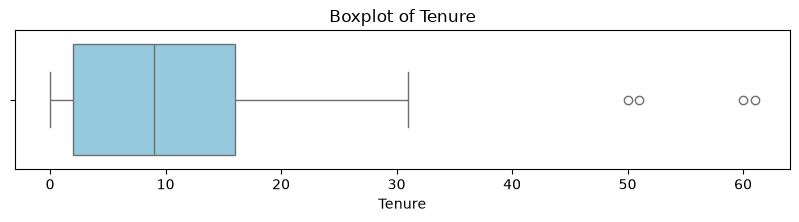

--------------------------------------------------------------------------------
Column Name  : WarehouseToHome
Outlier Count: 1 (0.03%)
Min / Max    : 5.0 / 127.0
Outlier (Unique, max 10): [np.float64(127.0)]


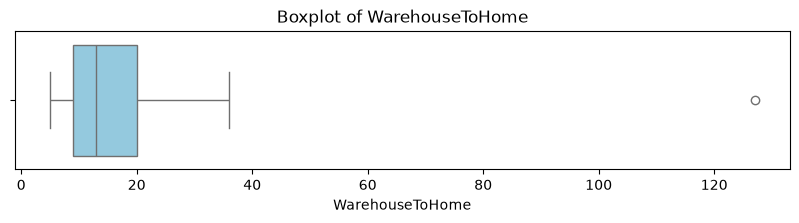

--------------------------------------------------------------------------------
Column Name  : NumberOfDeviceRegistered
Outlier Count: 226 (6.91%)
Min / Max    : 1 / 6
Outlier (Unique, max 10): [np.int64(1), np.int64(6)]


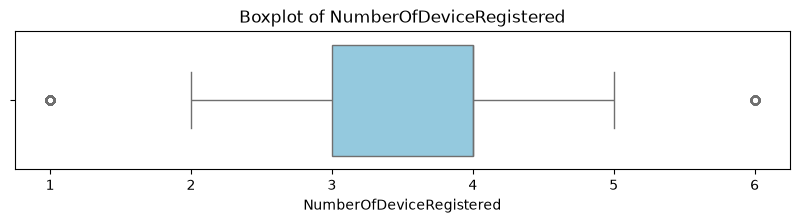

--------------------------------------------------------------------------------
Column Name  : SatisfactionScore
Outlier Count: 0 (0.0%)
Min / Max    : 1 / 5
Outlier (Unique, max 10): []


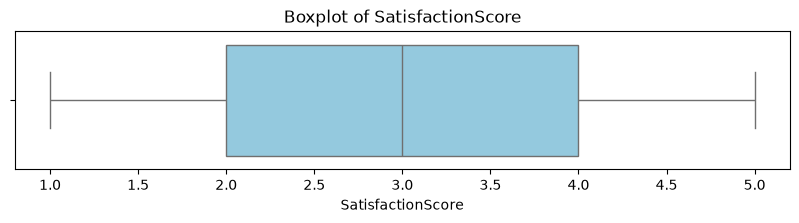

--------------------------------------------------------------------------------
Column Name  : NumberOfAddress
Outlier Count: 3 (0.09%)
Min / Max    : 1 / 22
Outlier (Unique, max 10): [np.int64(19), np.int64(21), np.int64(22)]


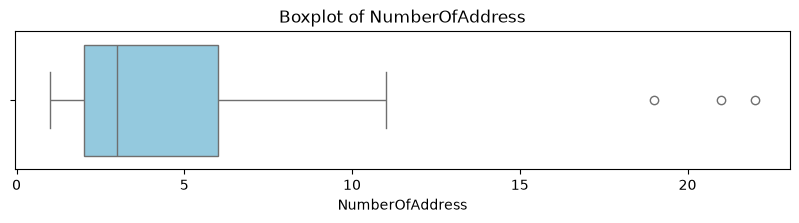

--------------------------------------------------------------------------------
Column Name  : Complain
Outlier Count: 0 (0.0%)
Min / Max    : 0 / 1
Outlier (Unique, max 10): []


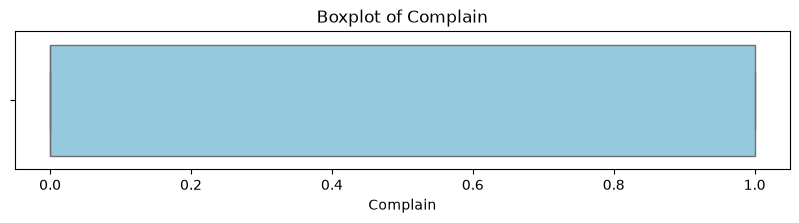

--------------------------------------------------------------------------------
Column Name  : DaySinceLastOrder
Outlier Count: 40 (1.22%)
Min / Max    : 0.0 / 46.0
Outlier (Unique, max 10): [np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(30.0), np.float64(31.0), np.float64(46.0)]


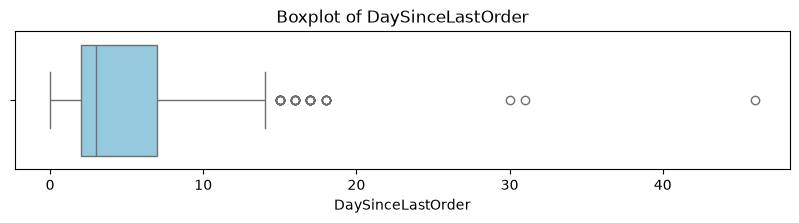

--------------------------------------------------------------------------------
Column Name  : CashbackAmount
Outlier Count: 253 (7.74%)
Min / Max    : 0.0 / 324.99
Outlier (Unique, max 10): [np.float64(0.0), np.float64(12.0), np.float64(25.0), np.float64(37.0), np.float64(56.0), np.float64(274.26), np.float64(274.44), np.float64(274.65), np.float64(275.67), np.float64(275.84)]


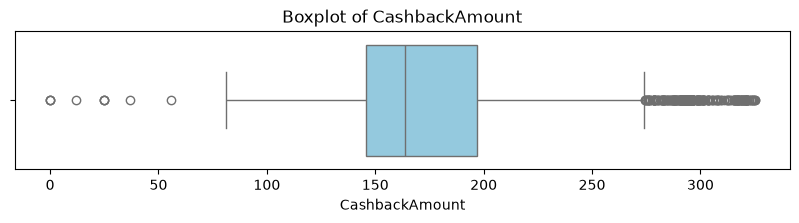

--------------------------------------------------------------------------------


In [93]:
# Kolom numerik kecuali target
numeric_cols = df.drop(columns='Churn').select_dtypes(include='number').columns

for i in numeric_cols:
    Q1, Q3 = df[i].quantile(0.25), df[i].quantile(0.75)
    IQR = Q3 - Q1
    lower_whisker, upper_whisker = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

    outlier_data = df[(df[i] < lower_whisker) | (df[i] > upper_whisker)][i]
    total_outliers = outlier_data.count()

    print(f"Column Name  : {i}")
    print(f"Outlier Count: {total_outliers} ({round((total_outliers / len(df)) * 100, 2)}%)")
    print(f"Min / Max    : {df[i].min()} / {df[i].max()}")
    print(f"Outlier (Unique, max 10): {sorted(outlier_data.unique())[:10]}")

    plt.figure(figsize=(10, 1.8))
    sns.boxplot(x=df[i], color='skyblue')
    plt.title(f"Boxplot of {i}")
    plt.grid(False)
    plt.show()
    print('-' * 80)

Secara umum *outlier* yang terdeteksi **masih masuk akal secara bisnis** (misalnya pelanggan dengan *tenure* 60 bulan, atau jeda pesanan 30–46 hari, atau *cashback* tinggi), dan jumlahnya kecil. Beberapa catatan:

* `WarehouseToHome` (maks 127 vs median 13) dan `NumberOfAddress` (maks 22 vs median 3) memiliki nilai yang sangat ekstrem tetapi hanya 1–3 baris.
* `NumberOfDeviceRegistered` dan `CashbackAmount` ditandai sebagai *outlier* oleh aturan IQR, namun nilainya wajar (rentang 1–6 perangkat; *cashback* sampai ±325).

**Keputusan:** *outlier* **dipertahankan** (tidak dihapus) karena bukan kesalahan input yang jelas. Dampaknya dikendalikan lewat pemilihan *scaler* yang tahan *outlier* (`RobustScaler`) pada bagian 5.1 (*Feature Engineering & Preprocessing*), dan model berbasis *tree* secara alami tidak sensitif terhadap *outlier*.

<a id="bab-3-4-5"></a>
### 3.4.5 Dokumentasi Aturan Cleaning

| # | Isu | Aturan / tindakan | Alasan | Dilakukan di |
| :-: | :--- | :--- | :--- | :--- |
| 1 | *Missing value* (`Tenure`, `WarehouseToHome`, `DaySinceLastOrder`) | Baris **tidak dihapus**; imputasi median + kolom penanda *missing* | Pola kosong tidak acak (berkaitan dengan `Churn`); statistik imputasi hanya boleh dipelajari dari data *train* | *Pipeline* (bagian 5.1) |
| 2 | Baris duplikat identik | `drop_duplicates(keep='first')` **sebelum** *split* | Mencegah baris kembar jatuh ke *train* dan *test* sekaligus; dampak keputusan diuji (bagian 6.4) | Bagian 3.4 |
| 3 | Label `Mobile` vs `Mobile Phone` | Digabung menjadi `Mobile Phone` | Satu kategori yang sama tidak boleh terpecah | Bagian 3.4 dan `predict_churn()` |
| 4 | Tipe data | Tidak ada perubahan | Numerik bertipe numerik, teks bertipe *string* | — |
| 5 | *Outlier* | **Dipertahankan**; `RobustScaler` untuk fitur *skewed* | Nilai masih masuk akal secara bisnis, bukan kesalahan input | *Pipeline* (bagian 5.1) |
| 6 | Kolom ID / tanggal | Tidak ada | — | Dicatat di bagian 3.5 dan 9.1 |

Aturan yang sama (penggabungan label) diterapkan pada data baru di `predict_churn()` (bagian 8.1) agar pemrosesan saat prediksi identik dengan saat pelatihan.

<a id="bab-3-4-6"></a>
### 3.4.6 Menyimpan Data Bersih

In [94]:
df.to_csv(CLEAN_DATA_PATH, index=False)
print(f"Data bersih tersimpan: {df.shape[0]:,} baris x {df.shape[1]} kolom")

Data bersih tersimpan: 3,270 baris x 11 kolom


<a id="bab-3-5"></a>
## 3.5 Final Data Quality Report

Ringkasan kondisi data mentah dan tindakan pembersihan yang dilakukan, agar mudah diaudit dan dibagikan ke tim data. Laporan juga disimpan sebagai `data_quality_report.csv`.

In [95]:
raw = df_with_dups.copy()          # data mentah (sebelum duplikat dihapus & label disamakan)

# --- Ringkasan tingkat dataset ---
n_mobile_label = int((raw['PreferedOrderCat'] == 'Mobile').sum())
dq_dataset = pd.Series({
    'Baris data mentah'                       : f"{len(raw):,}",
    'Kolom'                                   : raw.shape[1],
    'Baris duplikat (identik) dihapus'        : f"{len(raw) - len(df):,} ({(len(raw) - len(df)) / len(raw):.1%})",
    'Baris data bersih'                       : f"{len(df):,}",
    'Baris dipertahankan (% dari data mentah)' : f"{len(df) / len(raw):.1%}",
    'Baris duplikat tersisa (data bersih)'    : f"{int(df.duplicated().sum()):,}",
    'Sel kosong (data bersih; ditangani di pipeline)': f"{int(df.isna().sum().sum()):,} ({df.isna().sum().sum() / df.size:.2%} dari seluruh sel)",
    'Sel kosong (data mentah)'                : f"{int(raw.isna().sum().sum()):,} ({raw.isna().sum().sum() / raw.size:.2%} dari seluruh sel)",
    "Label 'Mobile' digabung ke 'Mobile Phone'": f"{n_mobile_label:,} baris",
    'Churn rate (data bersih)'                : f"{df['Churn'].mean():.2%}",
    'Kolom ID pelanggan / tanggal'            : 'Tidak ada (lihat bagian Limitasi)',
}, name='Nilai')
display(dq_dataset.to_frame())

# --- Ringkasan tingkat kolom ---
treatment = {
    'Tenure': 'Imputasi median + penanda missing (dalam pipeline) -> RobustScaler',
    'WarehouseToHome': 'Imputasi median + penanda missing -> RobustScaler; outlier dipertahankan',
    'DaySinceLastOrder': 'Imputasi median + penanda missing -> RobustScaler',
    'CashbackAmount': 'RobustScaler; outlier dipertahankan',
    'NumberOfAddress': 'RobustScaler; outlier dipertahankan',
    'NumberOfDeviceRegistered': 'StandardScaler', 'SatisfactionScore': 'StandardScaler',
    'Complain': 'Passthrough (biner)', 'PreferedOrderCat': "Gabung label 'Mobile'; modus + One-Hot",
    'MaritalStatus': 'Modus + One-Hot', 'Churn': 'Target',
}
rows = []
for c in raw.columns:
    s = raw[c]
    row = {'Kolom': c, 'Tipe': str(s.dtype), 'Missing': int(s.isna().sum()),
           'Missing (%)': round(s.isna().mean() * 100, 2),
           'Missing (bersih)': int(df[c].isna().sum()), 'Nilai unik': int(s.nunique()),
           'Min': np.nan, 'Max': np.nan, 'Outlier IQR': np.nan, 'Penanganan': treatment.get(c, '-')}
    if pd.api.types.is_numeric_dtype(s):
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        row.update({'Min': s.min(), 'Max': s.max(),
                    'Outlier IQR': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())})
    rows.append(row)
dq_report = pd.DataFrame(rows).set_index('Kolom')
display(dq_report)
dq_report.to_csv(DQ_REPORT_PATH)
print(f"Laporan kualitas data tersimpan: {DQ_REPORT_PATH}")

,Nilai
Baris data mentah,"3,941"
Kolom,11
Baris duplikat (identik) dihapus,671 (17.0%)
Baris data bersih,"3,270"
Baris dipertahankan (% dari data mentah),83.0%
Baris duplikat tersisa (data bersih),1
Sel kosong (data bersih; ditangani di pipeline),476 (1.32% dari seluruh sel)
Sel kosong (data mentah),576 (1.33% dari seluruh sel)
Label 'Mobile' digabung ke 'Mobile Phone',559 baris
Churn rate (data bersih),16.33%


,Tipe,Missing,Missing (%),Missing (bersih),Nilai unik,Min,Max,Outlier IQR,Penanganan
Kolom,,,,,,,,,
Tenure,float64,194,4.92,160,36,0.0,61.00,4.0,Imputasi median + penanda missing (dalam pipel...
WarehouseToHome,float64,169,4.29,135,33,5.0,127.00,1.0,Imputasi median + penanda missing -> RobustSca...
NumberOfDeviceRegistered,int64,0,0.00,0,6,1.0,6.00,271.0,StandardScaler
PreferedOrderCat,str,0,0.00,0,6,NaN,NaN,NaN,Gabung label 'Mobile'; modus + One-Hot
SatisfactionScore,int64,0,0.00,0,5,1.0,5.00,0.0,StandardScaler
MaritalStatus,str,0,0.00,0,3,NaN,NaN,NaN,Modus + One-Hot
NumberOfAddress,int64,0,0.00,0,14,1.0,22.00,3.0,RobustScaler; outlier dipertahankan
Complain,int64,0,0.00,0,2,0.0,1.00,0.0,Passthrough (biner)
DaySinceLastOrder,float64,213,5.40,181,22,0.0,46.00,43.0,Imputasi median + penanda missing -> RobustScaler


Laporan kualitas data tersimpan: data_quality_report.csv


<a id="bab-3-5-1"></a>
### 3.5.1 Isu Data yang Belum Terselesaikan

* **Definisi `Churn` dan waktu pencatatan fitur belum dikonfirmasi** (semua fitur `verified=False`; tiga berisiko tinggi: `Complain`, `DaySinceLastOrder`, `CashbackAmount`).
* **Tidak ada ID pelanggan dan tanggal:** keputusan menghapus duplikat tidak dapat dibuktikan; validasi berbasis waktu tidak dapat dilakukan.
* ***Missing value* masih ada pada data bersih** — memang sengaja tidak diisi pada tahap ini; diimputasi di dalam *pipeline* hanya dari statistik data *train*.
* **`SatisfactionScore` kontra-intuitif** (churn naik seiring skor): perlu klarifikasi cara dan waktu survei.
* *Outlier* ekstrem pada `WarehouseToHome` dan `NumberOfAddress` dipertahankan; dampaknya dikendalikan oleh `RobustScaler`.

<a id="bab-3-6"></a>
## 3.6 Define Features, Target & Data Splitting

<a id="bab-3-6-1"></a>
### 3.6.1 Menentukan Target dan Fitur Prediktor

* **Target:** `Churn`.
* **Fitur prediktor:** seluruh kolom selain target (10 fitur).
* **Identifier:** tidak ada kolom ID pelanggan.
* **Fitur yang tidak tersedia saat prediksi:** belum dapat dipastikan karena waktu pencatatan fitur belum terkonfirmasi; daftar `NOT_AVAILABLE_AT_PREDICTION` di bawah diisi bila tim data menyatakan ada fitur yang baru tersedia setelah waktu prediksi (fitur tersebut wajib dikeluarkan).

In [96]:
TARGET = 'Churn'
ID_COLUMNS = []                       # dataset tidak memiliki kolom ID pelanggan
NOT_AVAILABLE_AT_PREDICTION = []      # isi bila tim data memastikan fitur baru tersedia SETELAH waktu prediksi
DROP_COLUMNS = ID_COLUMNS + NOT_AVAILABLE_AT_PREDICTION

X = df.drop(columns=[TARGET] + DROP_COLUMNS)
y = df[TARGET]

# Gerbang registri pada fitur final: semua kolom harus terdaftar dan fitur berisiko tinggi ditandai
unverified_features = check_feature_availability(list(X.columns))
print(f"Fitur prediktor ({X.shape[1]}): {list(X.columns)}")

Fitur terdaftar: 10 | belum terverifikasi: 10 | di antaranya risiko TINGGI: ['Complain', 'DaySinceLastOrder', 'CashbackAmount']
Fitur prediktor (10): ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount']


<a id="bab-3-6-2"></a>
### 3.6.2 Strategi Split

| Kondisi | Strategi | Status pada dataset ini |
| :--- | :--- | :--- |
| Tanggal tersedia | *Train / validation / test* berdasarkan waktu (periode lama → baru) | Tidak berlaku |
| **Tanggal tidak tersedia** | ***Stratified split*** 80 : 20 + *Stratified 5-Fold CV* pada *train* sebagai validasi | **Dipakai** |

**Keterbatasan yang didokumentasikan:** *split* acak tidak mensimulasikan kondisi prediksi sebenarnya (melatih pada masa lalu, memprediksi masa depan), sehingga performa bisa lebih optimistis dan **tidak boleh diklaim sebagai validasi temporal**. Pada notebook ini *Stratified K-Fold CV* pada data *train* berperan sebagai data validasi; ***test set* disimpan dan baru dibuka pada bagian 6.1**.

<a id="bab-3-6-2-1"></a>
#### 3.6.2.1 Jika Tanggal Tersedia: Split Berbasis Waktu

Dataset ini **tidak memiliki kolom tanggal**, sehingga validasi memakai *Stratified K-Fold*. Jika data bertanggal tersedia, validasi sebaiknya berbasis waktu (latih pada periode lama, uji pada periode yang lebih baru) agar mensimulasikan kondisi prediksi sebenarnya. Fungsi di bawah disiapkan untuk keperluan itu.

In [97]:
DATE_COLUMN = None      # isi dengan nama kolom tanggal jika data bertanggal sudah tersedia

def time_based_split(df_full, date_col, test_frac=0.2):
    """Split berbasis waktu: periode paling baru menjadi test. Untuk CV, gunakan TimeSeriesSplit pada data yang sudah diurutkan."""
    ordered = df_full.sort_values(date_col)
    cut = int(len(ordered) * (1 - test_frac))
    return ordered.iloc[:cut], ordered.iloc[cut:]

if DATE_COLUMN is None:
    print("Data tidak bertanggal -> validasi memakai Stratified 5-Fold (cv). Gunakan time_based_split() jika kolom tanggal tersedia.")
else:
    print(f"Kolom tanggal '{DATE_COLUMN}' diset: gunakan time_based_split() dan TimeSeriesSplit untuk validasi.")

Data tidak bertanggal -> validasi memakai Stratified 5-Fold (cv). Gunakan time_based_split() jika kolom tanggal tersedia.


Data dibagi **80% train : 20% test** dengan `stratify=y` supaya proporsi churn di *train* dan *test* sama. *Missing value* belum diisi di tahap ini — imputasi dilakukan di dalam *pipeline* sehingga hanya mempelajari statistik dari data *train*.

In [98]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Churn rate  train: {y_train.mean()*100:.2f}% | test: {y_test.mean()*100:.2f}%")

Train: (2616, 10) | Test: (654, 10)
Churn rate  train: 16.32% | test: 16.36%


<a id="bab-4"></a>
# 4. EXPLORATORY DATA ANALYSIS (EDA)

EDA dilakukan **hanya pada data *train*** (`X_train` + `y_train`, disimpan sebagai `eda_df`), **bukan** pada seluruh data. Alasannya: temuan EDA mempengaruhi keputusan fitur dan *preprocessing*; jika EDA melihat data *test*, informasi dari *test set* ikut membentuk keputusan modeling dan estimasi performa menjadi sedikit terlalu optimistis. Data *test* baru dibuka pada tahap evaluasi akhir.

Garis merah putus-putus pada beberapa grafik menunjukkan *churn rate* keseluruhan (data *train*) sebagai pembanding.

> **Catatan:** angka persentase pada ringkasan markdown di bawah berasal dari eksekusi sebelumnya pada seluruh data. Setelah notebook dijalankan ulang pada data *train*, angka bisa bergeser sedikit; cocokkan kembali dengan output sel.

In [99]:
# Dataset EDA = HANYA data train (test tidak disentuh)
eda_df = X_train.assign(Churn=y_train)
print(f"Data EDA (train): {eda_df.shape[0]:,} baris x {eda_df.shape[1]} kolom | churn rate: {eda_df['Churn'].mean():.2%}")

Data EDA (train): 2,616 baris x 11 kolom | churn rate: 16.32%


<a id="bab-4-1"></a>
## 4.1 Univariate Analysis

<a id="bab-4-1-1"></a>
### 4.1.1 Target

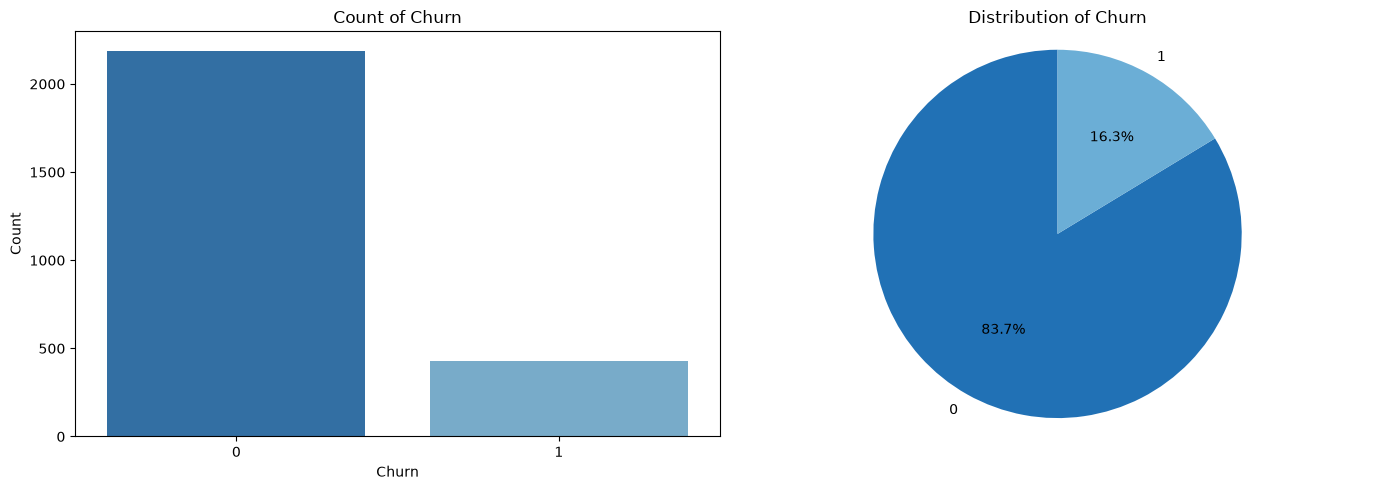

,Churn,count,percentage (%)
0,0,2189,83.68
1,1,427,16.32


Data train: 2,616 baris | churn: 427 (16.32%)


In [100]:
col = 'Churn'

df_agg = eda_df[col].value_counts().reset_index()
df_agg.columns = [col, 'count']
df_agg['percentage (%)'] = round((df_agg['count'] / df_agg['count'].sum()) * 100, 2)
df_agg[col] = df_agg[col].astype(str)

bar_colors = get_palette(len(df_agg), 'Blues')

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.barplot(data=df_agg, x=col, y='count', hue=col, palette=bar_colors, legend=False)
plt.title(f'Count of {col}')
plt.xlabel(col); plt.ylabel('Count'); plt.grid(False)

plt.subplot(1, 2, 2)
wedges, texts, autotexts = plt.pie(df_agg['count'], labels=df_agg[col], autopct='%1.1f%%',
                                   startangle=90, colors=bar_colors)
plt.title(f'Distribution of {col}')
plt.axis('equal')

plt.tight_layout()
plt.show()

display(df_agg)
print(f"Data train: {len(eda_df):,} baris | churn: {int(eda_df['Churn'].sum()):,} ({eda_df['Churn'].mean():.2%})")

Target **tidak seimbang**: pelanggan churn adalah kelas minoritas (±16% pada data *train*; jumlah pasti ada pada tabel di atas — pada seluruh data bersih terdapat 3.270 baris dengan 534 pelanggan churn). Konsekuensinya: (1) *accuracy* menyesatkan, (2) perlu teknik *resampling* (SMOTE) dan/atau metrik *Recall*, *F1*, *PR-AUC*, (3) pembagian data wajib menggunakan `stratify`.

<a id="bab-4-1-2"></a>
### 4.1.2 Numerical Features

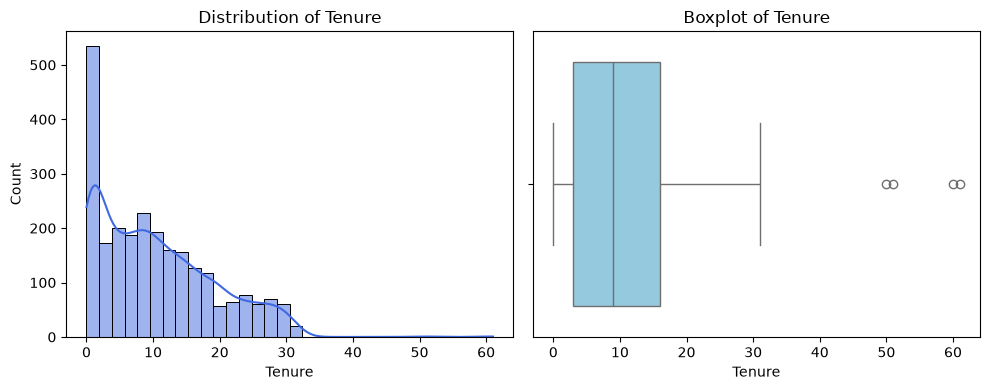

Column: Tenure
   Mean: 10.36 | Median: 9.00 | Std: 8.72 | Min: 0.0 | Max: 61.0
   Skewness: 0.81 | Jumlah outlier (IQR): 4


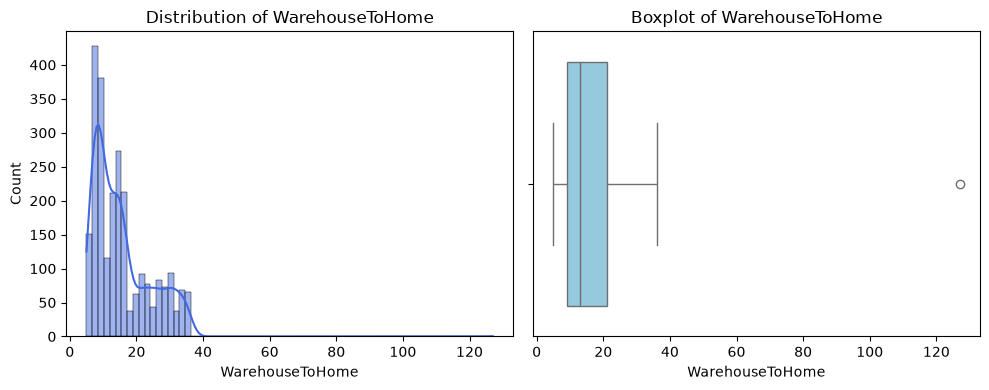

Column: WarehouseToHome
   Mean: 15.51 | Median: 13.00 | Std: 8.66 | Min: 5.0 | Max: 127.0
   Skewness: 1.65 | Jumlah outlier (IQR): 1


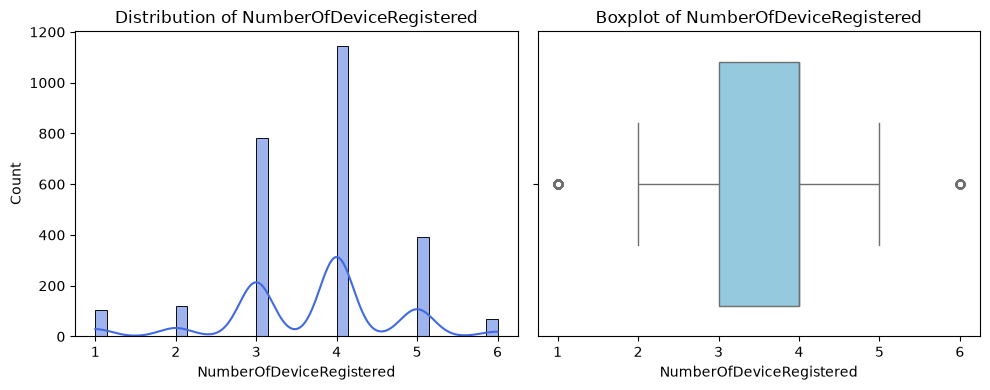

Column: NumberOfDeviceRegistered
   Mean: 3.69 | Median: 4.00 | Std: 1.00 | Min: 1 | Max: 6
   Skewness: -0.43 | Jumlah outlier (IQR): 175


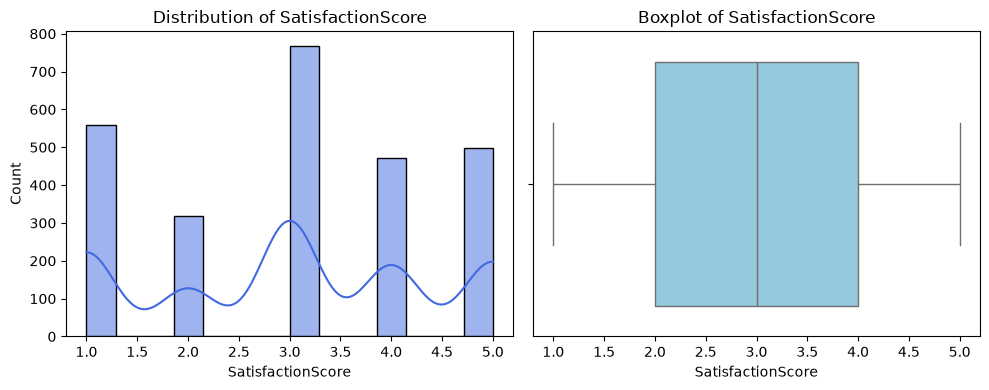

Column: SatisfactionScore
   Mean: 3.01 | Median: 3.00 | Std: 1.39 | Min: 1 | Max: 5
   Skewness: -0.07 | Jumlah outlier (IQR): 0


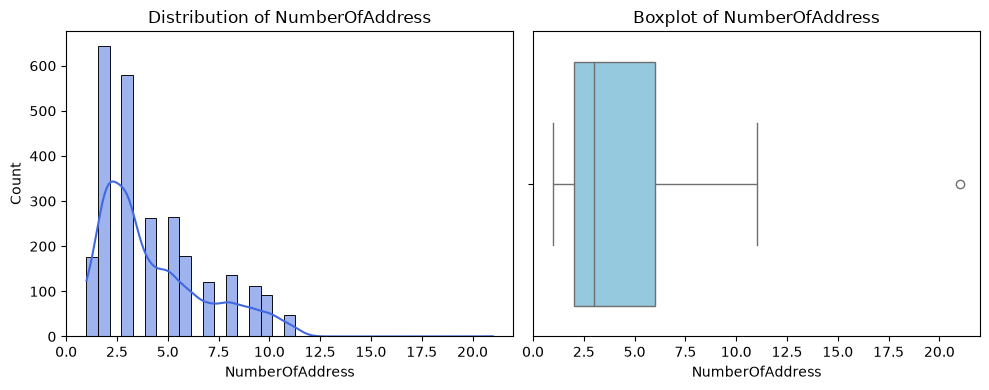

Column: NumberOfAddress
   Mean: 4.23 | Median: 3.00 | Std: 2.60 | Min: 1 | Max: 21
   Skewness: 1.01 | Jumlah outlier (IQR): 1


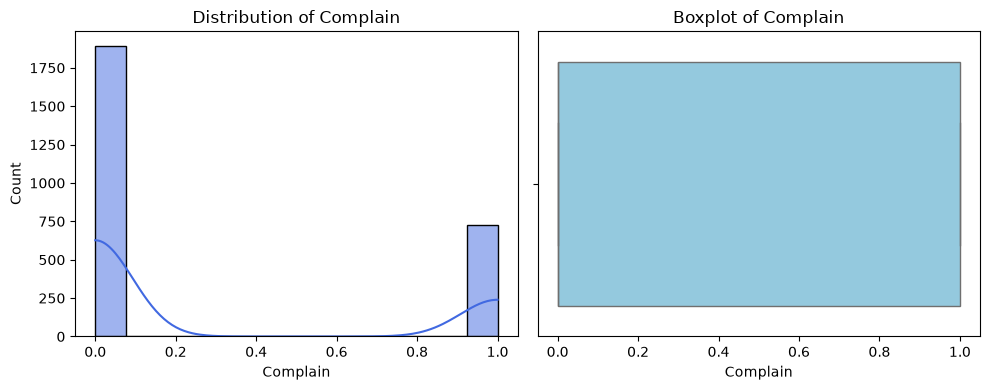

Column: Complain
   Mean: 0.28 | Median: 0.00 | Std: 0.45 | Min: 0 | Max: 1
   Skewness: 1.00 | Jumlah outlier (IQR): 0


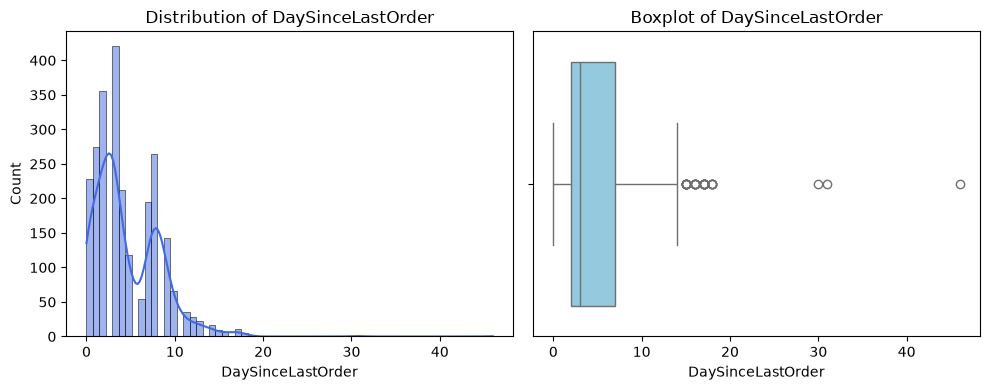

Column: DaySinceLastOrder
   Mean: 4.59 | Median: 3.00 | Std: 3.74 | Min: 0.0 | Max: 46.0
   Skewness: 1.56 | Jumlah outlier (IQR): 35


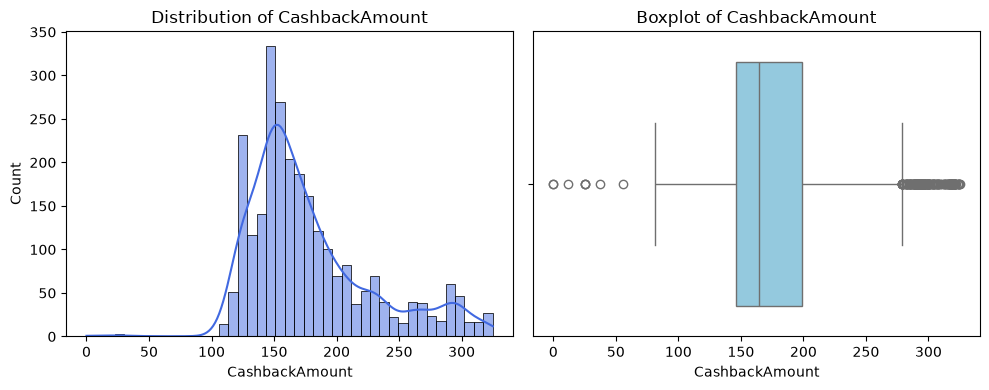

Column: CashbackAmount
   Mean: 178.33 | Median: 164.30 | Std: 49.80 | Min: 0.0 | Max: 324.99
   Skewness: 1.05 | Jumlah outlier (IQR): 201


In [101]:
numeric_cols = eda_df.drop(columns='Churn').select_dtypes(include='number').columns

for col in numeric_cols:
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    sns.histplot(data=eda_df, x=col, kde=True, color='royalblue')
    plt.title(f"Distribution of {col}"); plt.grid(False)

    plt.subplot(1, 2, 2)
    sns.boxplot(data=eda_df, x=col, color='skyblue')
    plt.title(f"Boxplot of {col}"); plt.grid(False)

    plt.tight_layout()
    plt.show()

    Q1, Q3 = eda_df[col].quantile(0.25), eda_df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((eda_df[col] < Q1 - 1.5 * IQR) | (eda_df[col] > Q3 + 1.5 * IQR)).sum()
    print(f"Column: {col}")
    print(f"   Mean: {eda_df[col].mean():.2f} | Median: {eda_df[col].median():.2f} | Std: {eda_df[col].std():.2f} | Min: {eda_df[col].min()} | Max: {eda_df[col].max()}")
    print(f"   Skewness: {eda_df[col].skew():.2f} | Jumlah outlier (IQR): {n_out}")
    print("  " + "=" * 50)

#### Ringkasan Analisis Univariate (Kolom Numerik)

* **`Tenure`, `DaySinceLastOrder`, `WarehouseToHome`** cenderung *right-skewed*: mayoritas pelanggan relatif baru / baru berbelanja / berjarak dekat, dengan ekor panjang ke kanan.
* **`CashbackAmount`** tersebar cukup lebar dan terkonsentrasi di kisaran tengah, dengan sebagian kecil pelanggan menerima *cashback* sangat kecil (termasuk 0).
* **`NumberOfDeviceRegistered`, `NumberOfAddress`, `SatisfactionScore`** adalah variabel diskrit dengan sedikit nilai unik, sehingga lebih tepat dibaca sebagai kategori berurutan. **`Complain`** adalah *flag* biner.
* Karena beberapa fitur *skewed* dan punya *outlier*, *scaler* yang tahan *outlier* (`RobustScaler`) dipilih untuk fitur-fitur tersebut.

<a id="bab-4-1-3"></a>
### 4.1.3 Categorical Features

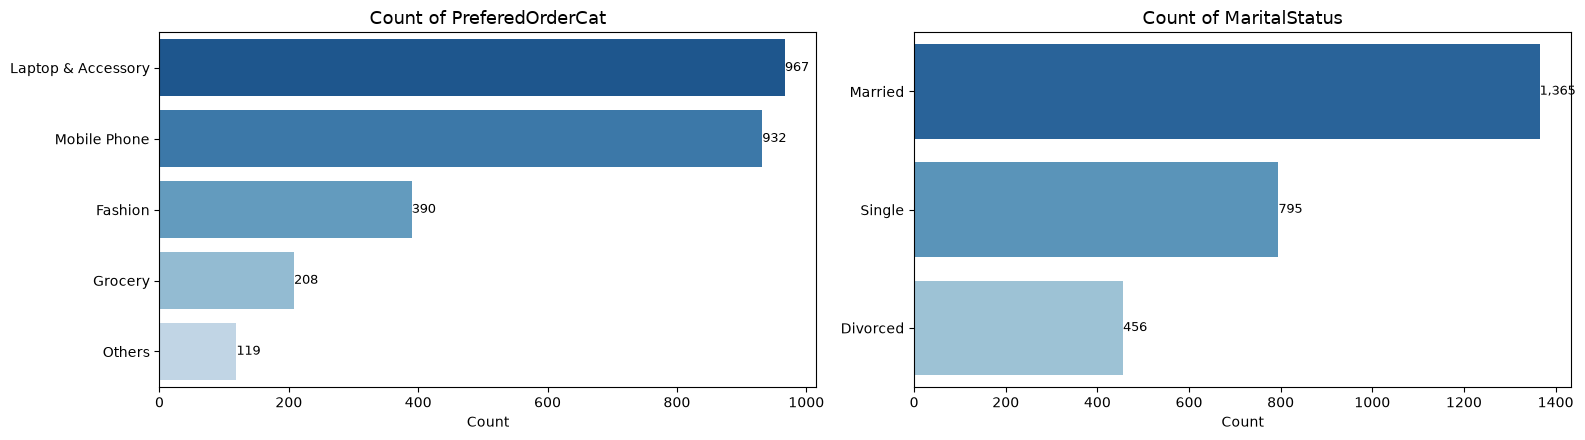

In [102]:
categorical_cols = eda_df.select_dtypes(exclude='number').columns
n_cols = 2
n_rows = int(np.ceil(len(categorical_cols) / n_cols))

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 4.5 * n_rows))
axes = np.atleast_1d(axes).flatten()

for idx, col in enumerate(categorical_cols):
    df_agg = eda_df[col].value_counts().reset_index()
    df_agg.columns = [col, 'count']
    colors = get_palette(len(df_agg), 'Blues')
    sns.barplot(data=df_agg, y=col, x='count', hue=col, palette=colors, orient='h', legend=False, ax=axes[idx])
    for p in axes[idx].patches:
        axes[idx].annotate(f"{int(p.get_width()):,}", (p.get_width(), p.get_y() + p.get_height() / 2),
                           ha='left', va='center', fontsize=9)
    axes[idx].set_title(f'Count of {col}', fontsize=13)
    axes[idx].set_xlabel('Count'); axes[idx].set_ylabel(''); axes[idx].grid(False)

for j in range(len(categorical_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

#### Ringkasan Analisis Univariate (Kolom Kategorikal)

* **`PreferedOrderCat`** didominasi oleh `Laptop & Accessory` dan `Mobile Phone` (setelah penggabungan label), disusul `Fashion`; `Grocery` dan `Others` berukuran kecil.
* **`MaritalStatus`** didominasi pelanggan `Married`, diikuti `Single` dan `Divorced`.
* Jumlah kategori sedikit sehingga *One-Hot Encoding* aman digunakan (tidak ada ledakan jumlah fitur).

<a id="bab-4-2"></a>
## 4.2 Bivariate Analysis

<a id="bab-4-2-1"></a>
### 4.2.1 Numerical Features vs Target

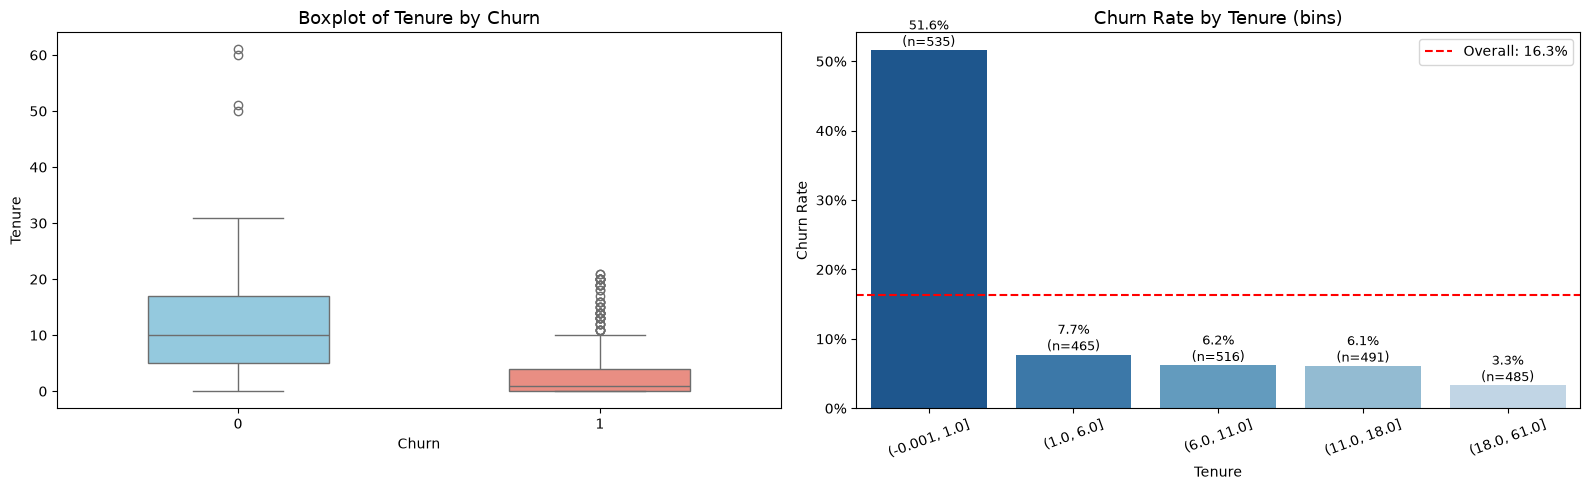

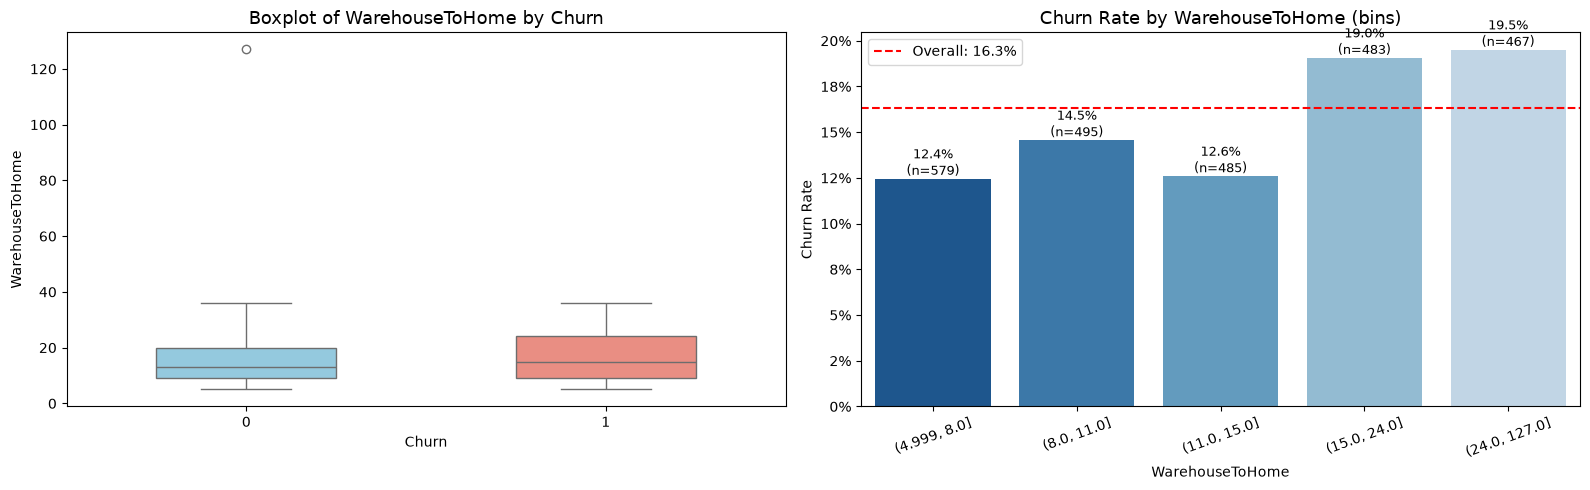

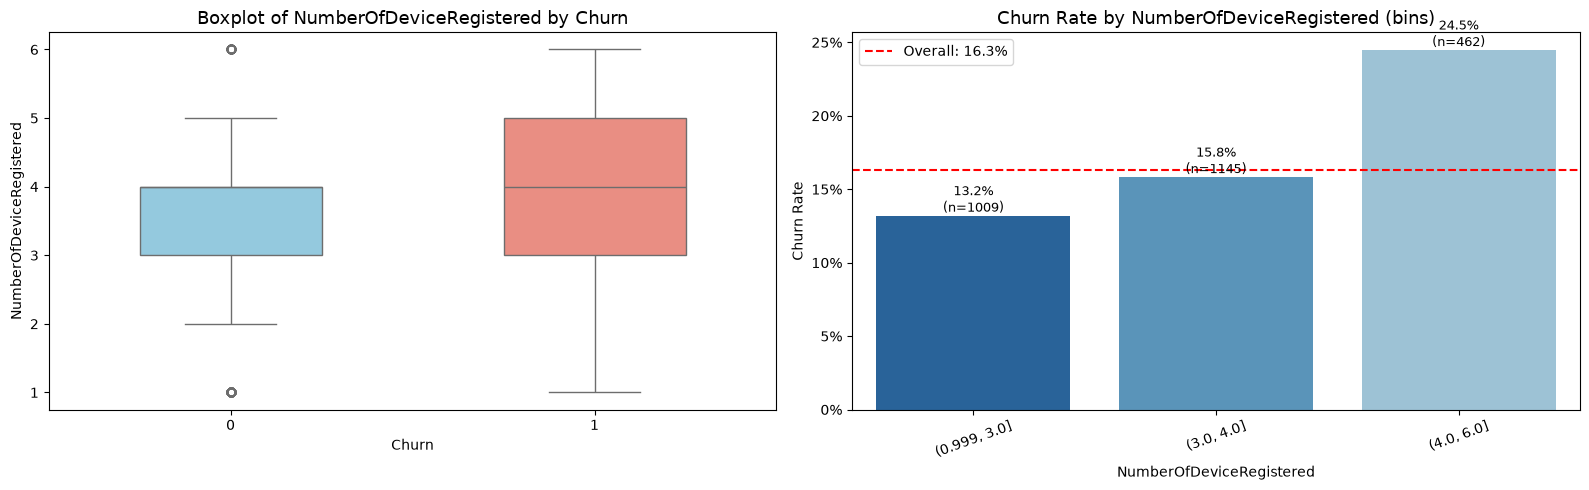

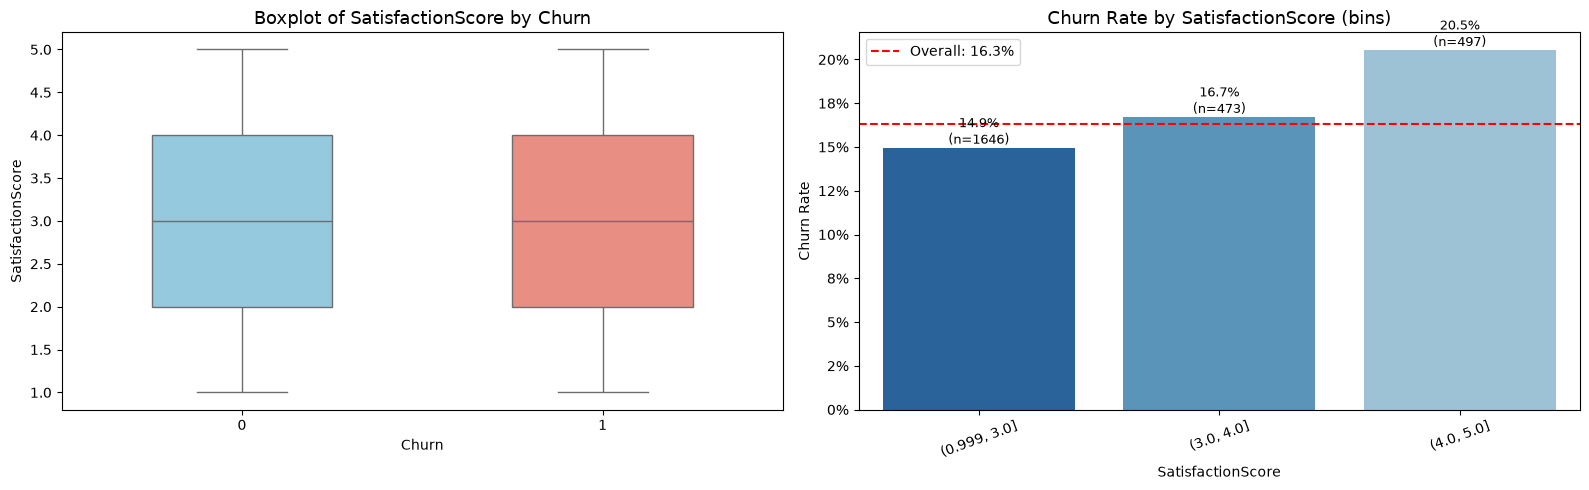

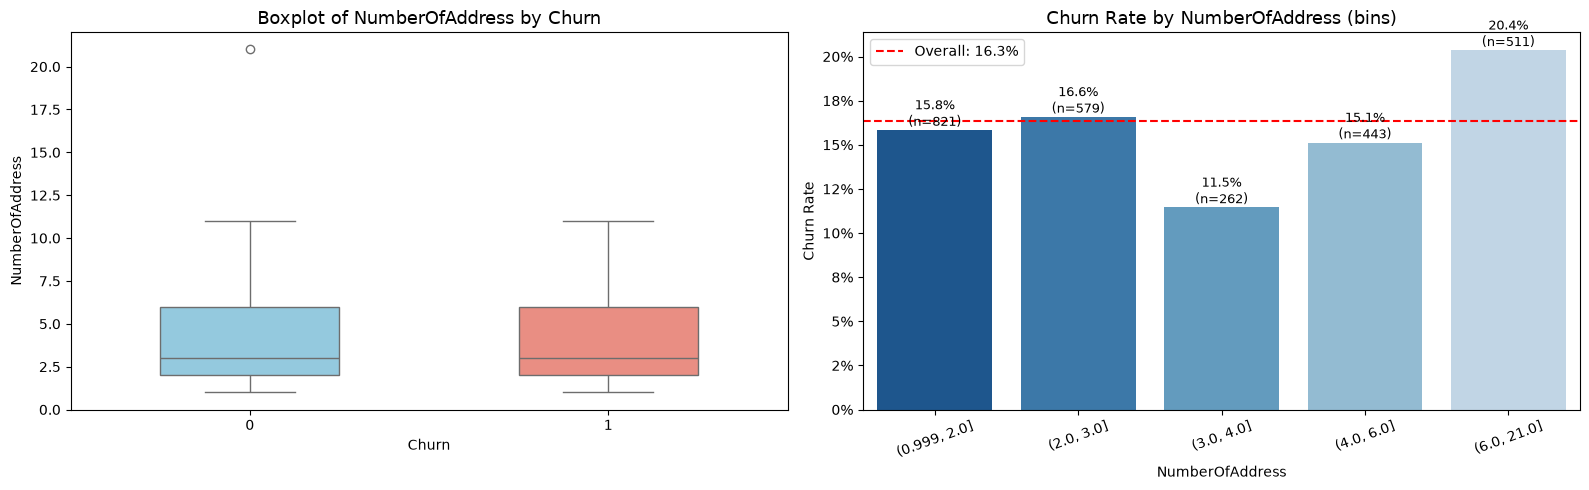

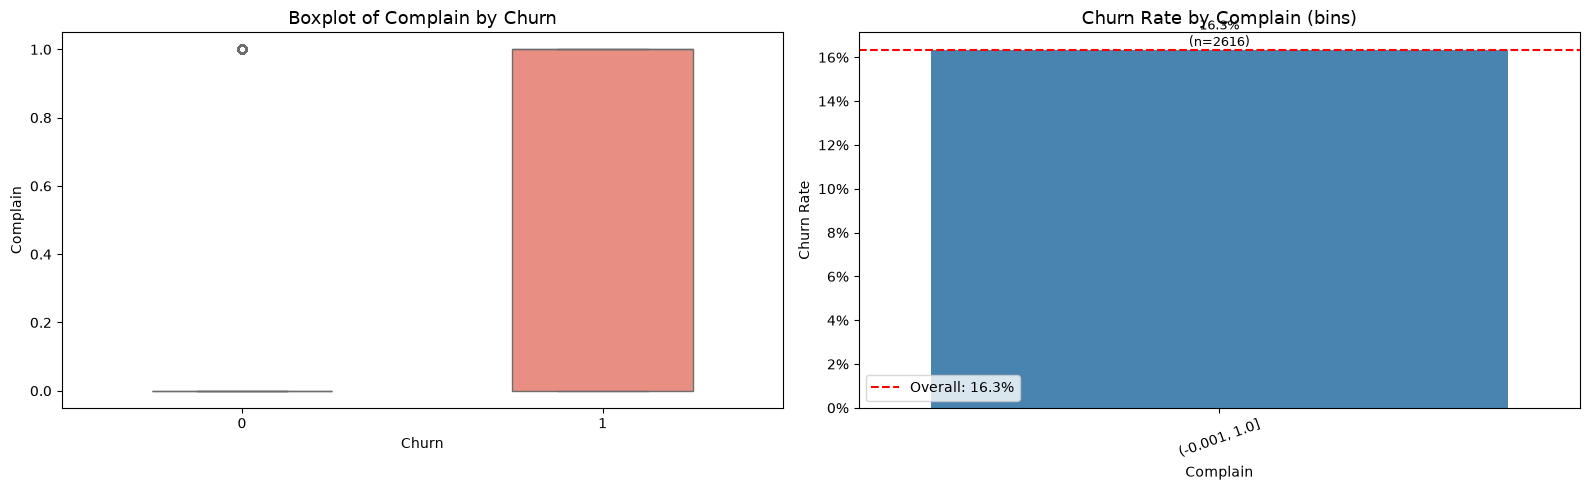

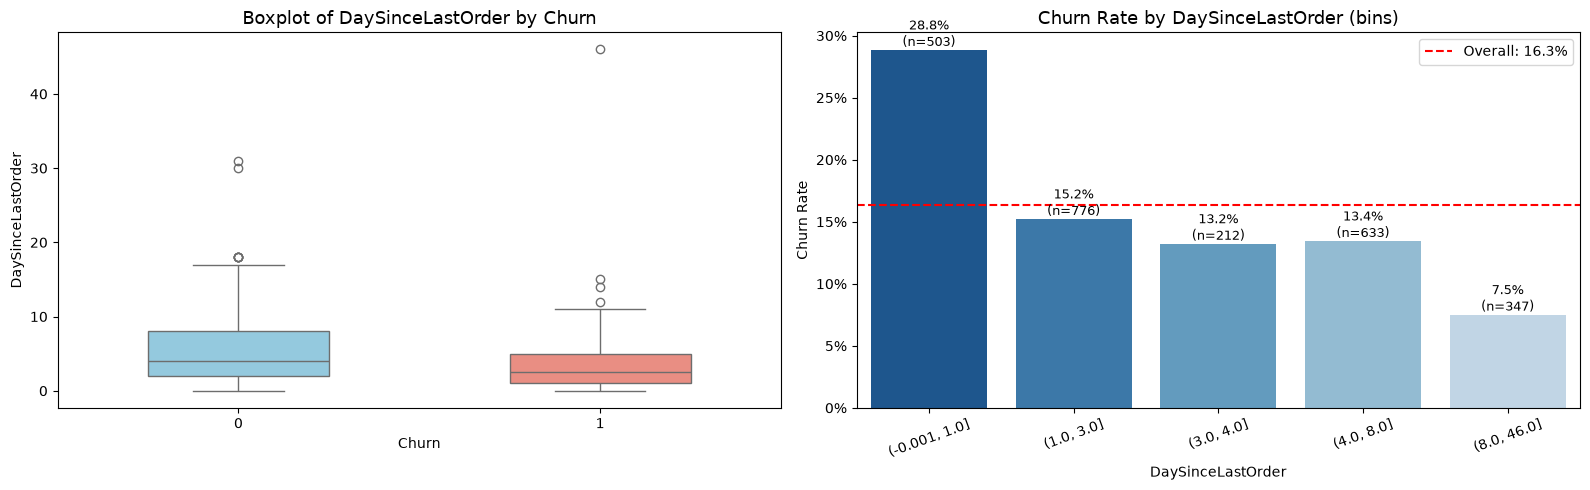

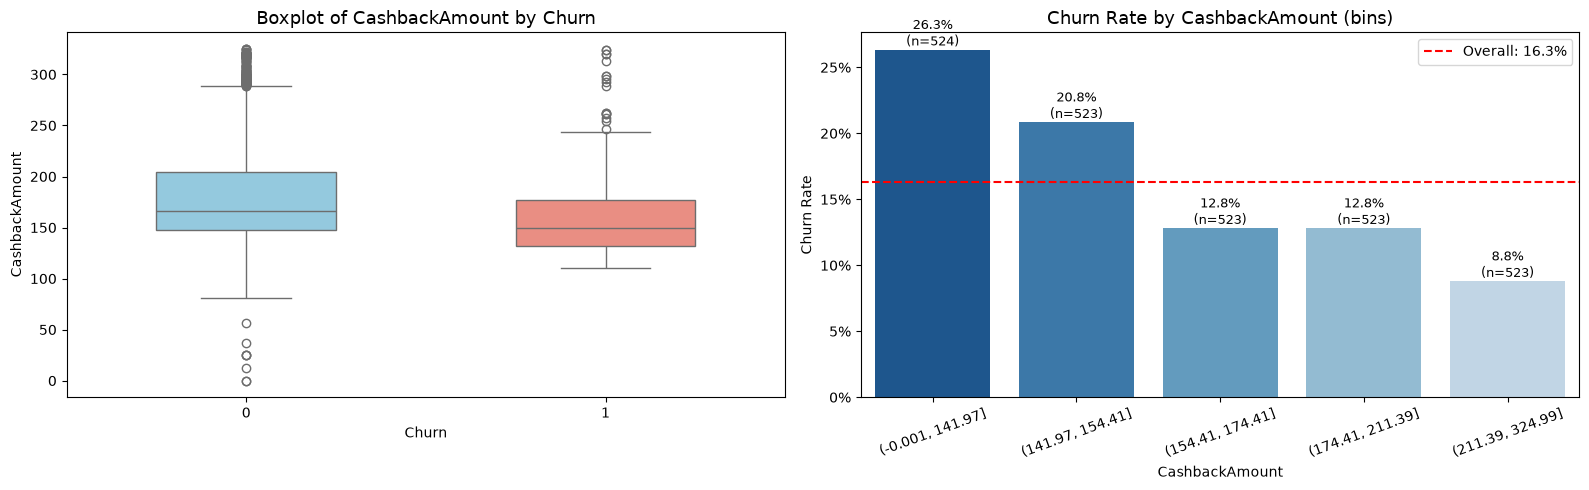

In [103]:
numeric_cols = eda_df.drop(columns='Churn').select_dtypes(include='number').columns
overall_rate = eda_df['Churn'].mean()

for i in numeric_cols:
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

    # Plot 1: Boxplot per kelas target
    sns.boxplot(data=eda_df, x=eda_df['Churn'].astype(str), y=i, hue=eda_df['Churn'].astype(str),
                palette={'0': 'skyblue', '1': 'salmon'}, legend=False, ax=axes[0], width=0.5)
    axes[0].set_title(f"Boxplot of {i} by Churn", fontsize=13)
    axes[0].set_xlabel("Churn"); axes[0].grid(False)

    # Plot 2: Churn rate per bin (maks 5 bin)
    df_temp = eda_df[[i, 'Churn']].copy()
    try:
        df_temp['bin'] = pd.qcut(df_temp[i], q=5, duplicates='drop')
    except ValueError:
        df_temp['bin'] = pd.cut(df_temp[i], bins=5)
    agg = df_temp.groupby('bin', observed=True)['Churn'].agg(['mean', 'count']).reset_index()
    agg['bin'] = agg['bin'].astype(str)

    sns.barplot(data=agg, x='bin', y='mean', hue='bin', palette=get_palette(len(agg), 'Blues'),
                legend=False, ax=axes[1])
    axes[1].axhline(overall_rate, color='red', linestyle='--', label=f'Overall: {overall_rate:.1%}')
    for p, n in zip(axes[1].patches, agg['count']):
        axes[1].annotate(f'{p.get_height():.1%}\n(n={n})', (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha='center', va='bottom', fontsize=9)
    axes[1].set_title(f"Churn Rate by {i} (bins)", fontsize=13)
    axes[1].set_xlabel(i); axes[1].set_ylabel('Churn Rate')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    axes[1].tick_params(axis='x', rotation=20)
    axes[1].legend(); axes[1].grid(False)

    plt.tight_layout()
    plt.show()

,Churn Rate (%),Jumlah Pelanggan
Tenure,,
0,55.7,219
1-3,34.6,489
4-6,7.2,292
7-12,6.0,602
13-24,6.2,674
>24,0.0,216


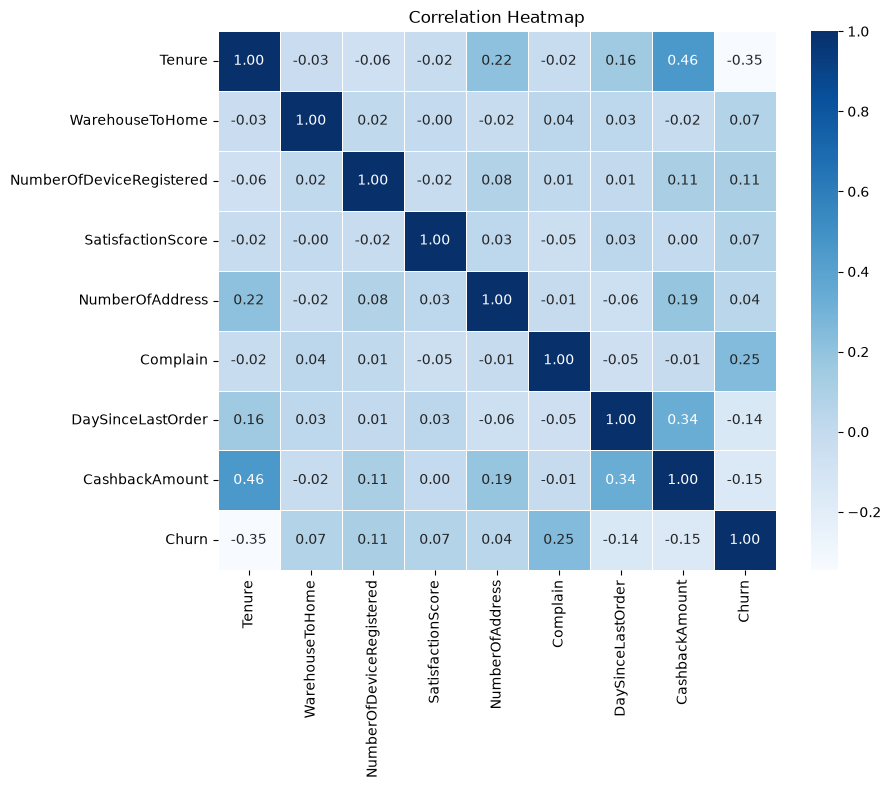

In [104]:
# Churn rate berdasarkan segmen Tenure (bulan) -> temuan paling kuat
tenure_bins = pd.cut(eda_df['Tenure'], bins=[-1, 0, 3, 6, 12, 24, 100],
                     labels=['0', '1-3', '4-6', '7-12', '13-24', '>24'])
tenure_tbl = eda_df.groupby(tenure_bins, observed=True)['Churn'].agg(['mean', 'count'])
tenure_tbl['mean'] = (tenure_tbl['mean'] * 100).round(1)
tenure_tbl.columns = ['Churn Rate (%)', 'Jumlah Pelanggan']
display(tenure_tbl)

# Korelasi fitur numerik dengan target
plt.figure(figsize=(9, 7))
sns.heatmap(eda_df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

<a id="bab-4-2-2"></a>
### 4.2.2 Pola Pelanggan: Tenure × Complain terhadap Churn

In [105]:
# Pola gabungan: segmen tenure x riwayat komplain (hanya data train)
pattern = (eda_df.assign(TenureGroup=tenure_bins)
                 .groupby(['TenureGroup', 'Complain'], observed=True)['Churn']
                 .agg(['mean', 'count']))
pattern['mean'] = (pattern['mean'] * 100).round(1)
display(pattern.rename(columns={'mean': 'Churn Rate (%)', 'count': 'n'}).unstack('Complain'))

Churn Rate (%)          n     
Complain                 0     1    0    1
TenureGroup                               
0                     44.1  74.7  136   83
1-3                   24.0  57.9  337  152
4-6                    2.6  23.8  229   63
7-12                   4.4  10.9  455  147
13-24                  3.6  13.4  495  179
>24                    0.0   0.0  150   66

#### Kesimpulan Analisis Bivariat (Numerik vs Churn)

* **`Tenure` adalah sinyal terkuat** (korelasi terhadap churn ≈ −0,35). Pelanggan yang churn memiliki *tenure* yang jauh lebih pendek (median ±1 bulan vs ±10 bulan pada pelanggan yang bertahan). *Churn rate* sangat tinggi pada pelanggan baru (±54% pada *tenure* 0 dan ±35% pada 1–3 bulan), turun tajam setelah 3 bulan, dan praktis **0% pada pelanggan dengan *tenure* > 24 bulan**.
* **`Complain`** berkorelasi positif (≈ +0,26): pelanggan yang pernah komplain jauh lebih mungkin churn.
* **`CashbackAmount`** dan **`DaySinceLastOrder`** berkorelasi negatif (≈ −0,15): pelanggan yang churn cenderung menerima *cashback* lebih kecil dan jeda pesanan terakhirnya lebih pendek (kemungkinan karena pelanggan baru yang belum sempat membangun kebiasaan).
* **`NumberOfDeviceRegistered`** naik bersama churn (±10% pada 1–2 perangkat menjadi ±34% pada 6 perangkat).
* Boxplot untuk banyak fitur masih *overlapping*, sehingga tidak ada satu fitur yang memisahkan kelas dengan sempurna — kombinasi fitur diperlukan.

<a id="bab-4-2-3"></a>
### 4.2.3 Categorical Features vs Target

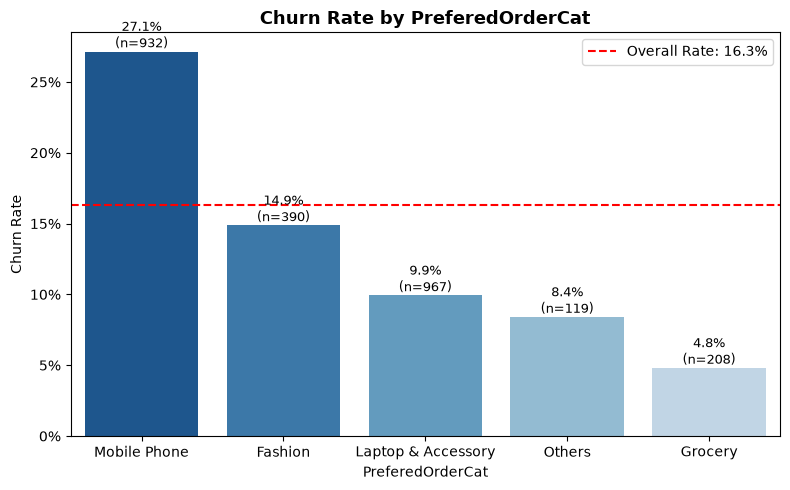

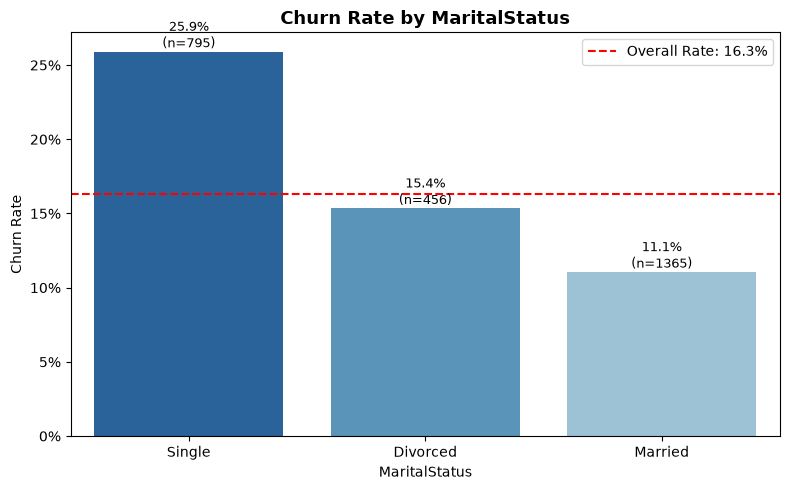


Churn rate by Complain


,Churn Rate (%),n
Complain,,
0,10.6,1893
1,31.4,723



Churn rate by SatisfactionScore


,Churn Rate (%),n
SatisfactionScore,,
1,12.1,560
2,14.2,318
3,17.3,768
4,16.7,473
5,20.5,497


In [106]:
overall_rate = eda_df['Churn'].mean()

for i in eda_df.select_dtypes(exclude='number').columns:
    df_agg = (eda_df.groupby(i)['Churn'].agg(['mean', 'count']).reset_index()
                .sort_values('mean', ascending=False))
    fig, ax = plt.subplots(figsize=(max(8, len(df_agg) * 1.6), 5))
    sns.barplot(data=df_agg, x=i, y='mean', hue=i, palette=get_palette(len(df_agg), 'Blues'),
                legend=False, ax=ax)
    ax.axhline(overall_rate, color='red', linestyle='--', linewidth=1.5, label=f'Overall Rate: {overall_rate:.1%}')
    for p, n in zip(ax.patches, df_agg['count']):
        ax.annotate(f'{p.get_height():.1%}\n(n={n})', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.set_title(f'Churn Rate by {i}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Churn Rate'); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.legend(); ax.grid(False)
    plt.tight_layout(); plt.show()

# Fitur ordinal/biner yang juga layak dilihat sebagai kategori
for i in ['Complain', 'SatisfactionScore']:
    print(f"\nChurn rate by {i}")
    display(eda_df.groupby(i)['Churn'].agg(['mean', 'count']).assign(mean=lambda d: (d['mean'] * 100).round(1))
              .rename(columns={'mean': 'Churn Rate (%)', 'count': 'n'}))

#### Ringkasan Analisis Bivariat (Kategorikal vs Churn)

Garis merah menunjukkan *churn rate* keseluruhan (±16%).

* **`PreferedOrderCat`:** `Mobile Phone` (±27%) dan `Fashion` (±16%) berada di atas/sekitar rata-rata, sedangkan `Grocery` (±4%) dan `Others` (±7%) jauh di bawah rata-rata.
* **`MaritalStatus`:** pelanggan `Single` (±26%) memiliki risiko paling tinggi dibanding `Divorced` (±16%) dan `Married` (±11%).
* **`Complain`:** pelanggan yang pernah komplain churn ±32% vs ±10% pada yang tidak pernah komplain.
* **`SatisfactionScore` — temuan kontra-intuitif:** *churn rate* justru **naik** seiring skor kepuasan (±11% pada skor 1 menjadi ±23% pada skor 5). Ini tidak boleh langsung ditafsirkan sebagai "kepuasan tinggi menyebabkan churn"; kemungkinan penyebabnya antara lain skor survei yang tidak mencerminkan pengalaman sebenarnya atau pengaruh faktor lain (misalnya *tenure*). Sebaiknya dikonfirmasi dengan tim pemilik data.

<a id="bab-4-3"></a>
## 4.3 Insight yang Relevan terhadap Keputusan Bisnis

| Temuan EDA (data *train*) | Implikasi bisnis | Ditindaklanjuti di |
| :--- | :--- | :--- |
| *Tenure* pendek (terutama 0–3 bulan) berasosiasi dengan *churn rate* paling tinggi | Fokus *onboarding* pelanggan baru; `Tenure` menjadi sinyal utama model | Bagian 6.2, 7.1, 9.2 |
| Pelanggan yang pernah komplain *churn* jauh lebih sering | Penanganan komplain cepat dan proaktif | Bagian 9.2 |
| Kategori `Mobile Phone` dan status `Single` berisiko lebih tinggi | Kandidat segmen penawaran khusus (perlu validasi lewat A/B test) | Bagian 7.1, 7.2 |
| `SatisfactionScore` kontra-intuitif (*churn* naik seiring skor) | **Jangan** dijadikan dasar keputusan sebelum cara/waktu survei dikonfirmasi | Bagian 3.3, 6.2 |
| Distribusi fitur saling tumpang-tindih antar kelas | Tidak ada satu fitur yang memisahkan kelas; diperlukan kombinasi fitur (model) | Bagian 5.3–5.6 |
| Kelas *churn* minoritas (±16%) | *Accuracy* menyesatkan; perlu penanganan *imbalance* dan metrik Recall/F1/PR-AUC | Bagian 5.2 |

> Besaran angka pada ringkasan EDA berasal dari eksekusi sebelumnya; cocokkan dengan *output* setelah notebook dijalankan ulang. Temuan EDA adalah **asosiasi**, bukan sebab-akibat.

<a id="bab-5"></a>
# 5. MODEL DEVELOPMENT

<a id="bab-5-1"></a>
## 5.1 Feature Engineering & Preprocessing

<a id="bab-5-1-1"></a>
### 5.1.1 Pembuatan Fitur yang Didukung Data

Dataset hanya berisi **satu baris ringkasan per pelanggan** tanpa log transaksi, log layanan, atau tanggal. Fitur turunan baru (mis. RFM, tren pembelian) tidak dapat dibuat tanpa asumsi tambahan, sehingga **notebook ini tidak membuat fitur baru**. Tabel berikut mendokumentasikan fitur kandidat jika data sumber tersedia:

| Fitur kandidat | Definisi yang disarankan | Data sumber | Status pada dataset ini |
| :--- | :--- | :--- | :--- |
| ***Recency*** (R) | Hari sejak pesanan terakhir terhadap tanggal *cut-off* | Log transaksi | **Sebagian** — `DaySinceLastOrder` mendekati recency (waktu acuan belum jelas) |
| ***Frequency*** (F) | Jumlah pesanan dalam N hari sebelum *cut-off* | Log transaksi | Tidak tersedia |
| ***Monetary*** (M) | Total belanja dalam N hari sebelum *cut-off* | Log transaksi | Tidak tersedia (`CashbackAmount` bukan nilai belanja) |
| Rata-rata nilai transaksi | M ÷ F | Log transaksi | Tidak tersedia |
| Tren pembelian | Rasio jumlah pesanan 30 hari terakhir vs 30 hari sebelumnya | Log transaksi | Tidak tersedia |
| Frekuensi komplain | Jumlah komplain per periode | Log layanan pelanggan | Tidak tersedia (`Complain` hanya biner) |
| Waktu penyelesaian komplain | Selisih waktu komplain dibuka dan ditutup | Log layanan pelanggan | Tidak tersedia |
| Penggunaan *cashback* | Cashback terpakai ÷ cashback diberikan | Data promo | Tidak tersedia (`CashbackAmount` = rata-rata diterima) |

**Aturan untuk fitur baru:** (1) definisi tertulis dan tidak ambigu; (2) dihitung hanya dari data **sebelum waktu prediksi** (tidak boleh memakai data masa depan); (3) didaftarkan ke `FEATURE_REGISTRY`; (4) masuk ke `ColumnTransformer` yang sama sehingga hanya belajar dari data *train*; (5) diuji kontribusinya dengan *ablation* seperti pada bagian *Uji Sensitivitas*.

<a id="bab-5-1-2"></a>
### 5.1.2 Encoding, Scaling, dan Imputation dalam Pipeline

Seluruh transformasi dibungkus dalam `ColumnTransformer` agar **hanya belajar dari data *train*** dan diterapkan identik ke data *test*.

| Kelompok | Fitur | Perlakuan |
| :--- | :--- | :--- |
| Kategorikal nominal | `PreferedOrderCat`, `MaritalStatus` | Imputasi modus → *One-Hot Encoding* |
| Numerik *skewed* / rawan *outlier* | `Tenure`, `WarehouseToHome`, `DaySinceLastOrder`, `CashbackAmount`, `NumberOfAddress` | Imputasi median (+ kolom penanda *missing*) → `RobustScaler` |
| Numerik diskrit / ordinal | `NumberOfDeviceRegistered`, `SatisfactionScore` | Imputasi median → `StandardScaler` |
| *Binary flag* | `Complain` | *Passthrough* (sudah 0/1) |

In [107]:
nominal_cols  = ['PreferedOrderCat', 'MaritalStatus']
skewed_cols   = ['Tenure', 'WarehouseToHome', 'DaySinceLastOrder', 'CashbackAmount', 'NumberOfAddress']
discrete_cols = ['NumberOfDeviceRegistered', 'SatisfactionScore']
binary_cols   = ['Complain']

column_transformer = ColumnTransformer(
    transformers=[
        ('Categorical_Nominal',
         Pipeline([
             ('imputer', SimpleImputer(strategy='most_frequent')),
             ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore')),
         ]), nominal_cols),

        ('Numerical_Skewed',
         Pipeline([
             # add_indicator=True -> menambah kolom 0/1 "apakah nilainya semula kosong"
             ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
             ('scaler', RobustScaler()),
         ]), skewed_cols),

        ('Numerical_Discrete',
         Pipeline([
             ('imputer', SimpleImputer(strategy='median')),
             ('scaler', StandardScaler()),
         ]), discrete_cols),

        ('Binary_Flags', 'passthrough', binary_cols),
    ],
    remainder='drop'
)

# Cek hasil transformasi pada data train (hanya untuk inspeksi, pipeline akan fit ulang sendiri)
_pre_check = column_transformer.fit_transform(X_train)
print("Shape sebelum :", X_train.shape)
print("Shape sesudah :", _pre_check.shape)
print("Nama fitur    :", list(column_transformer.get_feature_names_out()))
print("Missing value tersisa setelah imputasi:", int(np.isnan(_pre_check).sum()))

Shape sebelum : (2616, 10)
Shape sesudah : (2616, 19)
Nama fitur    : ['Categorical_Nominal__PreferedOrderCat_Fashion', 'Categorical_Nominal__PreferedOrderCat_Grocery', 'Categorical_Nominal__PreferedOrderCat_Laptop & Accessory', 'Categorical_Nominal__PreferedOrderCat_Mobile Phone', 'Categorical_Nominal__PreferedOrderCat_Others', 'Categorical_Nominal__MaritalStatus_Divorced', 'Categorical_Nominal__MaritalStatus_Married', 'Categorical_Nominal__MaritalStatus_Single', 'Numerical_Skewed__Tenure', 'Numerical_Skewed__WarehouseToHome', 'Numerical_Skewed__DaySinceLastOrder', 'Numerical_Skewed__CashbackAmount', 'Numerical_Skewed__NumberOfAddress', 'Numerical_Skewed__missingindicator_Tenure', 'Numerical_Skewed__missingindicator_WarehouseToHome', 'Numerical_Skewed__missingindicator_DaySinceLastOrder', 'Numerical_Discrete__NumberOfDeviceRegistered', 'Numerical_Discrete__SatisfactionScore', 'Binary_Flags__Complain']
Missing value tersisa setelah imputasi: 0


<a id="bab-5-1-3"></a>
### 5.1.3 Prinsip Anti-Leakage pada Preprocessing

* `column_transformer` (imputer → encoder/scaler) adalah **bagian dari *pipeline*** bersama SMOTE dan model.
* Pada `cross_validate` dan `GridSearchCV`, seluruh langkah di-*fit* ulang **hanya pada *training fold***; data validasi hanya di-*transform*.
* Pada model final, *pipeline* di-*fit* hanya pada `X_train`; `X_test` hanya di-*transform* pada bagian 6.1.
* Sel pengecekan di atas (`fit_transform(X_train)`) hanya untuk inspeksi bentuk keluaran, bukan untuk melatih model.

<a id="bab-5-2"></a>
## 5.2 Imbalance Handling Experiments

Kelas *churn* hanya ±16%. Penanganan *imbalance* diuji **di dalam *pipeline* validasi** (hanya diterapkan pada data *train* setiap *fold*) dengan skema CV yang **sama** untuk semua strategi (`cv` pada bagian 2):

1. **Baseline** tanpa penanganan,
2. ***Class weight*** (`scale_pos_weight`),
3. ***RandomOverSampler***,
4. ***SMOTE***,
5. ***SMOTENC*** (kolom hasil *One-Hot*, biner, dan penanda *missing* diperlakukan sebagai kategorikal agar sampel sintetis tetap bernilai 0/1).

Model uji adalah **XGBoost dengan parameter bawaan** (konfigurasi yang sama dengan *benchmarking*), sehingga eksperimen ini tidak bergantung pada hasil *tuning* yang baru dilakukan pada bagian 5.5. Konfirmasi ulang pada model teregularisasi dilakukan di bagian 5.6. *Accuracy*, ROC-AUC, dan PR-AUC dilaporkan agar strategi yang menggeser probabilitas (seperti *class weight*) tetap dapat dibandingkan secara adil.

Catatan tentang ***resampling* (SMOTE):** teknik ini relevan karena kelas churn hanya ±16%. SMOTE membuat contoh sintetis untuk kelas minoritas dengan menginterpolasi antar tetangga terdekatnya.

**Penting:** SMOTE ditempatkan **di dalam *pipeline*** (setelah *preprocessing*, sebelum model), sehingga pada setiap *fold* validasi silang SMOTE hanya diterapkan pada data *train*-nya. Data validasi dan data *test* tidak pernah disentuh SMOTE — ini mencegah skor yang terlalu optimistis.

In [108]:
# ---------- Pabrik model XGBoost (dipakai juga pada bagian 5.6) ----------
def _make_xgb(params=None, **extra):
    return XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0,
                         **(params or {}), **extra)

# ---------- Indeks kolom kategorikal (hasil One-Hot, biner, penanda missing) untuk SMOTENC ----------
ct_fit = clone(column_transformer).fit(X_train)       # hanya untuk membaca nama/struktur kolom hasil transformasi
out_names = list(ct_fit.get_feature_names_out())
cat_idx = [i for i, n in enumerate(out_names)
           if n.startswith(('Categorical_Nominal__', 'Binary_Flags__')) or 'missingindicator' in n]
neg_pos_ratio = float((y_train == 0).sum() / (y_train == 1).sum())

def _imb_pipe(model_params=None, sampler=None, **model_extra):
    steps = [('pre', clone(column_transformer))]
    if sampler is not None:
        steps.append(('resample', sampler))
    steps.append(('model', _make_xgb(model_params, **model_extra)))
    return Pipeline(steps)

scoring_imb = {'accuracy': 'accuracy', 'recall': 'recall', 'precision': 'precision', 'f1': 'f1',
               'roc_auc': 'roc_auc', 'pr_auc': 'average_precision'}

def run_imbalance_comparison(model_params=None):
    """Bandingkan strategi imbalance dengan CV yang sama; resampling hanya pada training fold."""
    strategies = {
        'Tanpa penanganan (baseline)'    : _imb_pipe(model_params),
        'Class weight (scale_pos_weight)': _imb_pipe(model_params, scale_pos_weight=neg_pos_ratio),
        'RandomOverSampler'              : _imb_pipe(model_params, RandomOverSampler(random_state=RANDOM_STATE)),
        'SMOTE'                          : _imb_pipe(model_params, SMOTE(random_state=RANDOM_STATE)),
        'SMOTENC'                        : _imb_pipe(model_params, SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE)),
    }
    rows = []
    for name, pipe in strategies.items():
        r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_imb, return_train_score=True, n_jobs=-1)
        rows.append({'Strategi': name,
                     'CV Accuracy': r['test_accuracy'].mean(), 'CV Recall': r['test_recall'].mean(),
                     'CV Precision': r['test_precision'].mean(), 'CV F1': r['test_f1'].mean(),
                     'Std F1': r['test_f1'].std(), 'CV ROC-AUC': r['test_roc_auc'].mean(),
                     'CV PR-AUC': r['test_pr_auc'].mean(), 'Δ F1 (Train−CV)': r['train_f1'].mean() - r['test_f1'].mean()})
    return pd.DataFrame(rows).set_index('Strategi')

<a id="bab-5-2-1"></a>
### 5.2.1 Hasil Perbandingan (XGBoost bawaan)

In [109]:
imb_table_base = run_imbalance_comparison()
display(imb_table_base.sort_values('CV PR-AUC', ascending=False).round(4))

best_imb_base = imb_table_base['CV PR-AUC'].idxmax()
print(f"CV PR-AUC tertinggi: {best_imb_base} | pipeline utama pada bagian 5.3-5.6 memakai SMOTE (resampling di dalam pipeline).")

,CV Accuracy,CV Recall,CV Precision,CV F1,Std F1,CV ROC-AUC,CV PR-AUC,Δ F1 (Train−CV)
Strategi,,,,,,,,
Tanpa penanganan (baseline),0.9163,0.6509,0.8005,0.7165,0.0558,0.9338,0.7864,0.2835
Class weight (scale_pos_weight),0.9132,0.7234,0.7423,0.7313,0.0419,0.9367,0.7856,0.2669
RandomOverSampler,0.9106,0.7096,0.7363,0.7215,0.0570,0.9335,0.7844,0.2779
SMOTE,0.9117,0.6814,0.7564,0.7155,0.0473,0.9324,0.7787,0.2839
SMOTENC,0.9098,0.6743,0.7503,0.7092,0.0774,0.9266,0.7664,0.2902


CV PR-AUC tertinggi: Tanpa penanganan (baseline) | pipeline utama pada bagian 5.3-5.6 memakai SMOTE (resampling di dalam pipeline).


**Cara membaca:** bandingkan **`CV PR-AUC`** dan **`CV F1`** beserta `Std F1`. Jika selisih antar strategi lebih kecil daripada `Std F1`, tidak ada alasan kuat untuk mengganti SMOTE. Jika ada strategi yang jelas lebih baik, ganti langkah `resample` pada *pipeline* di bagian 5.3–5.6 lalu jalankan ulang dari bagian 5.3. Perhatikan juga bahwa *Accuracy* hampir tidak membedakan strategi karena didominasi kelas mayoritas.

<a id="bab-5-3"></a>
## 5.3 Model Benchmarking

Enam algoritma (ditambah satu baseline acak sebagai batas bawah) dibandingkan menggunakan ***Stratified 5-Fold Cross Validation*** pada data *train*. Selisih skor antara data *train* dan validasi dipakai sebagai indikator ***overfitting***.

<a id="bab-5-3-1"></a>
### 5.3.1 Menentukan Model Baseline

* **Baseline acak (`DummyClassifier`):** menebak sesuai proporsi kelas; batas bawah yang harus dikalahkan oleh model apa pun.
* **Baseline model sederhana:** *Logistic Regression* — cepat, stabil, dan mudah diinterpretasi; dipakai sebagai pembanding bagi model yang lebih kompleks.

In [110]:
dummy_pipe = Pipeline([
    ('pre', column_transformer),
    ('model', DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)),
])
cv_dummy = cross_validate(dummy_pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
df_dummy = pd.DataFrame({
    'CV Recall'   : [cv_dummy['test_recall'].mean()],
    'CV Precision': [cv_dummy['test_precision'].mean()],
    'CV F1'       : [cv_dummy['test_f1'].mean()],
    'CV ROC-AUC'  : [cv_dummy['test_roc_auc'].mean()],
    'CV PR-AUC'   : [cv_dummy['test_pr_auc'].mean()],
}, index=['Baseline acak (Dummy)'])
display(df_dummy.round(4))

,CV Recall,CV Precision,CV F1,CV ROC-AUC,CV PR-AUC
Baseline acak (Dummy),0.1522,0.1426,0.1472,0.4868,0.1601


<a id="bab-5-3-2"></a>
### 5.3.2 Membandingkan Kandidat Algoritma dengan Cross-Validation

In [111]:
model_configs = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'KNeighbors'        : KNeighborsClassifier(),
    'DecisionTree'      : DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RandomForest'      : RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost'           : XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0),
    'LightGBM'          : LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
}

bench_rows = []
for name, estimator in model_configs.items():
    print(f"▶ Running: {name}")
    pipe = Pipeline([
        ('pre', column_transformer),
        ('resample', SMOTE(random_state=RANDOM_STATE)),
        ('model', estimator),
    ])
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                           return_train_score=True, n_jobs=-1)
    f1_gap = cvres['train_f1'].mean() - cvres['test_f1'].mean()
    bench_rows.append({
        'Model'        : name,
        'CV Recall'    : cvres['test_recall'].mean(),
        'CV Precision' : cvres['test_precision'].mean(),
        'CV F1'        : cvres['test_f1'].mean(),
        'CV ROC-AUC'   : cvres['test_roc_auc'].mean(),
        'CV PR-AUC'    : cvres['test_pr_auc'].mean(),
        'Train F1'     : cvres['train_f1'].mean(),
        'Δ F1 (Train-CV)': f1_gap,
        'Overfit?'     : 'OVERFIT' if f1_gap > OVERFIT_GAP else 'OK',
        'Fit time/fold (s)': cvres['fit_time'].mean(),
    })

df_bench = (pd.DataFrame(bench_rows).set_index('Model')
              .sort_values('CV F1', ascending=False))
display(df_bench.round(4))

▶ Running: LogisticRegression
▶ Running: KNeighbors
▶ Running: DecisionTree
▶ Running: RandomForest
▶ Running: XGBoost
▶ Running: LightGBM


,CV Recall,CV Precision,CV F1,CV ROC-AUC,CV PR-AUC,Train F1,Δ F1 (Train-CV),Overfit?,Fit time/fold (s)
Model,,,,,,,,,
XGBoost,0.6814,0.7564,0.7155,0.9324,0.7787,0.9994,0.2839,OVERFIT,1.0606
RandomForest,0.6533,0.7704,0.7062,0.9306,0.7600,1.0000,0.2938,OVERFIT,1.6316
LightGBM,0.6603,0.7421,0.6965,0.9275,0.7637,0.9780,0.2815,OVERFIT,4.1415
DecisionTree,0.6651,0.5721,0.6146,0.7839,0.4358,1.0000,0.3854,OVERFIT,0.2411
LogisticRegression,0.8104,0.4205,0.5536,0.8748,0.6681,0.5590,0.0053,OK,0.3141
KNeighbors,0.7237,0.4286,0.5379,0.8310,0.4905,0.7403,0.2025,OVERFIT,0.1501


**Cara membaca tabel:**

* Model diurutkan berdasarkan **CV F1** (keseimbangan *Precision* dan *Recall* pada kelas churn), bukan *accuracy*. *Recall* tidak dipakai sebagai kriteria pengurutan; ia diperlakukan sebagai **syarat minimum** pada *Success Criteria* (lihat *Analytic Approach*).
* Kolom `Δ F1 (Train-CV)` yang besar menandakan model menghafal data *train* (*overfitting*) — umumnya terjadi pada model berbasis pohon bawaan yang belum dibatasi kedalamannya. Masalah ini dipantau lagi pada tahap *hyperparameter tuning* (catatan: selisih masih cukup besar setelah tuning, lihat bagian 9.1).
* Dua model teratas berdasarkan CV F1 diteruskan ke tahap tuning.

<a id="bab-5-4"></a>
## 5.4 Algorithm Explanation

Ringkasan cara kerja kandidat algoritma yang dibandingkan. Bagian ini diletakkan setelah *benchmarking* agar penjelasan dapat dikaitkan dengan hasil yang sudah terlihat; bila dibutuhkan sebagai pengantar, bagian ini dapat dibaca lebih dulu sebelum bagian 5.3.

| Algoritma | Cara kerja singkat | Kelebihan | Kekurangan |
| :--- | :--- | :--- | :--- |
| **Logistic Regression** | Menghitung skor linear dari fitur lalu memetakannya ke probabilitas (0–1) dengan fungsi sigmoid; bobot dioptimasi dengan meminimalkan *log loss*. | Mudah diinterpretasi, cepat, stabil. | Hanya menangkap hubungan linear. |
| **K-Nearest Neighbors** | Memprediksi berdasarkan mayoritas kelas dari *k* pelanggan terdekat. | Sederhana, tanpa asumsi distribusi. | Lambat pada data besar, sensitif skala dan *noise*. |
| **Decision Tree** | Membagi data secara berulang dengan aturan "jika–maka" sampai terbentuk daerah keputusan. | Mudah dibaca, menangkap non-linearitas. | Mudah *overfit* jika tidak dibatasi. |
| **Random Forest** | Banyak pohon dilatih pada sampel acak berbeda, lalu hasilnya di-voting (*bagging*). | Tahan *overfit*, tahan *outlier*. | Kurang interpretatif, lebih berat. |
| **XGBoost / LightGBM** | Pohon dibangun berurutan; tiap pohon baru memperbaiki kesalahan pohon sebelumnya (*boosting*). | Akurasi tinggi pada data tabular, menangkap interaksi antar fitur. | Banyak *hyperparameter*, perlu tuning untuk menghindari *overfit*. |

> **Analogi bisnis:** satu pohon keputusan seperti satu analis yang memberi penilaian; *Random Forest* seperti rapat banyak analis yang voting; *Boosting* seperti analis yang bekerja bergantian dan masing-masing fokus memperbaiki kesalahan analis sebelumnya.

<a id="bab-5-4-1"></a>
### 5.4.1 Asumsi dan Karakteristik Algoritma

| Algoritma | Asumsi / karakteristik utama | Catatan praktis pada data ini |
| :--- | :--- | :--- |
| **Logistic Regression** | Hubungan linear antara fitur dan *log-odds*; fitur tidak terlalu berkorelasi kuat | Perlu *scaling* (sudah ada di *pipeline*); koefisien mudah dibaca |
| **K-Nearest Neighbors** | Pelanggan yang mirip berperilaku mirip; jarak antar titik bermakna | Sangat sensitif skala dan jumlah kolom hasil *One-Hot* |
| **Decision Tree** | Pola dapat dipisahkan lewat aturan ambang bertahap | Varians tinggi; mudah menghafal data *train* bila tidak dibatasi |
| **Random Forest** | Rata-rata banyak pohon yang beragam menurunkan varians | Tahan *outlier*; lebih sulit diinterpretasi |
| **XGBoost / LightGBM** | Pola dipelajari bertahap dengan menambah pohon yang memperbaiki kesalahan sebelumnya | Banyak *hyperparameter*; perlu regularisasi agar tidak *overfit* |

<a id="bab-5-4-2"></a>
### 5.4.2 Alasan Pemilihan Kandidat

* **Beragam keluarga algoritma** (linear, berbasis jarak, pohon tunggal, *bagging*, *boosting*) agar perbandingan tidak bias pada satu jenis model.
* **Data tabular berukuran kecil dengan fitur campuran:** model berbasis pohon, khususnya *boosting*, umumnya kuat pada kondisi seperti ini.
* **Interpretabilitas:** *Logistic Regression* dan *Decision Tree* sebagai pembanding yang mudah dijelaskan ke tim bisnis; model pohon juga kompatibel dengan SHAP (bagian 6.2).
* Pemilihan akhir **tidak ditentukan oleh penjelasan teoretis**, melainkan oleh hasil CV, kestabilan, dan kriteria pada bagian 5.5–5.6.

<a id="bab-5-5"></a>
## 5.5 Hyperparameter Tuning

<a id="bab-5-5-1"></a>
### 5.5.1 Ruang Pencarian Parameter dan Prosedur Tuning

Tuning dilakukan **hanya pada data *train*** (`X_train`, `y_train`); *test set* tidak disentuh. Model dituning menggunakan `GridSearchCV` (*Stratified 5-Fold*): **dua model teratas** dari *benchmarking* **ditambah** XGBoost, LightGBM, Random Forest, dan Logistic Regression (`COMPARE_MODELS`) agar perbandingan keempatnya setara (semuanya sudah *tuned*). Metrik optimasi adalah **F1** pada kelas churn (sama dengan kriteria benchmarking) — bukan *Recall* murni, karena memaksimalkan *Recall* saja bisa dicapai dengan menandai semua pelanggan sebagai churn (promo habis untuk semua orang).

*Recall* tetap menjadi tujuan bisnis, tetapi dikontrol lewat **pemilihan *threshold*** dan dicek terhadap *Success Criteria* pada *test set*.

In [112]:
param_grids = {
    'LogisticRegression': {
        'model__C'      : [0.001, 0.01, 0.1, 1.0, 10.0],
        'model__solver' : ['lbfgs', 'saga'],
    },
    'KNeighbors': {
        'model__n_neighbors': [5, 11, 21, 31],
        'model__weights'    : ['uniform', 'distance'],
    },
    'DecisionTree': {
        'model__max_depth'       : [3, 5, 7, 10],
        'model__min_samples_leaf': [5, 10, 20],
    },
    'RandomForest': {
        'model__n_estimators'    : [200, 400],
        'model__max_depth'       : [5, 8, 12],
        'model__min_samples_leaf': [3, 5, 10],
    },
    'XGBoost': {
        'model__n_estimators'    : [200, 400],
        'model__max_depth'       : [3, 5],
        'model__learning_rate'   : [0.03, 0.1],
        'model__subsample'       : [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
    },
    'LightGBM': {
        'model__n_estimators'     : [200, 400],
        'model__num_leaves'       : [15, 31],
        'model__learning_rate'    : [0.03, 0.1],
        'model__min_child_samples': [10, 30],
    },
}

TOP_N = 2
# keempat model pembanding selalu dituning, ditambah dua teratas dari benchmarking
COMPARE_MODELS = ['XGBoost', 'LightGBM', 'RandomForest', 'LogisticRegression']
top_models = list(dict.fromkeys(df_bench.head(TOP_N).index.tolist() + COMPARE_MODELS))
print("Model yang dituning:", top_models)

tuning_results, tuning_summary = {}, []
for name in top_models:
    print(f"\n▶ Tuning: {name}")
    pipe = Pipeline([
        ('pre', column_transformer),
        ('resample', SMOTE(random_state=RANDOM_STATE)),
        ('model', model_configs[name]),
    ])
    gscv = GridSearchCV(pipe, param_grids[name], scoring='f1', cv=cv, n_jobs=-1,
                        refit=True, return_train_score=True)
    gscv.fit(X_train, y_train)

    best_idx = gscv.best_index_
    train_f1 = gscv.cv_results_['mean_train_score'][best_idx]
    cv_f1    = gscv.best_score_
    tuning_results[name] = gscv
    tuning_summary.append({
        'Model': name, 'Best Params': gscv.best_params_,
        'CV F1': cv_f1, 'Train F1': train_f1, 'Δ F1': train_f1 - cv_f1,
        'Diagnosis': 'OVERFIT' if (train_f1 - cv_f1) > OVERFIT_GAP else 'OK',
    })
    print(f"   Best params: {gscv.best_params_}")
    print(f"   CV F1: {cv_f1:.4f} | Train F1: {train_f1:.4f} | Δ={train_f1 - cv_f1:+.3f}")

df_tuning = pd.DataFrame(tuning_summary).set_index('Model').sort_values('CV F1', ascending=False)
display(df_tuning.drop(columns='Best Params').round(4))

best_name = df_tuning.index[0]
print(f"\nModel terbaik setelah tuning (CV F1): {best_name}")
print("Best params:", df_tuning.loc[best_name, 'Best Params'])

Model yang dituning: ['XGBoost', 'RandomForest', 'LightGBM', 'LogisticRegression']

▶ Tuning: XGBoost
   Best params: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 400, 'model__subsample': 1.0}
   CV F1: 0.7158 | Train F1: 0.9947 | Δ=+0.279

▶ Tuning: RandomForest
   Best params: {'model__max_depth': 12, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}
   CV F1: 0.6939 | Train F1: 0.8941 | Δ=+0.200

▶ Tuning: LightGBM
   Best params: {'model__learning_rate': 0.1, 'model__min_child_samples': 30, 'model__n_estimators': 400, 'model__num_leaves': 15}
   CV F1: 0.7219 | Train F1: 0.9988 | Δ=+0.277

▶ Tuning: LogisticRegression
   Best params: {'model__C': 1.0, 'model__solver': 'lbfgs'}
   CV F1: 0.5536 | Train F1: 0.5590 | Δ=+0.005


,CV F1,Train F1,Δ F1,Diagnosis
Model,,,,
LightGBM,0.7219,0.9988,0.2770,OVERFIT
XGBoost,0.7158,0.9947,0.2790,OVERFIT
RandomForest,0.6939,0.8941,0.2002,OVERFIT
LogisticRegression,0.5536,0.5590,0.0053,OK



Model terbaik setelah tuning (CV F1): LightGBM
Best params: {'model__learning_rate': 0.1, 'model__min_child_samples': 30, 'model__n_estimators': 400, 'model__num_leaves': 15}


<a id="bab-5-5-2"></a>
### 5.5.2 Mencatat Konfigurasi dan Hasil Terbaik

In [113]:
df_tuning_record = df_tuning.copy()
df_tuning_record['Best Params'] = df_tuning_record['Best Params'].astype(str)
df_tuning_record.to_csv(TUNING_RESULT_PATH)
print(f"Konfigurasi dan hasil tuning tersimpan: {TUNING_RESULT_PATH}")
for _name, _row in df_tuning.iterrows():
    print(f"- {_name}: CV F1 = {_row['CV F1']:.4f} | Δ F1 = {_row['Δ F1']:+.3f} | params = {_row['Best Params']}")

Konfigurasi dan hasil tuning tersimpan: hyperparameter_tuning_results.csv
- LightGBM: CV F1 = 0.7219 | Δ F1 = +0.277 | params = {'model__learning_rate': 0.1, 'model__min_child_samples': 30, 'model__n_estimators': 400, 'model__num_leaves': 15}
- XGBoost: CV F1 = 0.7158 | Δ F1 = +0.279 | params = {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 400, 'model__subsample': 1.0}
- RandomForest: CV F1 = 0.6939 | Δ F1 = +0.200 | params = {'model__max_depth': 12, 'model__min_samples_leaf': 3, 'model__n_estimators': 400}
- LogisticRegression: CV F1 = 0.5536 | Δ F1 = +0.005 | params = {'model__C': 1.0, 'model__solver': 'lbfgs'}


<a id="bab-5-6"></a>
## 5.6 Overfitting Experiments & Final Model Selection

Hasil sebelumnya menunjukkan selisih F1 *train* vs CV yang besar (model hampir menghafal data *train*). Pada bagian ini diuji **XGBoost yang lebih sederhana dan lebih teregularisasi**, lalu model final dipilih berdasarkan **kestabilan performa**, bukan skor *train* yang tinggi:

* **Kompleksitas lebih rendah:** `max_depth` 2–4, `min_child_weight`, dan regularisasi L2 (`reg_lambda`).
* **Subsampling:** `subsample` 0,7–0,9 dan `colsample_bytree`.
* ***Early stopping*:** jumlah pohon ditentukan dari validasi internal yang **asli (bukan sintetis)**; SMOTE dan *preprocessing* hanya dipelajari dari bagian *train* tiap *fold*.

**Aturan pemilihan (satu standar deviasi):** dari tiga kandidat (`tuned` = hasil *tuning* awal, `regularized`, `regularized_es`), ambil semua yang CV F1-nya berada dalam **satu standar deviasi antar-*fold*** dari yang terbaik, lalu pilih yang **selisih F1 *train*–CV terkecil**. Aturan ini hanya memakai data *train*; **data *test* tidak disentuh** pada bagian ini (baru dibuka pada bagian 6.1).

<a id="bab-5-6-1"></a>
### 5.6.1 XGBoost Sederhana & Teregularisasi (Grid Search)

In [114]:
xgb_base_pipe = Pipeline([
    ('pre', column_transformer),
    ('resample', SMOTE(random_state=RANDOM_STATE)),
    ('model', XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0, n_jobs=1)),
])
simple_grid = {
    'model__max_depth'       : [2, 3, 4],
    'model__n_estimators'    : [150, 300],
    'model__learning_rate'   : [0.05],
    'model__subsample'       : [0.7, 0.9],
    'model__colsample_bytree': [0.8],
    'model__min_child_weight': [1, 5],
    'model__reg_lambda'      : [1, 10],
}
gs_simple = GridSearchCV(xgb_base_pipe, simple_grid, scoring='f1', cv=cv, n_jobs=-1,
                         refit=False, return_train_score=True)
gs_simple.fit(X_train, y_train)

res = pd.DataFrame(gs_simple.cv_results_)
res['gap'] = res['mean_train_score'] - res['mean_test_score']
best_row = res.loc[res['mean_test_score'].idxmax()]
eligible = res[res['mean_test_score'] >= best_row['mean_test_score'] - best_row['std_test_score']]
chosen = eligible.sort_values(['gap', 'mean_test_score'], ascending=[True, False]).iloc[0]

reg_params = {k.replace('model__', ''): v for k, v in chosen['params'].items()}
print(f"Konfigurasi dicoba: {len(res)} | terbaik CV F1: {best_row['mean_test_score']:.4f} (gap {best_row['gap']:.3f})")
print(f"Kandidat 'regularized' (CV F1 dalam 1 std dari terbaik, gap terkecil): CV F1 {chosen['mean_test_score']:.4f} | gap {chosen['gap']:.3f}")
print("Parameter:", reg_params)

cols_show = ['param_model__max_depth', 'param_model__n_estimators', 'param_model__subsample',
             'param_model__min_child_weight', 'param_model__reg_lambda', 'mean_train_score', 'mean_test_score', 'gap']
display(res.sort_values('mean_test_score', ascending=False)[cols_show].head(10)
          .rename(columns=lambda c: c.replace('param_model__', '')).round(4))

Konfigurasi dicoba: 48 | terbaik CV F1: 0.6874 (gap 0.151)
Kandidat 'regularized' (CV F1 dalam 1 std dari terbaik, gap terkecil): CV F1 0.6408 | gap 0.034
Parameter: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'reg_lambda': 10, 'subsample': 0.7}


,max_depth,n_estimators,subsample,min_child_weight,reg_lambda,mean_train_score,mean_test_score,gap
36,4,300,0.7,1,1,0.8389,0.6874,0.1514
37,4,300,0.9,1,1,0.8323,0.6868,0.1455
45,4,300,0.9,5,1,0.8112,0.6806,0.1307
44,4,300,0.7,5,1,0.8102,0.6805,0.1296
39,4,300,0.9,1,10,0.7903,0.6799,0.1104
38,4,300,0.7,1,10,0.7902,0.6745,0.1158
46,4,300,0.7,5,10,0.7733,0.6744,0.0989
47,4,300,0.9,5,10,0.7800,0.6722,0.1078
29,3,300,0.9,5,1,0.7560,0.6708,0.0852
21,3,300,0.9,1,1,0.7630,0.6706,0.0924


<a id="bab-5-6-2"></a>
### 5.6.2 *Early Stopping* (validasi internal asli)

In [115]:
def _fit_with_early_stopping(params, Xr, yr, Xes, yes, rounds=30, max_trees=1000):
    """Latih XGBoost dengan early stopping; kompatibel dengan xgboost >= 1.6 maupun versi lama."""
    try:
        mdl = _make_xgb(params, n_estimators=max_trees, early_stopping_rounds=rounds)
        mdl.fit(Xr, yr, eval_set=[(Xes, yes)], verbose=False)
    except TypeError:
        mdl = _make_xgb(params, n_estimators=max_trees)
        mdl.fit(Xr, yr, eval_set=[(Xes, yes)], early_stopping_rounds=rounds, verbose=False)
    return mdl

es_params = {k: v for k, v in reg_params.items() if k != 'n_estimators'}
best_iters, es_train_f1, es_val_f1 = [], [], []
for tr_idx, va_idx in cv.split(X_train, y_train):
    Xtr, ytr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    Xva, yva = X_train.iloc[va_idx], y_train.iloc[va_idx]
    # validasi internal ASLI (bukan sintetis) untuk early stopping, diambil dari bagian train fold
    Xin, Xes, yin, yes = train_test_split(Xtr, ytr, test_size=0.15, stratify=ytr, random_state=RANDOM_STATE)
    pre_ = clone(column_transformer).fit(Xin)                      # preprocessing hanya belajar dari train
    Xin_res, yin_res = SMOTE(random_state=RANDOM_STATE).fit_resample(pre_.transform(Xin), yin)
    mdl = _fit_with_early_stopping(es_params, Xin_res, yin_res, pre_.transform(Xes), yes)
    best_iters.append(int(getattr(mdl, 'best_iteration', mdl.n_estimators - 1)) + 1)
    es_train_f1.append(f1_score(yin, mdl.predict(pre_.transform(Xin))))
    es_val_f1.append(f1_score(yva, mdl.predict(pre_.transform(Xva))))

n_es = max(50, int(np.median(best_iters)))
print(f"Jumlah pohon optimal per fold (early stopping): {best_iters} -> dipakai median = {n_es}")
print(f"Selama early stopping: F1 train {np.mean(es_train_f1):.3f} | F1 validasi fold {np.mean(es_val_f1):.3f} (±{np.std(es_val_f1):.3f})")

Jumlah pohon optimal per fold (early stopping): [795, 884, 513, 526, 691] -> dipakai median = 691
Selama early stopping: F1 train 0.716 | F1 validasi fold 0.661 (±0.063)


<a id="bab-5-6-3"></a>
### 5.6.3 Perbandingan Kandidat (Train vs CV) & Pemilihan Model Final

In [116]:
MODEL_CHOICE_SETTING = 'auto'    # 'auto' (aturan 1-std di atas) | 'tuned' | 'regularized' | 'regularized_es'

def _pipe_with(params):
    return Pipeline([('pre', clone(column_transformer)),
                     ('resample', SMOTE(random_state=RANDOM_STATE)),
                     ('model', _make_xgb(params))])

candidate_pipelines = {
    'tuned'         : tuning_results[best_name].best_estimator_,
    'regularized'   : _pipe_with(reg_params),
    'regularized_es': _pipe_with({**es_params, 'n_estimators': n_es}),
}

rows = []
for name, est in candidate_pipelines.items():
    r = cross_validate(clone(est), X_train, y_train, cv=cv, n_jobs=-1, return_train_score=True,
                       scoring={'f1': 'f1', 'recall': 'recall', 'precision': 'precision', 'roc_auc': 'roc_auc'})
    rows.append({
        'Kandidat': name,
        'Train F1': r['train_f1'].mean(), 'CV F1': r['test_f1'].mean(), 'Std CV F1': r['test_f1'].std(),
        'Δ F1 (Train−CV)': r['train_f1'].mean() - r['test_f1'].mean(),
        'CV Recall': r['test_recall'].mean(), 'CV Precision': r['test_precision'].mean(), 'CV ROC-AUC': r['test_roc_auc'].mean(),
    })
cand_table = pd.DataFrame(rows).set_index('Kandidat')
display(cand_table.round(4))

# aturan satu standar deviasi (hanya memakai data train / CV)
top = cand_table['CV F1'].idxmax()
elig = cand_table[cand_table['CV F1'] >= cand_table.loc[top, 'CV F1'] - cand_table.loc[top, 'Std CV F1']]
auto_choice = elig.sort_values(['Δ F1 (Train−CV)', 'CV F1'], ascending=[True, False]).index[0]

FINAL_MODEL_CHOICE = auto_choice if MODEL_CHOICE_SETTING == 'auto' else MODEL_CHOICE_SETTING
print(f"\nCV F1 tertinggi: {top} | rekomendasi aturan 1-std: {auto_choice} | model final yang dipakai: {FINAL_MODEL_CHOICE}")
print(f"Selisih F1 train-CV model final: {cand_table.loc[FINAL_MODEL_CHOICE, 'Δ F1 (Train−CV)']:.3f} "
      f"(model awal 'tuned': {cand_table.loc['tuned', 'Δ F1 (Train−CV)']:.3f})")

,Train F1,CV F1,Std CV F1,Δ F1 (Train−CV),CV Recall,CV Precision,CV ROC-AUC
Kandidat,,,,,,,
tuned,0.9988,0.7219,0.0595,0.2770,0.6815,0.7694,0.9290
regularized,0.6746,0.6408,0.0539,0.0337,0.6932,0.5976,0.8936
regularized_es,0.7164,0.6609,0.0691,0.0555,0.6604,0.6638,0.8996



CV F1 tertinggi: tuned | rekomendasi aturan 1-std: tuned | model final yang dipakai: tuned
Selisih F1 train-CV model final: 0.277 (model awal 'tuned': 0.277)


**Cara membaca:**

* Bandingkan **`Δ F1 (Train−CV)`** — makin kecil, makin stabil (kurang menghafal). Skor `Train F1` yang mendekati 1 bukan tanda model bagus.
* `CV F1` dan `Std CV F1` menentukan apakah model sederhana **setara** dengan model kompleks; data *test* sengaja **tidak dipakai** pada tahap ini.
* Aturan 1-std memilih model paling stabil di antara yang setara. Untuk memaksa pilihan tertentu, ubah `MODEL_CHOICE_SETTING`.
* Selisih *train*–CV yang tetap besar pada semua kandidat menandakan batas kemampuan generalisasi dengan data dan fitur yang ada (lihat bagian 9.1), bukan sekadar masalah *tuning*.

<a id="bab-5-6-4"></a>
### 5.6.4 Konfirmasi Strategi Imbalance pada Model Teregularisasi

Perbandingan strategi pada bagian 5.2 dilakukan dengan XGBoost bawaan. Di sini perbandingan yang sama diulang dengan parameter kandidat `regularized_es`, agar pilihan SMOTE terkonfirmasi pada model yang mendekati model final.

In [117]:
imb_params = {k: v for k, v in candidate_pipelines['regularized_es'].named_steps['model'].get_params().items()
              if k in list(es_params) + ['n_estimators']}
imb_table = run_imbalance_comparison(imb_params)
display(imb_table.sort_values('CV PR-AUC', ascending=False).round(4))

best_imb = imb_table['CV PR-AUC'].idxmax()
print(f"CV PR-AUC tertinggi: {best_imb} | pipeline utama memakai SMOTE.")

,CV Accuracy,CV Recall,CV Precision,CV F1,Std F1,CV ROC-AUC,CV PR-AUC,Δ F1 (Train−CV)
Strategi,,,,,,,,
RandomOverSampler,0.8536,0.7844,0.5351,0.6356,0.0285,0.9119,0.7395,0.0654
Class weight (scale_pos_weight),0.8540,0.8055,0.5347,0.6424,0.0439,0.9130,0.7388,0.0666
Tanpa penanganan (baseline),0.8995,0.5550,0.7639,0.6406,0.0655,0.9046,0.7381,0.0657
SMOTE,0.8903,0.6604,0.6638,0.6609,0.0691,0.8996,0.7209,0.0555
SMOTENC,0.8830,0.6767,0.6326,0.6526,0.0631,0.8991,0.7105,0.0595


CV PR-AUC tertinggi: RandomOverSampler | pipeline utama memakai SMOTE.


**Cara membaca:** jika selisih antar strategi lebih kecil daripada `Std F1`, tidak ada alasan kuat untuk mengganti SMOTE, dan arah hasil sebaiknya konsisten dengan bagian 5.2. Bila ada strategi yang jelas lebih baik di kedua bagian, ganti langkah `resample` pada *pipeline* lalu jalankan ulang dari bagian 5.3.

<a id="bab-5-6-5"></a>
### 5.6.5 Model Final (dilatih hanya pada data train)

Model final dibangun dari kandidat yang dipilih pada bagian *Eksperimen Mengurangi Overfitting* (`FINAL_MODEL_CHOICE`) — *pipeline* yang sama (preprocessing → SMOTE → model) — dan **dilatih hanya pada data *train***. Data *test* baru disentuh pada tahap evaluasi akhir (bagian 6.1).

In [118]:
final_pipeline = clone(candidate_pipelines[FINAL_MODEL_CHOICE])
final_pipeline.fit(X_train, y_train)
if FINAL_MODEL_CHOICE.startswith('regularized'):
    best_name = 'XGBoost'
final_cv_f1 = float(cand_table.loc[FINAL_MODEL_CHOICE, 'CV F1'])
final_gap_f1 = float(cand_table.loc[FINAL_MODEL_CHOICE, 'Δ F1 (Train−CV)'])
final_model_params = {k: v for k, v in final_pipeline.named_steps['model'].get_params().items()
                      if isinstance(v, (int, float, str, bool)) and v is not None}
print(f"Model final: {best_name} (kandidat: {FINAL_MODEL_CHOICE}) | CV F1 = {final_cv_f1:.4f} | Δ F1 (Train−CV) = {final_gap_f1:.3f}")

Model final: LightGBM (kandidat: tuned) | CV F1 = 0.7219 | Δ F1 (Train−CV) = 0.277


<a id="bab-6"></a>
# 6. MODEL EVALUATION & BUSINESS IMPACT

<a id="bab-6-1"></a>
## 6.1 Model Evaluation

<a id="bab-6-1-1"></a>
### 6.1.1 Evaluasi pada Test Set (threshold 0.5 sebagai baseline referensi)

*Test set* dibuka **untuk pertama kali di sini**. Model hanya dilatih pada data *train* dan dipilih berdasarkan CV (bagian 5.3–5.6). Angka pada bagian ini memakai *threshold* 0.5 sebagai **baseline referensi**, bukan *threshold* final.

In [119]:
# Evaluasi pada data TEST dengan threshold 0.5 -> BASELINE REFERENSI saja.
# Threshold FINAL dipilih berdasarkan biaya pada bagian Cost-Benefit (best_threshold).
y_prob_test = final_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= 0.5).astype(int)
y_pred_train = final_pipeline.predict(X_train)

eval_df = pd.DataFrame({
    'Train': [accuracy_score(y_train, y_pred_train), precision_score(y_train, y_pred_train),
              recall_score(y_train, y_pred_train), f1_score(y_train, y_pred_train),
              roc_auc_score(y_train, final_pipeline.predict_proba(X_train)[:, 1])],
    'Test' : [accuracy_score(y_test, y_pred_test), precision_score(y_test, y_pred_test),
              recall_score(y_test, y_pred_test), f1_score(y_test, y_pred_test),
              roc_auc_score(y_test, y_prob_test)],
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']).round(4)
eval_df['Δ (Train-Test)'] = (eval_df['Train'] - eval_df['Test']).round(4)
print(f"Final model: {best_name} (kandidat: {FINAL_MODEL_CHOICE})")
display(eval_df)
print(f"PR-AUC (test): {average_precision_score(y_test, y_prob_test):.4f}  | baseline (proporsi churn): {y_test.mean():.4f}")
print()
print(classification_report(y_test, y_pred_test, target_names=['Retained (0)', 'Churn (1)']))

Final model: LightGBM (kandidat: tuned)


,Train,Test,Δ (Train-Test)
Accuracy,0.9985,0.9388,0.0597
Precision,0.9976,0.7965,0.2011
Recall,0.9930,0.8411,0.1519
F1,0.9953,0.8182,0.1771
ROC-AUC,1.0000,0.9602,0.0398


PR-AUC (test): 0.8381  | baseline (proporsi churn): 0.1636

              precision    recall  f1-score   support

Retained (0)       0.97      0.96      0.96       547
   Churn (1)       0.80      0.84      0.82       107

    accuracy                           0.94       654
   macro avg       0.88      0.90      0.89       654
weighted avg       0.94      0.94      0.94       654



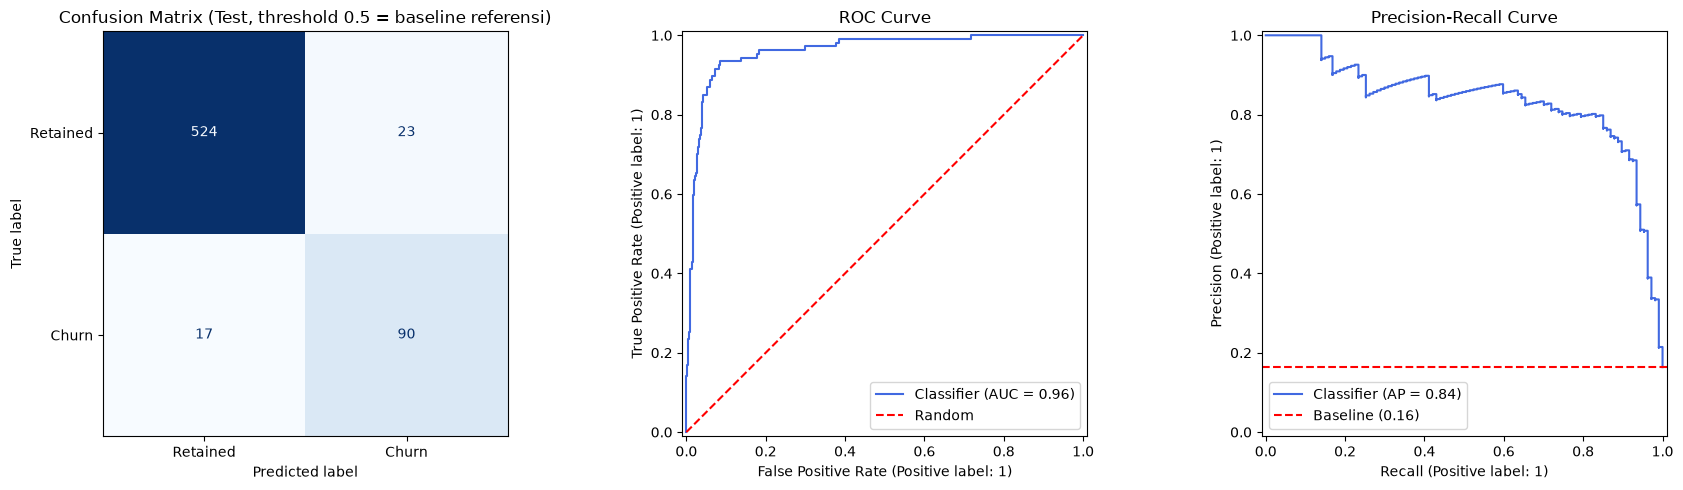

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=['Retained', 'Churn'],
    cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Confusion Matrix (Test, threshold 0.5 = baseline referensi)'); axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, y_prob_test, ax=axes[1])
axes[1].lines[0].set_color('royalblue')          # warnai kurva ROC
axes[1].plot([0, 1], [0, 1], 'r--', label='Random')
axes[1].legend(); axes[1].set_title('ROC Curve'); axes[1].grid(False)

PrecisionRecallDisplay.from_predictions(y_test, y_prob_test, ax=axes[2])
axes[2].lines[0].set_color('royalblue')          # warnai kurva PR
axes[2].axhline(y_test.mean(), color='red', linestyle='--',
                label=f'Baseline ({y_test.mean():.2f})')
axes[2].legend(); axes[2].set_title('Precision-Recall Curve'); axes[2].grid(False)

plt.tight_layout(); plt.show()

**Cara membaca evaluasi:**

* Bandingkan kolom **Train vs Test**: selisih besar (terutama pada *Recall*/*F1*) berarti model masih *overfit*.
* Pada *Confusion Matrix*, perhatikan sel **False Negative** (churn yang lolos) — inilah yang paling merugikan bisnis — dan **False Positive** (promo yang terbuang).
* **PR-AUC** dibandingkan dengan garis *baseline* (proporsi churn): semakin jauh di atas *baseline*, semakin berguna model untuk kelas minoritas.
* **Semua angka di bagian ini memakai *threshold* 0.5 sebagai baseline referensi — bukan *threshold* final.** *Threshold* final dipilih berdasarkan biaya pada bagian 6.3 (*Cost-Benefit*) dan dipakai pada pengecekan *Success Criteria* di bagian 6.4.

<a id="bab-6-1-2"></a>
### 6.1.2 Pemilihan Threshold dan Evaluasi Dampaknya

*Threshold* 0.5 kurang tepat di sini karena kelas tidak seimbang, SMOTE menggeser skor, dan biaya FN jauh lebih besar daripada FP. *Threshold* dipilih **hanya dari prediksi *out-of-fold* (OOF) pada data *train*** — *test set* tidak dipakai untuk memilihnya. Tabel di bawah memperlihatkan *trade-off* Precision–Recall dan apakah tiap *threshold* memenuhi *success criteria*; pemilihan *threshold* final berbasis biaya dilakukan di bagian 6.3.

,Precision,Recall,F1,Ditandai (% pelanggan),Recall ≥ target,Precision ≥ target
Threshold,,,,,,
0.05,0.487,0.890,0.630,29.817,YA,TIDAK
0.10,0.569,0.857,0.684,24.580,YA,YA
0.15,0.621,0.817,0.706,21.483,YA,YA
0.20,0.650,0.792,0.714,19.878,YA,YA
0.25,0.680,0.775,0.724,18.616,YA,YA
0.30,0.701,0.763,0.731,17.775,YA,YA
0.35,0.707,0.733,0.720,16.934,YA,YA
0.40,0.714,0.707,0.711,16.170,YA,YA
0.45,0.738,0.693,0.715,15.329,TIDAK,YA


Threshold yang memenuhi Recall dan Precision target (data train, OOF): [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]


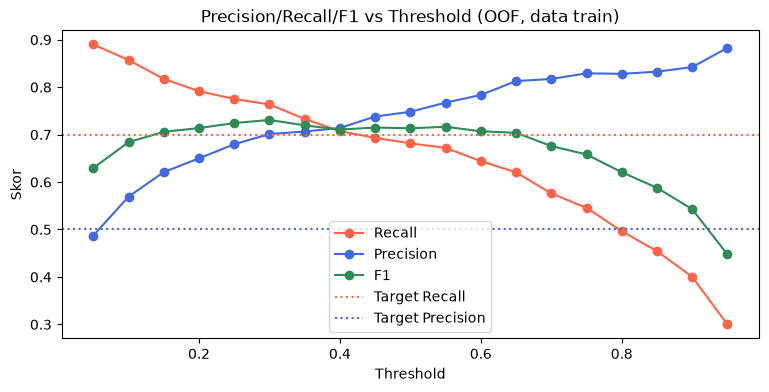

In [121]:
# Prediksi out-of-fold pada data TRAIN (dipakai juga untuk threshold berbasis biaya di bagian 6.3 dan kalibrasi di bagian 6.4)
oof_prob = cross_val_predict(clone(final_pipeline), X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    t = round(float(t), 2)
    pred = (oof_prob >= t).astype(int)
    rec, prec = recall_score(y_train, pred, zero_division=0), precision_score(y_train, pred, zero_division=0)
    rows.append({'Threshold': t, 'Precision': prec, 'Recall': rec,
                 'F1': f1_score(y_train, pred, zero_division=0),
                 'Ditandai (% pelanggan)': pred.mean() * 100,
                 'Recall ≥ target': 'YA' if rec >= SUCCESS_CRITERIA['min_recall'] else 'TIDAK',
                 'Precision ≥ target': 'YA' if prec >= SUCCESS_CRITERIA['min_precision'] else 'TIDAK'})
df_thr_metrics = pd.DataFrame(rows).set_index('Threshold')
display(df_thr_metrics.round(3))

ok_thr = df_thr_metrics[(df_thr_metrics['Recall ≥ target'] == 'YA') & (df_thr_metrics['Precision ≥ target'] == 'YA')]
print("Threshold yang memenuhi Recall dan Precision target (data train, OOF):",
      list(ok_thr.index) if len(ok_thr) else "TIDAK ADA -> kedua target tidak dapat dipenuhi bersamaan pada data train")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(df_thr_metrics.index, df_thr_metrics['Recall'], marker='o', label='Recall', color='tomato')
ax.plot(df_thr_metrics.index, df_thr_metrics['Precision'], marker='o', label='Precision', color='royalblue')
ax.plot(df_thr_metrics.index, df_thr_metrics['F1'], marker='o', label='F1', color='seagreen')
ax.axhline(SUCCESS_CRITERIA['min_recall'], color='tomato', linestyle=':', label='Target Recall')
ax.axhline(SUCCESS_CRITERIA['min_precision'], color='royalblue', linestyle=':', label='Target Precision')
ax.set_xlabel('Threshold'); ax.set_ylabel('Skor'); ax.set_title('Precision/Recall/F1 vs Threshold (OOF, data train)')
ax.legend(); ax.grid(False); plt.show()

**Dampak *threshold* pada test set** (confusion matrix, biaya, ROC/PR, *confidence interval*, dan pengecekan *success criteria*) dievaluasi setelah *threshold* final ditetapkan, yaitu pada bagian 6.3 dan 6.4.

<a id="bab-6-2"></a>
## 6.2 Model Interpretation

<a id="bab-6-2-1"></a>
### 6.2.1 Feature Importance

> **Catatan:** *feature importance* bawaan model dihitung dari data *train*. Jika *permutation importance* atau SHAP dihitung pada data *test* (seperti pada sel di bawah), itu **hanya untuk interpretasi** dan **tidak dipakai** untuk memilih model, fitur, atau *threshold*.

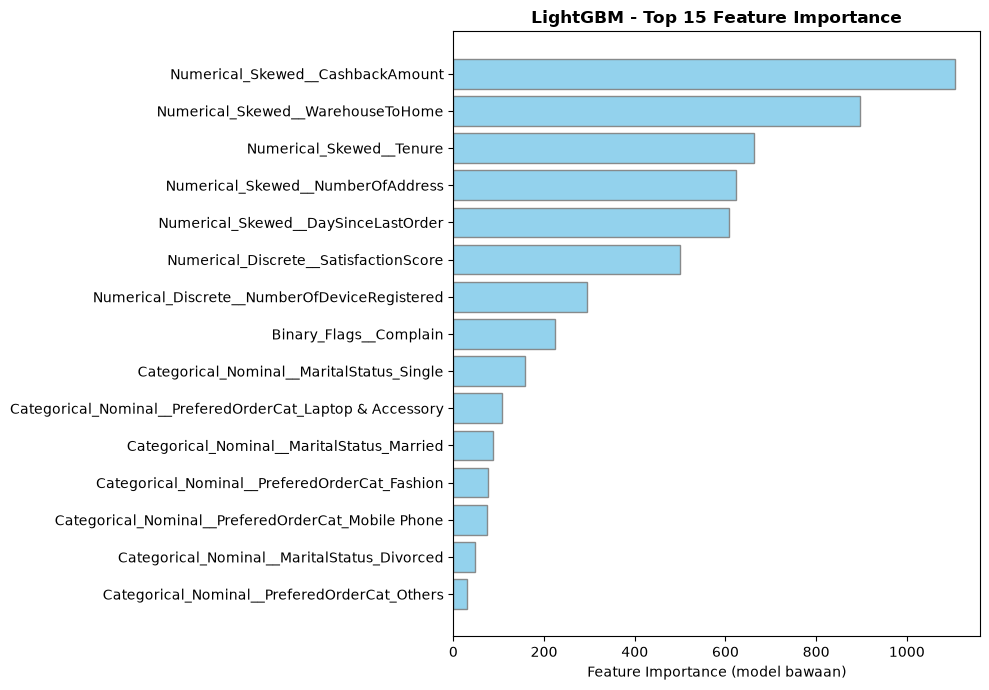

,Feature,Importance
0,Numerical_Skewed__CashbackAmount,1106
1,Numerical_Skewed__WarehouseToHome,896
2,Numerical_Skewed__Tenure,663
3,Numerical_Skewed__NumberOfAddress,623
4,Numerical_Skewed__DaySinceLastOrder,608
5,Numerical_Discrete__SatisfactionScore,499
6,Numerical_Discrete__NumberOfDeviceRegistered,295
7,Binary_Flags__Complain,224
8,Categorical_Nominal__MaritalStatus_Single,159
9,Categorical_Nominal__PreferedOrderCat_Laptop &...,107


In [122]:
pre   = final_pipeline.named_steps['pre']
model = final_pipeline.named_steps['model']
feature_names = list(pre.get_feature_names_out())

X_train_pre = np.asarray(pre.transform(X_train), dtype=np.float64)
X_test_pre  = np.asarray(pre.transform(X_test),  dtype=np.float64)

if hasattr(model, 'feature_importances_'):
    importance, label = model.feature_importances_, 'Feature Importance (model bawaan)'
elif hasattr(model, 'coef_'):
    importance, label = np.abs(model.coef_[0]), 'Absolute Coefficient'
else:  # mis. KNN -> gunakan permutation importance
    # CATATAN: dihitung pada data TEST hanya untuk interpretasi; bukan bagian dari pemilihan model.
    perm = permutation_importance(model, X_test_pre, y_test, scoring='f1', n_repeats=10,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    importance, label = perm.importances_mean, 'Permutation Importance (F1)'

df_importance = (pd.DataFrame({'Feature': feature_names, 'Importance': importance})
                   .sort_values('Importance', ascending=False).reset_index(drop=True))

top = df_importance.head(15).sort_values('Importance', ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(top['Feature'], top['Importance'], color='skyblue', edgecolor='gray', alpha=0.9)
plt.xlabel(label)
plt.title(f'{best_name} - Top 15 Feature Importance', fontsize=12, fontweight='bold')
plt.grid(False); plt.tight_layout(); plt.show()

df_importance.head(15)

<a id="bab-6-2-2"></a>
### 6.2.2 SHAP Value

SHAP menjelaskan **seberapa besar dan ke arah mana** setiap fitur mendorong prediksi churn untuk setiap pelanggan. Pada *beeswarm plot*, warna merah = nilai fitur tinggi, biru = rendah; posisi ke kanan = mendorong prediksi ke arah **churn**.

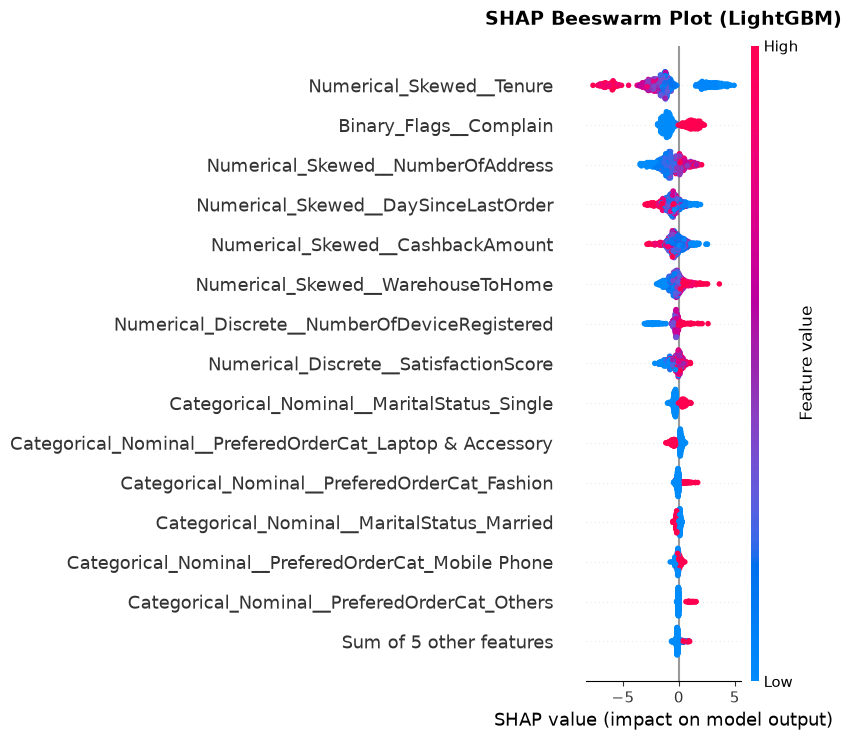

In [123]:
tree_models = (DecisionTreeClassifier, RandomForestClassifier, XGBClassifier, LGBMClassifier)

if isinstance(model, tree_models):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_test_pre)
elif isinstance(model, LogisticRegression):
    explainer = shap.LinearExplainer(model, X_train_pre)
    shap_values = explainer(X_test_pre)
else:
    # model lain (mis. KNN): gunakan KernelExplainer pada sampel kecil
    background = shap.sample(X_train_pre, 100, random_state=RANDOM_STATE)
    kexp = shap.KernelExplainer(lambda d: model.predict_proba(d)[:, 1], background)
    sample = X_test_pre[:100]
    shap_values = shap.Explanation(kexp.shap_values(sample), data=sample)

# Model pohon di sebagian versi SHAP mengeluarkan bentuk (n, fitur, 2 kelas) -> ambil kelas churn (indeks 1)
if getattr(shap_values, 'values', None) is not None and shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap_values.feature_names = feature_names

plt.figure(figsize=(12, 8))
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f'SHAP Beeswarm Plot ({best_name})', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [124]:
# Ringkasan arah pengaruh fitur (SHAP) -> mudah dibaca bisnis
sv = np.asarray(shap_values.values)
rows = []
for j, name in enumerate(feature_names):
    xj, sj = X_test_pre[:, j], sv[:, j]
    corr = np.corrcoef(xj, sj)[0, 1] if (np.std(xj) > 0 and np.std(sj) > 0) else np.nan
    arah = ('nilai tinggi -> churn naik' if corr > 0.15 else 'nilai tinggi -> churn turun' if corr < -0.15
            else 'tidak monoton / lemah')
    rows.append({'Fitur': name.split('__')[-1], 'Mean |SHAP|': np.abs(sj).mean(), 'Korelasi nilai-SHAP': corr, 'Arah pengaruh': arah})
shap_direction = pd.DataFrame(rows).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)
display(shap_direction.head(10).round(3))

,Fitur,Mean |SHAP|,Korelasi nilai-SHAP,Arah pengaruh
0,Tenure,2.470,-0.893,nilai tinggi -> churn turun
1,Complain,1.103,0.929,nilai tinggi -> churn naik
2,NumberOfAddress,0.954,0.779,nilai tinggi -> churn naik
3,DaySinceLastOrder,0.763,-0.573,nilai tinggi -> churn turun
4,CashbackAmount,0.593,-0.485,nilai tinggi -> churn turun
5,WarehouseToHome,0.576,0.753,nilai tinggi -> churn naik
6,NumberOfDeviceRegistered,0.493,0.826,nilai tinggi -> churn naik
7,SatisfactionScore,0.461,0.654,nilai tinggi -> churn naik
8,MaritalStatus_Single,0.388,0.924,nilai tinggi -> churn naik
9,PreferedOrderCat_Laptop & Accessory,0.307,-0.911,nilai tinggi -> churn turun


**Cara membaca:** tabel merangkum beeswarm di atas. Untuk fitur *One-Hot*, "nilai tinggi" berarti kategori tersebut aktif. Bandingkan arahnya dengan EDA dan logika bisnis; arah yang berlawanan (mis. `SatisfactionScore`) perlu ditelaah dan **tidak boleh** dibaca sebagai hubungan sebab-akibat.

**Cara membaca SHAP:** fitur di bagian atas adalah yang paling berpengaruh. Cek apakah arahnya sejalan dengan temuan EDA — misalnya, *tenure* rendah seharusnya mendorong prediksi ke arah churn, dan riwayat komplain juga mendorong ke arah churn. Jika arahnya berlawanan dengan logika bisnis (seperti `SatisfactionScore`), hasilnya perlu ditelaah lebih lanjut dan tidak boleh langsung dianggap sebagai hubungan sebab-akibat.

<a id="bab-6-2-3"></a>
### 6.2.3 Interpretasi sebagai Asosiasi, Bukan Sebab-Akibat

* *Feature importance* dan SHAP menunjukkan **fitur apa yang dipakai model dan ke arah mana skornya bergeser** — yaitu pola prediktif/asosiasi pada data ini.
* Hasil ini **bukan bukti** bahwa mengubah suatu fitur (mis. menaikkan *cashback* atau menurunkan jumlah komplain) akan mengubah keputusan pelanggan. Pengaruh intervensi hanya dapat dibuktikan lewat eksperimen terkontrol (bagian 7.2).
* Arah yang berlawanan dengan logika bisnis (mis. `SatisfactionScore`) perlu ditelaah bersama tim pemilik data sebelum dijadikan dasar kebijakan.
* *Importance* dan SHAP dihitung pada data *test* **hanya untuk interpretasi**; tidak dipakai untuk memilih model, fitur, atau *threshold*.

<a id="bab-6-3"></a>
## 6.3 Business & Cost-Benefit Evaluation

> **Pemisahan klaim:** seluruh angka **rupiah** pada bagian ini adalah **simulasi berdasarkan asumsi** (`LOST_VALUE`, `CAMPAIGN_COST`, `SUCCESS_RATE`), **bukan hasil aktual**. Hanya metrik teknis (Recall, Precision, F1, ROC-AUC, PR-AUC) yang terukur dari data. Gantilah asumsi dengan angka riil dari Finance/Marketing, lalu validasi lewat A/B test (bagian 7.2).

<a id="bab-6-3-1"></a>
### 6.3.1 Definisi Biaya Kampanye, Margin Kontribusi, dan Biaya FP/FN

Nilai biaya di bawah ini adalah **asumsi ilustratif** dan harus diganti dengan angka riil dari tim *Finance/Marketing*.

| Parameter | Nilai Asumsi | Penjelasan |
| :--- | :--- | :--- |
| `LOST_VALUE` | **Rp 500.000** | **Margin kontribusi** yang hilang jika satu pelanggan churn dan tidak diselamatkan (dasar biaya *False Negative*). |
| `CAMPAIGN_COST` | **Rp 50.000** | Biaya intervensi retensi (voucher/promo) per pelanggan yang ditargetkan (terbuang jika pelanggan sebenarnya loyal = biaya *False Positive*). |
| `SUCCESS_RATE` | **30%** | Peluang pelanggan yang benar-benar akan churn berhasil diselamatkan setelah diberi intervensi. |

**Logika biaya per skenario (pada data *test*):**

* **Tanpa kampanye:** semua pelanggan churn hilang → `jumlah churn × LOST_VALUE`.
* **Kampanye ke semua pelanggan:** biaya promo untuk semua pelanggan + kerugian dari churner yang tidak berhasil diselamatkan.
* **Dengan model:** hanya pelanggan yang diprediksi churn (TP + FP) yang diberi promo. Kerugian muncul dari FN (churn yang lolos) dan dari TP yang gagal diselamatkan.

Karena kerugian FN (Rp 500.000) jauh lebih besar daripada biaya FP (Rp 50.000), *threshold* keputusan dipilih agar **total biaya minimum**, bukan sekadar 0.5.

In [125]:
# ======================= PARAMETER BISNIS (ASUMSI - SESUAIKAN) =======================
LOST_VALUE    = 500_000   # Rp per pelanggan churn yang tidak diselamatkan
CAMPAIGN_COST = 50_000    # Rp per pelanggan yang ditargetkan kampanye retensi
SUCCESS_RATE  = 0.30      # peluang churner berhasil diselamatkan jika ditargetkan
# =====================================================================================

def total_cost(y_true, y_pred, lost_value=LOST_VALUE, campaign_cost=CAMPAIGN_COST, success_rate=SUCCESS_RATE):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    targeted = tp + fp
    lost = fn + tp * (1 - success_rate)
    return targeted * campaign_cost + lost * lost_value

<a id="bab-6-3-2"></a>
### 6.3.2 Threshold Berdasarkan Biaya/Manfaat

,Precision,Recall,F1,Total Cost (Rp Juta)
Threshold,,,,
0.05,0.487,0.890,0.630,195.50
0.10,0.569,0.857,0.684,190.75
0.15,0.621,0.817,0.706,189.25
0.20,0.650,0.792,0.714,188.80
0.25,0.680,0.775,0.724,188.20
0.30,0.701,0.763,0.731,187.85
0.35,0.707,0.733,0.720,188.70
0.40,0.714,0.707,0.711,189.35
0.45,0.738,0.693,0.715,189.15



Threshold optimal (biaya minimum pada data train/OOF): 0.3


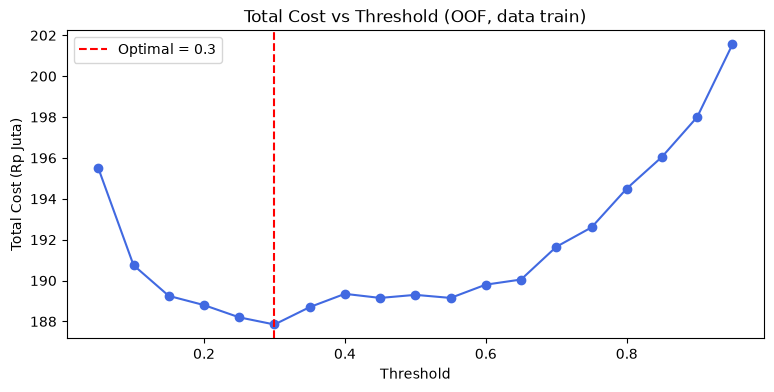

In [126]:
# Threshold dipilih dari biaya minimum pada prediksi out-of-fold data TRAIN (oof_prob dari bagian 6.1). Test tidak disentuh.
df_thr = df_thr_metrics[['Precision', 'Recall', 'F1']].copy()
df_thr['Total Cost (Rp Juta)'] = [total_cost(y_train, (oof_prob >= t).astype(int)) / 1e6 for t in df_thr.index]
best_threshold = df_thr['Total Cost (Rp Juta)'].idxmin()
display(df_thr.round(3))
print(f"\nThreshold optimal (biaya minimum pada data train/OOF): {best_threshold}")

plt.figure(figsize=(9, 4))
plt.plot(df_thr.index, df_thr['Total Cost (Rp Juta)'], marker='o', color='royalblue')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Optimal = {best_threshold}')
plt.xlabel('Threshold'); plt.ylabel('Total Cost (Rp Juta)'); plt.title('Total Cost vs Threshold (OOF, data train)')
plt.legend(); plt.grid(False); plt.show()

<a id="bab-6-3-3"></a>
### 6.3.3 Evaluasi pada Test Set: Tiga Skenario Biaya

                 COST-BENEFIT ANALYSIS REPORT
• Model                               : LightGBM (threshold = 0.3)
• Total pelanggan (Test Set)          : 654
• Pelanggan churn aktual              : 107
• Hasil model -> TP: 98 | FP: 40 | FN: 9 | TN: 507
• Recall: 91.59% | Precision: 71.01%
------------------------------------------------------------------
Biaya TANPA kampanye                 : Rp 53.5 juta
Biaya kampanye ke SEMUA pelanggan    : Rp 70.2 juta
Biaya DENGAN MODEL                   : Rp 45.7 juta
------------------------------------------------------------------
Penghematan vs tanpa kampanye        : Rp 7.8 juta (14.6%)
Penghematan vs kampanye semua        : Rp 24.4 juta (34.9%)


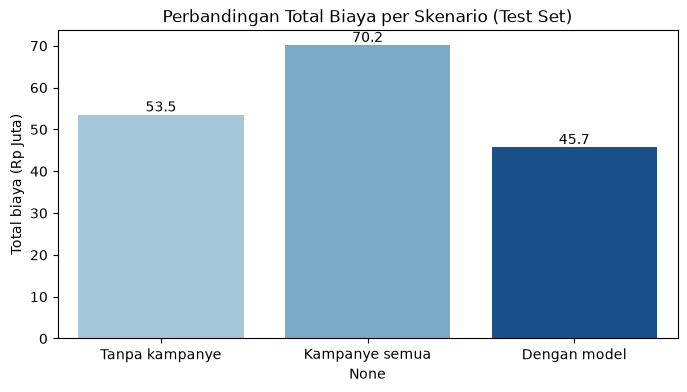

In [127]:
# --- Terapkan threshold terpilih ke data TEST dan bandingkan 3 skenario ---
y_pred_opt = (y_prob_test >= best_threshold).astype(int)
y_true = np.asarray(y_test)
N, n_churn = len(y_true), int(y_true.sum())

cost_no_campaign = n_churn * LOST_VALUE
cost_campaign_all = N * CAMPAIGN_COST + n_churn * (1 - SUCCESS_RATE) * LOST_VALUE
cost_model = total_cost(y_true, y_pred_opt)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred_opt).ravel()

print("=" * 66)
print("                 COST-BENEFIT ANALYSIS REPORT")
print("=" * 66)
print(f"• Model                               : {best_name} (threshold = {best_threshold})")
print(f"• Total pelanggan (Test Set)          : {N:,}")
print(f"• Pelanggan churn aktual              : {n_churn:,}")
print(f"• Hasil model -> TP: {tp} | FP: {fp} | FN: {fn} | TN: {tn}")
print(f"• Recall: {tp/(tp+fn):.2%} | Precision: {tp/(tp+fp):.2%}")
print("-" * 66)
print(f"Biaya TANPA kampanye                 : Rp {cost_no_campaign/1e6:,.1f} juta")
print(f"Biaya kampanye ke SEMUA pelanggan    : Rp {cost_campaign_all/1e6:,.1f} juta")
print(f"Biaya DENGAN MODEL                   : Rp {cost_model/1e6:,.1f} juta")
print("-" * 66)
print(f"Penghematan vs tanpa kampanye        : Rp {(cost_no_campaign-cost_model)/1e6:,.1f} juta ({(cost_no_campaign-cost_model)/cost_no_campaign:.1%})")
print(f"Penghematan vs kampanye semua        : Rp {(cost_campaign_all-cost_model)/1e6:,.1f} juta ({(cost_campaign_all-cost_model)/cost_campaign_all:.1%})")
print("=" * 66)

cmp = pd.Series({'Tanpa kampanye': cost_no_campaign, 'Kampanye semua': cost_campaign_all, 'Dengan model': cost_model}) / 1e6
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=cmp.index, y=cmp.values, hue=cmp.index, palette=['#9ecae1', '#6baed6', '#08519c'], legend=False)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.1f}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.ylabel('Total biaya (Rp Juta)'); plt.title('Perbandingan Total Biaya per Skenario (Test Set)'); plt.grid(False)
plt.show()

<a id="bab-6-3-4"></a>
### 6.3.4 Confusion Matrix pada Threshold Final

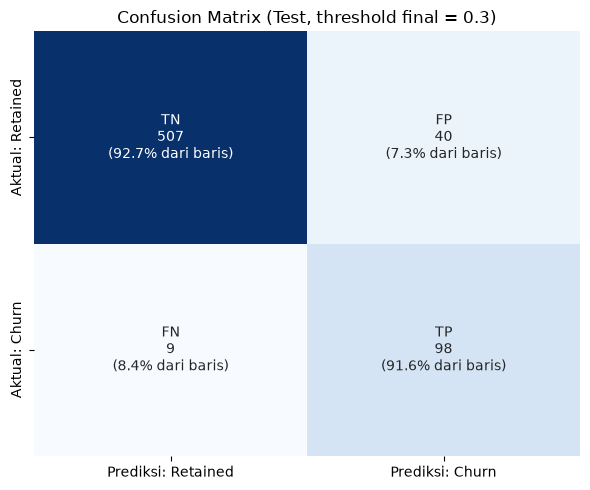

TP=98 | FP=40 | FN=9 | TN=507 | Total=654
Recall    = TP/(TP+FN) = 98/107 = 91.59%
Precision = TP/(TP+FP) = 98/138 = 71.01%


In [128]:
# Confusion Matrix pada threshold FINAL (berbasis biaya)
cm = confusion_matrix(y_true, y_pred_opt)          # [[TN, FP], [FN, TP]]
tn, fp, fn, tp = cm.ravel()

labels = [['TN', 'FP'], ['FN', 'TP']]
annot = [[f"{labels[i][j]}\n{cm[i, j]:,}\n({cm[i, j]/cm[i].sum():.1%} dari baris)"
          for j in range(2)] for i in range(2)]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Prediksi: Retained', 'Prediksi: Churn'],
            yticklabels=['Aktual: Retained', 'Aktual: Churn'])
ax.set_title(f'Confusion Matrix (Test, threshold final = {best_threshold})')
plt.tight_layout(); plt.show()

print(f"TP={tp} | FP={fp} | FN={fn} | TN={tn} | Total={cm.sum()}")
print(f"Recall    = TP/(TP+FN) = {tp}/{tp+fn} = {tp/(tp+fn):.2%}")
print(f"Precision = TP/(TP+FP) = {tp}/{tp+fp} = {tp/(tp+fp):.2%}")

<a id="bab-6-3-5"></a>
### 6.3.5 Net Incremental Profit dan ROI (Simulasi)

*Net incremental profit* = margin yang berhasil dipertahankan (nilai harapan, bergantung `SUCCESS_RATE`) − biaya kampanye. Nilainya identik dengan penghematan terhadap skenario "tanpa kampanye". **ROI** = *net incremental profit* ÷ biaya kampanye. Keduanya adalah **simulasi asumsi**, bukan hasil aktual.

In [129]:
targeted = tp + fp
campaign_spend = targeted * CAMPAIGN_COST
expected_saved_value = tp * SUCCESS_RATE * LOST_VALUE                 # margin yang dipertahankan (nilai harapan)
net_incremental_profit = expected_saved_value - campaign_spend
roi_campaign = net_incremental_profit / campaign_spend if campaign_spend else np.nan

# konsistensi: harus sama dengan penghematan terhadap skenario 'tanpa kampanye'
assert np.isclose(net_incremental_profit, cost_no_campaign - cost_model), "Net profit tidak konsisten dengan biaya skenario"

sim_summary = pd.Series({
    'Pelanggan ditargetkan (TP + FP)'            : f"{targeted:,}",
    'Biaya kampanye (Rp juta)'                   : f"{campaign_spend / 1e6:,.1f}",
    'Margin dipertahankan, nilai harapan (Rp juta)': f"{expected_saved_value / 1e6:,.1f}",
    'Net incremental profit (Rp juta)'           : f"{net_incremental_profit / 1e6:,.1f}",
    'ROI kampanye'                               : f"{roi_campaign:.1%}" if campaign_spend else 'n/a',
    'Status'                                     : 'SIMULASI (asumsi LOST_VALUE, CAMPAIGN_COST, SUCCESS_RATE)',
}, name='Nilai')
display(sim_summary.to_frame())

,Nilai
Pelanggan ditargetkan (TP + FP),138
Biaya kampanye (Rp juta),6.9
"Margin dipertahankan, nilai harapan (Rp juta)",14.7
Net incremental profit (Rp juta),7.8
ROI kampanye,113.0%
Status,"SIMULASI (asumsi LOST_VALUE, CAMPAIGN_COST, SU..."


<a id="bab-6-3-6"></a>
### 6.3.6 Sensitivity Analysis Asumsi Bisnis

In [130]:
sens = []
tp_s = int(((y_true == 1) & (y_pred_opt == 1)).sum())
targeted_s = int(y_pred_opt.sum())
for sr in [0.10, 0.20, 0.30, 0.50]:
    for lv in [300_000, 500_000, 1_000_000]:
        base_none = n_churn * lv
        base_all  = N * CAMPAIGN_COST + n_churn * (1 - sr) * lv
        c_model   = total_cost(y_true, y_pred_opt, lost_value=lv, success_rate=sr)
        roi_s = (tp_s * sr * lv - targeted_s * CAMPAIGN_COST) / (targeted_s * CAMPAIGN_COST) * 100 if targeted_s else np.nan
        sens.append({'Success Rate': f'{sr:.0%}', 'Lost Value (Rp)': f'{lv:,}',
                     'Hemat vs Tanpa Kampanye (Rp Juta)': round((base_none - c_model) / 1e6, 1),
                     'Hemat vs Kampanye Semua (Rp Juta)': round((base_all - c_model) / 1e6, 1),
                     'ROI kampanye (%)': round(roi_s, 1)})
display(pd.DataFrame(sens))

,Success Rate,Lost Value (Rp),Hemat vs Tanpa Kampanye (Rp Juta),Hemat vs Kampanye Semua (Rp Juta),ROI kampanye (%)
0,10%,"300,000",-4.0,25.5,-57.4
1,10%,"500,000",-2.0,25.4,-29.0
2,10%,"1,000,000",2.9,24.9,42.0
3,20%,"300,000",-1.0,25.3,-14.8
4,20%,"500,000",2.9,24.9,42.0
5,20%,"1,000,000",12.7,24.0,184.1
6,30%,"300,000",1.9,25.0,27.8
7,30%,"500,000",7.8,24.4,113.0
8,30%,"1,000,000",22.5,23.1,326.1
9,50%,"300,000",7.8,24.4,113.0


#### Cara Membaca Hasil Cost-Benefit

* Bandingkan **tiga skenario** pada grafik/tabel di atas. Model dianggap bermanfaat bila biayanya **lebih rendah** daripada dua alternatif sederhana (tanpa kampanye dan kampanye ke semua pelanggan).
* Tabel **sensitivitas** menunjukkan seberapa kuat kesimpulan terhadap asumsi. Jika model hanya menguntungkan pada asumsi *success rate* yang sangat tinggi, berhati-hatilah sebelum implementasi.
* Angka rupiah di sini bergantung pada asumsi — **gantilah `LOST_VALUE`, `CAMPAIGN_COST`, dan `SUCCESS_RATE` dengan angka riil perusahaan** lalu jalankan ulang sel di atas.

<a id="bab-6-4"></a>
## 6.4 Statistical Reliability & Calibration

<a id="bab-6-4-1"></a>
### 6.4.1 Ketidakpastian Hasil Test (Bootstrap Confidence Interval)

*Test set* hanya berisi sekitar 650 baris dengan sekitar 100 pelanggan churn, sehingga *Recall* dan *Precision* bisa bergeser beberapa poin hanya karena kebetulan pembagian data. Untuk itu dihitung ***confidence interval* 95%** dengan ***bootstrap*** (resampling baris *test* dengan pengembalian, 2.000 kali). Penghematan biaya (Rp juta) juga diberi interval agar kesimpulan bisnisnya tidak bergantung pada satu angka.

In [131]:
N_BOOT = 2000
rng = np.random.default_rng(RANDOM_STATE)

y_arr      = np.asarray(y_test)
pred_final = (y_prob_test >= best_threshold).astype(int)   # threshold FINAL (berbasis biaya)
pred_base  = (y_prob_test >= 0.5).astype(int)              # threshold 0.5 (baseline referensi)

def _all_metrics(idx):
    yt, pr, pf, pb = y_arr[idx], y_prob_test[idx], pred_final[idx], pred_base[idx]
    n, n_ch = len(yt), int(yt.sum())
    cost_none = n_ch * LOST_VALUE
    cost_all  = n * CAMPAIGN_COST + n_ch * (1 - SUCCESS_RATE) * LOST_VALUE
    cost_mod  = total_cost(yt, pf)
    return {
        'Recall (threshold final)'    : recall_score(yt, pf, zero_division=0),
        'Precision (threshold final)' : precision_score(yt, pf, zero_division=0),
        'F1 (threshold final)'        : f1_score(yt, pf, zero_division=0),
        'Recall (threshold 0.5)'      : recall_score(yt, pb, zero_division=0),
        'Precision (threshold 0.5)'   : precision_score(yt, pb, zero_division=0),
        'ROC-AUC'                     : roc_auc_score(yt, pr),
        'PR-AUC'                      : average_precision_score(yt, pr),
        'Hemat vs tanpa kampanye (Rp juta)': (cost_none - cost_mod) / 1e6,
        'Hemat vs kampanye semua (Rp juta)': (cost_all  - cost_mod) / 1e6,
    }

point = _all_metrics(np.arange(len(y_arr)))
boot = pd.DataFrame([_all_metrics(rng.integers(0, len(y_arr), len(y_arr))) for _ in range(N_BOOT)])

ci_df = pd.DataFrame({
    'Point'   : pd.Series(point),
    'CI low'  : boot.quantile(0.025),
    'CI high' : boot.quantile(0.975),
})
ci_df.index = ['Recall', 'Precision', 'F1', 'Recall (0.5)', 'Precision (0.5)', 'ROC-AUC', 'PR-AUC',
               'Hemat vs tanpa kampanye', 'Hemat vs kampanye semua']
print(f"Test set: {len(y_arr)} baris, {int(y_arr.sum())} churn | bootstrap {N_BOOT:,}x | threshold final = {best_threshold}")
display(ci_df.round(3))

Test set: 654 baris, 107 churn | bootstrap 2,000x | threshold final = 0.3


,Point,CI low,CI high
Recall,0.916,0.863,0.964
Precision,0.710,0.631,0.784
F1,0.800,0.741,0.851
Recall (0.5),0.841,0.767,0.907
Precision (0.5),0.796,0.718,0.869
ROC-AUC,0.960,0.939,0.977
PR-AUC,0.838,0.764,0.901
Hemat vs tanpa kampanye,7.800,5.850,9.700
Hemat vs kampanye semua,24.450,23.100,25.750


**Cara membaca:** rentang `CI low`–`CI high` adalah rentang wajar nilai metrik jika *test set* diambil ulang dari populasi yang sama. Rentang yang lebar berarti angka pada satu *test set* sebaiknya dibaca sebagai perkiraan. Kolom penghematan: jika `CI low` bernilai negatif, model **belum pasti** lebih murah daripada pembanding pada asumsi biaya yang dipakai.

<a id="bab-6-4-2"></a>
### 6.4.2 Pengecekan Success Criteria

Hasil akhir pada *test set* dibandingkan dengan kriteria yang ditetapkan di *Business Understanding*. Setiap kriteria dinilai berdasarkan **estimasi titik** dan **batas bawah CI 95%** (kriteria "kokoh").

In [132]:
def _status(ok):
    return 'YA' if ok else 'TIDAK'

rows = [
    {'Kriteria': f"Recall ≥ {SUCCESS_CRITERIA['min_recall']:.2f}",
     'Hasil (point)': ci_df.loc['Recall', 'Point'], 'Batas bawah CI': ci_df.loc['Recall', 'CI low'],
     'Lolos (point)': _status(ci_df.loc['Recall', 'Point'] >= SUCCESS_CRITERIA['min_recall']),
     'Lolos (kokoh, CI bawah)': _status(ci_df.loc['Recall', 'CI low'] >= SUCCESS_CRITERIA['min_recall'])},
    {'Kriteria': f"Precision ≥ {SUCCESS_CRITERIA['min_precision']:.2f}",
     'Hasil (point)': ci_df.loc['Precision', 'Point'], 'Batas bawah CI': ci_df.loc['Precision', 'CI low'],
     'Lolos (point)': _status(ci_df.loc['Precision', 'Point'] >= SUCCESS_CRITERIA['min_precision']),
     'Lolos (kokoh, CI bawah)': _status(ci_df.loc['Precision', 'CI low'] >= SUCCESS_CRITERIA['min_precision'])},
    {'Kriteria': 'Biaya model < tanpa kampanye (hemat > 0, Rp juta)',
     'Hasil (point)': ci_df.loc['Hemat vs tanpa kampanye', 'Point'], 'Batas bawah CI': ci_df.loc['Hemat vs tanpa kampanye', 'CI low'],
     'Lolos (point)': _status(ci_df.loc['Hemat vs tanpa kampanye', 'Point'] > 0),
     'Lolos (kokoh, CI bawah)': _status(ci_df.loc['Hemat vs tanpa kampanye', 'CI low'] > 0)},
    {'Kriteria': 'Biaya model < kampanye semua (hemat > 0, Rp juta)',
     'Hasil (point)': ci_df.loc['Hemat vs kampanye semua', 'Point'], 'Batas bawah CI': ci_df.loc['Hemat vs kampanye semua', 'CI low'],
     'Lolos (point)': _status(ci_df.loc['Hemat vs kampanye semua', 'Point'] > 0),
     'Lolos (kokoh, CI bawah)': _status(ci_df.loc['Hemat vs kampanye semua', 'CI low'] > 0)},
]
success_df = pd.DataFrame(rows).set_index('Kriteria')
display(success_df.round(3))

all_pass_point  = bool((success_df['Lolos (point)'] == 'YA').all())
all_pass_robust = bool((success_df['Lolos (kokoh, CI bawah)'] == 'YA').all())
print(f"Semua kriteria terpenuhi (estimasi titik)        : {_status(all_pass_point)}")
print(f"Semua kriteria terpenuhi (kokoh / batas bawah CI): {_status(all_pass_robust)}")
if all_pass_point and not all_pass_robust:
    print("-> Target tercapai pada estimasi titik, tetapi belum kokoh terhadap ketidakpastian test set; "
          "validasi lebih lanjut (data lebih banyak / uji lapangan) disarankan sebelum implementasi penuh.")

,Hasil (point),Batas bawah CI,Lolos (point),"Lolos (kokoh, CI bawah)"
Kriteria,,,,
Recall ≥ 0.70,0.916,0.863,YA,YA
Precision ≥ 0.50,0.710,0.631,YA,YA
"Biaya model < tanpa kampanye (hemat > 0, Rp juta)",7.800,5.850,YA,YA
"Biaya model < kampanye semua (hemat > 0, Rp juta)",24.450,23.100,YA,YA


Semua kriteria terpenuhi (estimasi titik)        : YA
Semua kriteria terpenuhi (kokoh / batas bawah CI): YA


<a id="bab-6-4-3"></a>
### 6.4.3 Laporan Metrik Lengkap (termasuk *Accuracy*)

Seluruh metrik yang disarankan dilaporkan pada *threshold* final dan *threshold* 0,5 (baseline referensi), beserta pembanding **model tanpa kemampuan** yang menebak "tidak churn" untuk semua pelanggan. *Accuracy* ditampilkan **hanya sebagai pelengkap**: karena kelas tidak seimbang, model yang tidak berguna sekalipun sudah mendapat *accuracy* tinggi.

In [133]:
def _metric_row(label, pred, prob):
    return {'Skenario': label,
            'Accuracy': accuracy_score(y_test, pred),
            'Balanced Accuracy': (recall_score(y_test, pred) + recall_score(y_test, pred, pos_label=0)) / 2,
            'Recall': recall_score(y_test, pred, zero_division=0),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'PR-AUC': average_precision_score(y_test, prob) if prob is not None else np.nan,
            'ROC-AUC': roc_auc_score(y_test, prob) if prob is not None else np.nan}

metric_report = pd.DataFrame([
    _metric_row(f'Model, threshold FINAL ({best_threshold})', (y_prob_test >= best_threshold).astype(int), y_prob_test),
    _metric_row('Model, threshold 0.5 (baseline referensi)', (y_prob_test >= 0.5).astype(int), y_prob_test),
    _metric_row("Tanpa model: semua 'tidak churn'", np.zeros(len(y_test), dtype=int), None),
]).set_index('Skenario')
display(metric_report.round(4))
print(f"Accuracy majority-class = {1 - y_test.mean():.2%} -> accuracy model harus dibaca relatif terhadap angka ini; "
      f"ukuran keberhasilan utama tetap Recall, Precision, F1, dan PR-AUC (baseline PR-AUC = proporsi churn {y_test.mean():.2%}).")

,Accuracy,Balanced Accuracy,Recall,Precision,F1,PR-AUC,ROC-AUC
Skenario,,,,,,,
"Model, threshold FINAL (0.3)",0.9251,0.9214,0.9159,0.7101,0.8000,0.8381,0.9602
"Model, threshold 0.5 (baseline referensi)",0.9388,0.8995,0.8411,0.7965,0.8182,0.8381,0.9602
Tanpa model: semua 'tidak churn',0.8364,0.5000,0.0000,0.0000,0.0000,NaN,NaN


Accuracy majority-class = 83.64% -> accuracy model harus dibaca relatif terhadap angka ini; ukuran keberhasilan utama tetap Recall, Precision, F1, dan PR-AUC (baseline PR-AUC = proporsi churn 16.36%).


<a id="bab-6-4-4"></a>
### 6.4.4 Analisis Sensitivitas Threshold

*Threshold* final **tetap** `best_threshold` (dipilih dari data *train*). Tabel di bawah hanya **analisis** pada *test set* untuk melihat seberapa sensitif Recall, Precision, dan biaya terhadap pergeseran *threshold*; hasilnya **tidak dipakai untuk memilih ulang** *threshold*.

,Recall,Precision,F1,Ditandai (%),Biaya model (Rp juta),Recall ≥ target,Precision ≥ target
Threshold,,,,,,,
0.05,0.963,0.486,0.646,32.416,48.65,YA,TIDAK
0.10,0.944,0.567,0.709,27.217,47.25,YA,YA
0.15,0.935,0.613,0.741,24.924,46.65,YA,YA
0.20,0.935,0.629,0.752,24.312,46.45,YA,YA
0.25,0.935,0.671,0.781,22.783,45.95,YA,YA
0.30,0.916,0.710,0.800,21.101,45.70,YA,YA
0.35,0.897,0.733,0.807,20.031,45.65,YA,YA
0.40,0.869,0.762,0.812,18.654,45.65,YA,YA
0.45,0.850,0.784,0.816,17.737,45.65,YA,YA


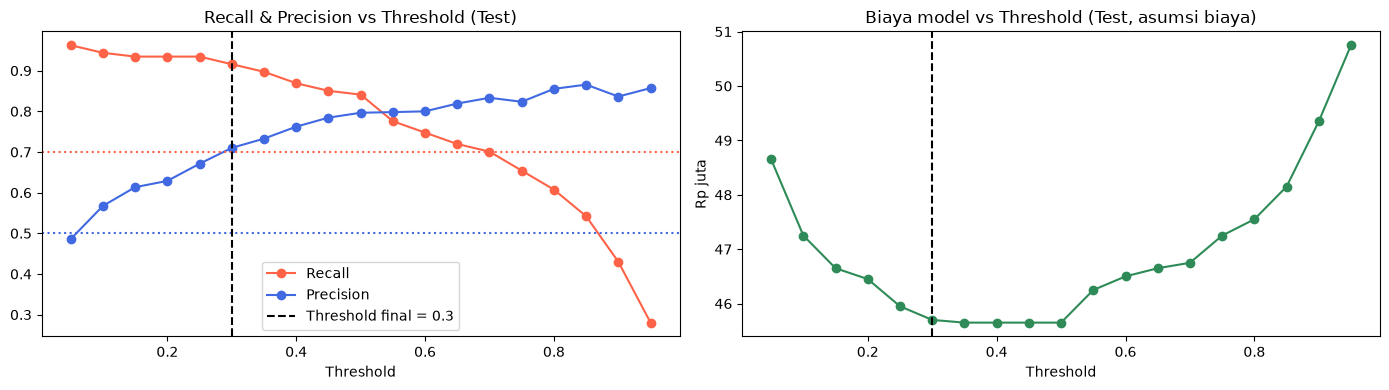

In [134]:
rows = []
for t in np.arange(0.05, 0.96, 0.05):
    t = round(float(t), 2)
    pred = (y_prob_test >= t).astype(int)
    rec, prec = recall_score(y_test, pred, zero_division=0), precision_score(y_test, pred, zero_division=0)
    rows.append({'Threshold': t, 'Recall': rec, 'Precision': prec, 'F1': f1_score(y_test, pred, zero_division=0),
                 'Ditandai (%)': pred.mean() * 100, 'Biaya model (Rp juta)': total_cost(y_test, pred) / 1e6,
                 'Recall ≥ target': 'YA' if rec >= SUCCESS_CRITERIA['min_recall'] else 'TIDAK',
                 'Precision ≥ target': 'YA' if prec >= SUCCESS_CRITERIA['min_precision'] else 'TIDAK'})
thr_sens = pd.DataFrame(rows).set_index('Threshold')
display(thr_sens.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(thr_sens.index, thr_sens['Recall'], marker='o', color='tomato', label='Recall')
ax[0].plot(thr_sens.index, thr_sens['Precision'], marker='o', color='royalblue', label='Precision')
ax[0].axhline(SUCCESS_CRITERIA['min_recall'], color='tomato', linestyle=':')
ax[0].axhline(SUCCESS_CRITERIA['min_precision'], color='royalblue', linestyle=':')
ax[0].axvline(best_threshold, color='black', linestyle='--', label=f'Threshold final = {best_threshold}')
ax[0].set_xlabel('Threshold'); ax[0].set_title('Recall & Precision vs Threshold (Test)'); ax[0].legend(); ax[0].grid(False)
ax[1].plot(thr_sens.index, thr_sens['Biaya model (Rp juta)'], marker='o', color='seagreen')
ax[1].axvline(best_threshold, color='black', linestyle='--')
ax[1].set_xlabel('Threshold'); ax[1].set_ylabel('Rp juta'); ax[1].set_title('Biaya model vs Threshold (Test, asumsi biaya)'); ax[1].grid(False)
plt.tight_layout(); plt.show()

<a id="bab-6-4-5"></a>
### 6.4.5 Kalibrasi Probabilitas

SMOTE menyeimbangkan kelas saat pelatihan, dan *threshold* dipilih rendah berdasarkan biaya, sehingga skor model (`predict_proba`) **tidak otomatis sama dengan peluang churn sebenarnya**. Ini tidak masalah selama keputusan hanya memakai *threshold* yang dipilih (peringkat risiko). Tetapi jika skor dibaca sebagai "peluang churn 70%", kalibrasi perlu dicek.

Yang dilakukan di bawah:

* ***Calibration curve*** dan ***Brier score*** pada *test set* untuk skor mentah. Kurva ideal berimpit dengan garis diagonal; Brier score lebih rendah lebih baik (pembanding: memprediksi proporsi churn untuk semua orang).
* Skor dikalibrasi ulang dengan ***Platt scaling*** yang **dilatih dari prediksi *out-of-fold* data *train*** (`oof_prob`) — data *test* tidak dipakai untuk melatih kalibrator.
* Kalibrator hanya mengubah **cara melaporkan probabilitas**. Keputusan churn tetap memakai skor mentah dan `best_threshold`, sehingga hasil Cost-Benefit tidak berubah.

,Rata-rata skor prediksi,Proporsi churn aktual (test),Brier score
Skor mentah (SMOTE + model),0.1813,0.1636,0.0512
Setelah Platt scaling,0.1831,0.1636,0.0534


Brier score pembanding (prediksi proporsi churn untuk semua): 0.1366
Skor mentah pada threshold final 0.3 setara dengan probabilitas terkalibrasi ≈ 0.32


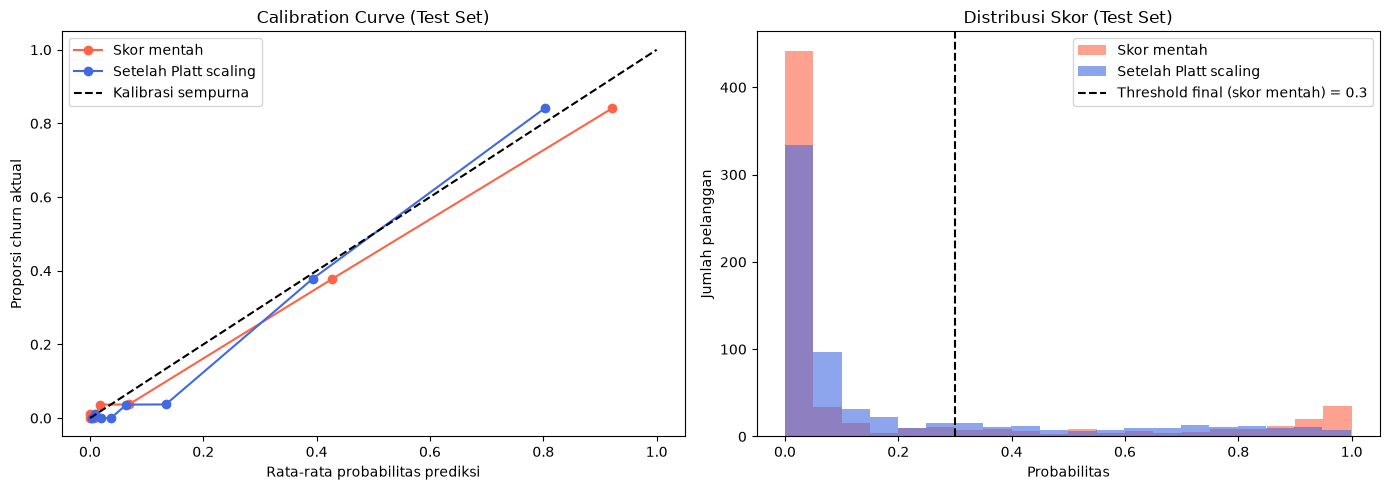

In [135]:
EPS = 1e-6
def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p)).reshape(-1, 1)

# Platt scaling: dilatih dari prediksi out-of-fold data TRAIN (oof_prob dari bagian threshold)
platt = LogisticRegression(C=1e6, max_iter=1000)
platt.fit(_logit(oof_prob), y_train)
prob_test_cal = platt.predict_proba(_logit(y_prob_test))[:, 1]

brier_baseline = y_train.mean() * (1 - y_train.mean())   # selalu memprediksi proporsi churn train
calib_summary = pd.DataFrame({
    'Rata-rata skor prediksi': [y_prob_test.mean(), prob_test_cal.mean()],
    'Proporsi churn aktual (test)': [y_test.mean(), y_test.mean()],
    'Brier score': [brier_score_loss(y_test, y_prob_test), brier_score_loss(y_test, prob_test_cal)],
}, index=['Skor mentah (SMOTE + model)', 'Setelah Platt scaling'])
display(calib_summary.round(4))
print(f"Brier score pembanding (prediksi proporsi churn untuk semua): {brier_baseline:.4f}")
print(f"Skor mentah pada threshold final {best_threshold} setara dengan probabilitas terkalibrasi "
      f"≈ {platt.predict_proba(_logit([best_threshold]))[0, 1]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for prob, label, color in [(y_prob_test, 'Skor mentah', 'tomato'), (prob_test_cal, 'Setelah Platt scaling', 'royalblue')]:
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=8, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, marker='o', label=label, color=color)
axes[0].plot([0, 1], [0, 1], 'k--', label='Kalibrasi sempurna')
axes[0].set_xlabel('Rata-rata probabilitas prediksi'); axes[0].set_ylabel('Proporsi churn aktual')
axes[0].set_title('Calibration Curve (Test Set)'); axes[0].legend(); axes[0].grid(False)

axes[1].hist(y_prob_test, bins=20, alpha=0.6, color='tomato', label='Skor mentah')
axes[1].hist(prob_test_cal, bins=20, alpha=0.6, color='royalblue', label='Setelah Platt scaling')
axes[1].axvline(best_threshold, color='black', linestyle='--', label=f'Threshold final (skor mentah) = {best_threshold}')
axes[1].set_xlabel('Probabilitas'); axes[1].set_ylabel('Jumlah pelanggan')
axes[1].set_title('Distribusi Skor (Test Set)'); axes[1].legend(); axes[1].grid(False)
plt.tight_layout(); plt.show()

**Cara membaca:** jika kurva skor mentah berada jauh di atas/bawah diagonal, atau rata-rata skor mentah jauh dari proporsi churn aktual, skor mentah **tidak boleh** dibaca sebagai peluang absolut — gunakan sebagai **peringkat risiko**, atau laporkan probabilitas yang sudah dikalibrasi. Kalibrator di sini dilatih dari prediksi *out-of-fold* sementara model akhir dilatih pada seluruh data *train*, sehingga kalibrasi bersifat pendekatan dan sebaiknya dipantau ulang setelah model dipakai di lapangan.

<a id="bab-6-4-6"></a>
### 6.4.6 Uji Sensitivitas Keputusan Data (Duplikat dan Fitur Berisiko Temporal Leakage)

Dua keputusan pada notebook ini tidak bisa diverifikasi dari data saja, sehingga diuji seberapa besar dampaknya terhadap performa:

1. **Menghapus baris duplikat** (data ganda atau pelanggan berbeda?).
2. **Fitur yang waktu pencatatannya belum jelas** (`Complain`, `CashbackAmount`, `DaySinceLastOrder`) — kemungkinan *temporal leakage*.

Keduanya memakai *pipeline* akhir (preprocessing → SMOTE → model dengan parameter terbaik) dan *Stratified 5-Fold CV*. Metrik pada tabel memakai *threshold* bawaan 0.5 sehingga bisa dibandingkan antar skenario (bukan untuk menggantikan evaluasi *test set*).

> **Catatan:** Sensitivitas 1 membandingkan skenario pada seluruh data bersih (agar populasi sama), sedangkan Sensitivitas 2 memakai data *train*. Keduanya hanya untuk menilai dampak keputusan data — **bukan** untuk memilih model atau *threshold*.

<a id="bab-6-4-6-1"></a>
#### 6.4.6.1 Dengan vs Tanpa Duplikat

In [136]:
scoring_s = {'recall': 'recall', 'precision': 'precision', 'f1': 'f1', 'roc_auc': 'roc_auc'}

def _cv_summary(label, X_, y_, cv_, groups=None):
    res = cross_validate(clone(final_pipeline), X_, y_, cv=cv_, groups=groups, scoring=scoring_s, n_jobs=-1)
    out = {'Skenario': label, 'n baris': len(X_)}
    for m in scoring_s:
        out[f'CV {m}'] = res[f'test_{m}'].mean()
    out['Std F1'] = res['test_f1'].std()
    return out

# data dengan duplikat (setelah label 'Mobile' disamakan seperti pada pembersihan utama)
df_dup = df_with_dups.copy()
df_dup['PreferedOrderCat'] = df_dup['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})
X_dup, y_dup = df_dup.drop(columns='Churn'), df_dup['Churn']

# baris identik diberi ID grup yang sama -> tidak boleh terpisah antar fold
groups_dup = df_dup.astype(str).groupby(list(df_dup.columns), sort=False).ngroup().values
print(f"Baris dengan duplikat: {len(df_dup):,} | grup unik: {len(set(groups_dup)):,}")

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sens_dup = pd.DataFrame([
    _cv_summary('A. Tanpa duplikat (keputusan notebook)', X, y, cv),
    _cv_summary('B. Dengan duplikat, grup identik dijaga satu fold', X_dup, y_dup, sgkf, groups=groups_dup),
    _cv_summary('C. Dengan duplikat, CV biasa (BOCOR - hanya sebagai pembanding)', X_dup, y_dup, cv),
]).set_index('Skenario')
display(sens_dup.round(4))

Baris dengan duplikat: 3,941 | grup unik: 3,370


,n baris,CV recall,CV precision,CV f1,CV roc_auc,Std F1
Skenario,,,,,,
A. Tanpa duplikat (keputusan notebook),3270,0.7210,0.7871,0.7516,0.9467,0.0230
"B. Dengan duplikat, grup identik dijaga satu fold",3941,0.6613,0.7633,0.7051,0.9218,0.0754
"C. Dengan duplikat, CV biasa (BOCOR - hanya sebagai pembanding)",3941,0.8146,0.8326,0.8223,0.9638,0.0260


**Cara membaca:**

* **A vs B:** jika hampir sama, keputusan menghapus duplikat **tidak mengubah kesimpulan** (aman, entah duplikat itu data ganda atau bukan). Selisih yang besar berarti hasil sensitif terhadap keputusan ini dan perlu dikonfirmasi dengan tim data.
* **C vs B:** jika C jauh lebih tinggi, itu menunjukkan skor menggelembung ketika baris kembar bocor antar *fold* — alasan duplikat harus dijaga di *fold* yang sama atau dihapus.

<a id="bab-6-4-6-2"></a>
#### 6.4.6.2 Ablation Fitur yang Waktu Pencatatannya Belum Jelas

In [137]:
def build_preprocessor(exclude=()):
    """Preprocessor yang sama dengan Feature Engineering, dengan kolom tertentu dikeluarkan."""
    keep = lambda cols: [c for c in cols if c not in exclude]
    tr = []
    if keep(nominal_cols):
        tr.append(('Categorical_Nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore')),
        ]), keep(nominal_cols)))
    if keep(skewed_cols):
        tr.append(('Numerical_Skewed', Pipeline([
            ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
            ('scaler', RobustScaler()),
        ]), keep(skewed_cols)))
    if keep(discrete_cols):
        tr.append(('Numerical_Discrete', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), keep(discrete_cols)))
    if keep(binary_cols):
        tr.append(('Binary_Flags', 'passthrough', keep(binary_cols)))
    return ColumnTransformer(transformers=tr, remainder='drop')

scenarios = {
    'Semua fitur (baseline)'      : (),
    'Tanpa Complain'              : ('Complain',),
    'Tanpa CashbackAmount'        : ('CashbackAmount',),
    'Tanpa DaySinceLastOrder'     : ('DaySinceLastOrder',),
    'Tanpa ketiganya'             : ('Complain', 'CashbackAmount', 'DaySinceLastOrder'),
}

abl_rows = []
for label, excl in scenarios.items():
    pipe = clone(final_pipeline).set_params(pre=build_preprocessor(excl))
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring_s, n_jobs=-1)
    abl_rows.append({'Skenario': label,
                     'CV recall': res['test_recall'].mean(), 'CV precision': res['test_precision'].mean(),
                     'CV f1': res['test_f1'].mean(), 'CV roc_auc': res['test_roc_auc'].mean()})

abl = pd.DataFrame(abl_rows).set_index('Skenario')
abl['Δ F1 vs baseline'] = abl['CV f1'] - abl.loc['Semua fitur (baseline)', 'CV f1']
abl['Δ ROC-AUC vs baseline'] = abl['CV roc_auc'] - abl.loc['Semua fitur (baseline)', 'CV roc_auc']
display(abl.round(4))

,CV recall,CV precision,CV f1,CV roc_auc,Δ F1 vs baseline,Δ ROC-AUC vs baseline
Skenario,,,,,,
Semua fitur (baseline),0.6815,0.7694,0.7219,0.9290,0.0000,0.0000
Tanpa Complain,0.5901,0.6950,0.6368,0.9001,-0.0851,-0.0289
Tanpa CashbackAmount,0.6369,0.7402,0.6838,0.9294,-0.0381,0.0004
Tanpa DaySinceLastOrder,0.6745,0.7510,0.7103,0.9234,-0.0115,-0.0056
Tanpa ketiganya,0.5574,0.6482,0.5976,0.8898,-0.1242,-0.0392


**Cara membaca:** penurunan kecil berarti model tidak bergantung pada fitur tersebut, sehingga risiko *temporal leakage* dari fitur itu rendah. **Penurunan besar** bukan bukti *leakage*, tetapi berarti kualitas model sangat bergantung pada fitur itu — maka waktu pencatatannya **wajib dikonfirmasi** tim data sebelum model dipakai. Jika terbukti dicatat setelah keputusan churn, fitur tersebut harus dikeluarkan dan performa yang valid adalah baris "tanpa fitur" yang bersangkutan.

<a id="bab-7"></a>
# 7. RETENTION STRATEGY & A/B TEST PLAN

<a id="bab-7-1"></a>
## 7.1 Customer Risk Segmentation & Retention Strategy

<a id="bab-7-1-1"></a>
### 7.1.1 Segmentasi Berdasarkan Churn Risk

Skor model diterjemahkan menjadi **empat tingkat risiko** yang dapat langsung dipakai tim retensi. Batasnya diturunkan dari *threshold* final dan bersifat **konfigurasi** (boleh disesuaikan dengan anggaran):

| Tingkat | Aturan skor mentah | Tindakan yang disarankan |
| :--- | :--- | :--- |
| Rendah | < ½ × *threshold* | Tidak ada intervensi; pantau rutin |
| Sedang | ½ × *threshold* sampai < *threshold* | Pantau; konten / *engagement* berbiaya rendah |
| Tinggi | ≥ *threshold* final | Kampanye retensi (voucher / promo) |
| Sangat Tinggi | ≥ max(0,70; *threshold* + 0,15) | Prioritas: kontak personal + penawaran khusus |

Pelanggan yang diberi kampanye = **Tinggi + Sangat Tinggi** (sama dengan `churn_flag`). Simulasi biaya-manfaat per segmen memakai asumsi `LOST_VALUE`, `CAMPAIGN_COST`, dan `SUCCESS_RATE` yang **eksplisit dan harus diganti dengan angka aktual** (lihat juga bagian 7.2, *A/B Testing*).

,Pelanggan,% pelanggan,Churn aktual,Churn rate (%),% dari semua churner,Median Tenure,Complain (%),Tindakan,Biaya kampanye (Rp juta),Nilai diselamatkan (Rp juta),Net (Rp juta),Success rate impas (%),Layak dikampanye?
Tingkat risiko,,,,,,,,,,,,,
Rendah,491,75.08,7,1.43,6.54,10.0,22.20,Tanpa intervensi; pantau rutin,24.55,1.05,-23.50,701.43,TIDAK
Sedang,25,3.82,2,8.00,1.87,4.5,40.00,Pantau; engagement berbiaya rendah,1.25,0.30,-0.95,125.00,TIDAK
Tinggi,48,7.34,23,47.92,21.50,1.0,45.83,Kampanye retensi (voucher/promo),2.40,3.45,1.05,20.87,YA
Sangat Tinggi,90,13.76,75,83.33,70.09,1.0,63.33,Prioritas: kontak personal + penawaran khusus,4.50,11.25,6.75,12.00,YA


Pelanggan yang dikampanye (Tinggi+Sangat Tinggi): 138 dari 654 (21.1%) | churner tertangkap: 98 dari 107
Net manfaat kampanye (asumsi success rate 30%): Rp 7.8 juta
SUCCESS RATE IMPAS: kampanye ini baru menguntungkan jika success rate sebenarnya > 14.1% (asumsi saat ini 30%). Ukur nilai aktualnya lewat A/B test.


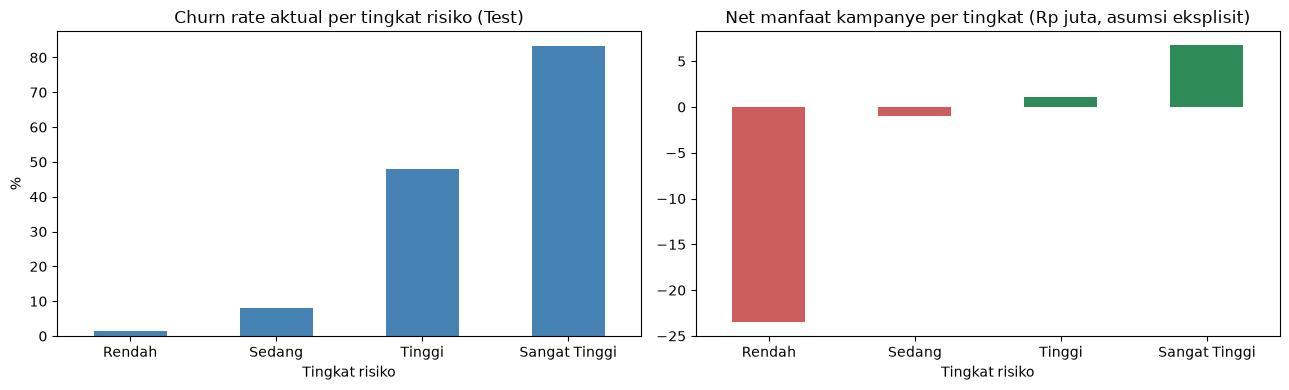

In [138]:
RISK_LABELS  = ['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']
RISK_CUTS    = [0.0, best_threshold / 2, best_threshold, min(0.99, max(0.70, best_threshold + 0.15)), 1.0 + 1e-9]
RISK_ACTIONS = {'Rendah': 'Tanpa intervensi; pantau rutin', 'Sedang': 'Pantau; engagement berbiaya rendah',
                'Tinggi': 'Kampanye retensi (voucher/promo)', 'Sangat Tinggi': 'Prioritas: kontak personal + penawaran khusus'}

def assign_risk_tier(score):
    return pd.cut(score, bins=RISK_CUTS, labels=RISK_LABELS, right=False, include_lowest=True)

seg = X_test.copy()
seg['Churn'], seg['score'] = y_test.values, y_prob_test
seg['Tingkat risiko'] = assign_risk_tier(seg['score'])

g = seg.groupby('Tingkat risiko', observed=False)
tier = pd.DataFrame({
    'Pelanggan'      : g.size(),
    '% pelanggan'    : g.size() / len(seg) * 100,
    'Churn aktual'   : g['Churn'].sum(),
    'Churn rate (%)' : g['Churn'].mean() * 100,
    '% dari semua churner': g['Churn'].sum() / seg['Churn'].sum() * 100,
    'Median Tenure'  : g['Tenure'].median(),
    'Complain (%)'   : g['Complain'].mean() * 100,
})
tier['Tindakan'] = [RISK_ACTIONS[t] for t in tier.index]

# simulasi biaya-manfaat per segmen (asumsi eksplisit)
tier['Biaya kampanye (Rp juta)']  = tier['Pelanggan'] * CAMPAIGN_COST / 1e6
tier['Nilai diselamatkan (Rp juta)'] = tier['Churn aktual'] * SUCCESS_RATE * LOST_VALUE / 1e6
tier['Net (Rp juta)']             = tier['Nilai diselamatkan (Rp juta)'] - tier['Biaya kampanye (Rp juta)']
tier['Success rate impas (%)']    = np.where(tier['Churn aktual'] > 0,
                                             tier['Pelanggan'] * CAMPAIGN_COST / (tier['Churn aktual'] * LOST_VALUE) * 100, np.nan)
tier['Layak dikampanye?']         = np.where(tier['Net (Rp juta)'] > 0, 'YA', 'TIDAK')
display(tier.round(2))

# ringkasan seluruh pelanggan yang dikampanye (Tinggi + Sangat Tinggi) + break-even keseluruhan
flag = seg['score'] >= best_threshold
n_t, tp_t = int(flag.sum()), int(seg.loc[flag, 'Churn'].sum())
fn_t = int(seg['Churn'].sum() - tp_t)
BREAKEVEN_SR = n_t * CAMPAIGN_COST / (tp_t * LOST_VALUE) if tp_t else np.nan
net_all = (tp_t * SUCCESS_RATE * LOST_VALUE - n_t * CAMPAIGN_COST) / 1e6
print(f"Pelanggan yang dikampanye (Tinggi+Sangat Tinggi): {n_t} dari {len(seg)} ({n_t/len(seg):.1%}) | churner tertangkap: {tp_t} dari {int(seg['Churn'].sum())}")
print(f"Net manfaat kampanye (asumsi success rate {SUCCESS_RATE:.0%}): Rp {net_all:,.1f} juta")
print(f"SUCCESS RATE IMPAS: kampanye ini baru menguntungkan jika success rate sebenarnya > {BREAKEVEN_SR:.1%} "
      f"(asumsi saat ini {SUCCESS_RATE:.0%}). Ukur nilai aktualnya lewat A/B test.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tier['Churn rate (%)'].plot.bar(ax=ax[0], color='steelblue'); ax[0].set_title('Churn rate aktual per tingkat risiko (Test)')
ax[0].set_ylabel('%'); ax[0].tick_params(axis='x', rotation=0); ax[0].grid(False)
tier['Net (Rp juta)'].plot.bar(ax=ax[1], color=np.where(tier['Net (Rp juta)'] > 0, 'seagreen', 'indianred'))
ax[1].set_title('Net manfaat kampanye per tingkat (Rp juta, asumsi eksplisit)'); ax[1].tick_params(axis='x', rotation=0); ax[1].grid(False)
plt.tight_layout(); plt.show()

**Cara membaca:** (1) *churn rate* aktual seharusnya **naik monoton** dari Rendah ke Sangat Tinggi; jika tidak, urutan skor tidak konsisten. (2) Kolom **`Success rate impas`** menunjukkan seberapa efektif kampanye harus berhasil agar segmen itu menguntungkan; jika nilainya jauh di atas perkiraan realistis, segmen itu sebaiknya tidak dikampanye. (3) Jumlah pelanggan per segmen pada *test set* kecil, sehingga angka per segmen bersifat indikatif. (4) Seluruh angka rupiah bergantung asumsi biaya.

<a id="bab-7-1-2"></a>
### 7.1.2 Penggabungan Risiko dengan Customer Value dan Retention Uplift

Prioritas intervensi yang ideal mempertimbangkan **tiga hal**, bukan skor risiko saja:

> *expected net benefit* = P(churn) × **uplift** × **customer value** − biaya kampanye

* **Customer value:** dataset **tidak memuat** margin/CLV per pelanggan, sehingga `LOST_VALUE` dipakai seragam (asumsi). Bila tersedia, ganti dengan nilai per pelanggan agar pelanggan berisiko tinggi **dan** bernilai tinggi diprioritaskan.
* **Retention uplift:** peluang intervensi benar-benar menyelamatkan pelanggan (`SUCCESS_RATE`, asumsi). Pelanggan berisiko tinggi belum tentu mudah diselamatkan; uplift hanya dapat diukur lewat A/B test (bagian 7.2).
* Karena nilai dan uplift diasumsikan seragam, urutan prioritas saat ini sama dengan urutan skor risiko.

In [139]:
# Kerangka prioritas (nilai & uplift seragam = asumsi; ganti dengan data per pelanggan bila tersedia)
seg['p_churn_kalibrasi']    = prob_test_cal
seg['customer_value']       = LOST_VALUE        # ganti dengan margin/CLV per pelanggan
seg['uplift']               = SUCCESS_RATE      # ganti dengan estimasi uplift dari A/B test
seg['expected_net_benefit'] = seg['p_churn_kalibrasi'] * seg['uplift'] * seg['customer_value'] - CAMPAIGN_COST

g = seg.groupby('Tingkat risiko', observed=False)
budget_tbl = pd.DataFrame({
    'Pelanggan'                          : g.size(),
    'Churn rate aktual (%)'              : g['Churn'].mean() * 100,
    'Rata-rata expected net benefit (Rp)': g['expected_net_benefit'].mean(),
})
# biaya impas per pelanggan = churn rate x uplift x nilai; di atas ini kampanye merugi pada segmen tersebut
budget_tbl['Biaya impas per pelanggan (Rp)'] = g['Churn'].mean() * SUCCESS_RATE * LOST_VALUE
budget_tbl['Batas anggaran segmen (Rp juta)'] = budget_tbl['Pelanggan'] * budget_tbl['Biaya impas per pelanggan (Rp)'] / 1e6
budget_tbl['Rencana biaya (Rp juta)']         = budget_tbl['Pelanggan'] * CAMPAIGN_COST / 1e6
budget_tbl['Rekomendasi anggaran'] = np.where(budget_tbl['Biaya impas per pelanggan (Rp)'] >= CAMPAIGN_COST,
                                              'Kampanye; anggaran ≤ batas segmen', 'Tidak dikampanyekan (biaya > impas)')
budget_tbl['Tindakan'] = [RISK_ACTIONS[t] for t in budget_tbl.index]
display(budget_tbl.round(2))

,Pelanggan,Churn rate aktual (%),Rata-rata expected net benefit (Rp),Biaya impas per pelanggan (Rp),Batas anggaran segmen (Rp juta),Rencana biaya (Rp juta),Rekomendasi anggaran,Tindakan
Tingkat risiko,,,,,,,,
Rendah,491,1.43,-43305.88,2138.49,1.05,24.55,Tidak dikampanyekan (biaya > impas),Tanpa intervensi; pantau rutin
Sedang,25,8.00,-8742.91,12000.00,0.30,1.25,Tidak dikampanyekan (biaya > impas),Pantau; engagement berbiaya rendah
Tinggi,48,47.92,13769.24,71875.00,3.45,2.40,Kampanye; anggaran ≤ batas segmen,Kampanye retensi (voucher/promo)
Sangat Tinggi,90,83.33,67571.00,125000.00,11.25,4.50,Kampanye; anggaran ≤ batas segmen,Prioritas: kontak personal + penawaran khusus


<a id="bab-7-1-3"></a>
### 7.1.3 Rekomendasi Tindakan dan Batas Anggaran per Segmen

| Tingkat risiko | Tindakan | Aturan anggaran |
| :--- | :--- | :--- |
| Rendah | Tanpa intervensi; pantau rutin | Tidak ada anggaran kampanye |
| Sedang | Pantau; *engagement* berbiaya rendah | Hanya jika biaya per pelanggan jauh di bawah titik impas segmen |
| Tinggi | Kampanye retensi (voucher/promo) | Total ≤ **batas anggaran segmen** pada tabel di atas |
| Sangat Tinggi | Prioritas: kontak personal + penawaran khusus | Didahulukan; total ≤ batas anggaran segmen |

**Catatan:** batas anggaran dihitung dari *churn rate* aktual pada *test set* yang kecil dan asumsi `SUCCESS_RATE`/`LOST_VALUE`, sehingga bersifat **indikatif**. Perbarui setelah A/B test mengukur *uplift* sebenarnya. Rekomendasi bisnis non-model (mis. *onboarding* pelanggan baru, penanganan komplain) ada di bagian 9.2.

<a id="bab-7-2"></a>
## 7.2 A/B Testing & Business Impact Validation Plan

Manfaat finansial pada notebook ini bergantung pada **asumsi** (`SUCCESS_RATE`, `LOST_VALUE`, `CAMPAIGN_COST`). Bagian ini adalah **rencana** eksperimen untuk mengganti asumsi dengan angka aktual. **Eksperimen belum dijalankan**, sehingga klaim dampak bisnis aktual belum dapat dibuat.

<a id="bab-7-2-1"></a>
### 7.2.1 Hipotesis dan Populasi

* **H₀:** *churn rate* kelompok *treatment* = kelompok *control*. **H₁:** kampanye menurunkan *churn rate* (*retention uplift* > 0).
* **Populasi:** pelanggan yang ditandai model (`churn_flag = 1`, yaitu tingkat risiko Tinggi + Sangat Tinggi).
* ***Eligibility*:** pelanggan aktif, data fitur lolos validasi `predict_churn()`, tidak sedang menerima kampanye retensi lain, tidak *opt-out* dari komunikasi pemasaran.

<a id="bab-7-2-2"></a>
### 7.2.2 Randomisasi

* Pengacakan di **level pelanggan** (*treatment* vs *control/holdout*); *control* tidak menerima kampanye. Disarankan *stratified* menurut tingkat risiko agar komposisi seimbang.
* Catat *seed*, tanggal penugasan, dan lakukan **pemeriksaan keseimbangan** karakteristik awal (`Tenure`, `Complain`, tingkat risiko) sebelum kampanye dimulai.

<a id="bab-7-2-3"></a>
### 7.2.3 Metrik

| Jenis | Metrik | Definisi |
| :--- | :--- | :--- |
| **Utama** | *Retention uplift* | *churn rate* control − *churn rate* treatment |
| **Utama** | *Net incremental profit* | pelanggan yang diselamatkan × margin kontribusi − biaya kampanye |
| Pengaman (*guardrail*) | Komplain, *opt-out*/berhenti berlangganan, margin per pesanan, biaya per pelanggan | Tidak boleh memburuk melebihi batas yang ditetapkan **sebelum** uji dimulai |

<a id="bab-7-2-4"></a>
### 7.2.4 Kriteria Penghentian

* **Berhenti lebih awal karena bahaya:** metrik pengaman melampaui batas yang ditetapkan sebelumnya.
* **Selesai:** ukuran sampel dan durasi yang direncanakan tercapai. Hindari *peeking*; analisis sela hanya jika dirancang sejak awal (*sequential design*).
* **Tidak dilanjutkan (*futility*):** efek yang dapat dideteksi dengan sampel tersedia terlalu kecil untuk menutup biaya kampanye.

<a id="bab-7-2-5"></a>
### 7.2.5 Rencana Analisis Hasil

* Analisis ***intention-to-treat***; uji dua proporsi (atau *chi-square*) pada *churn rate*, dengan *confidence interval* untuk *uplift*.
* *Net incremental profit* dihitung dari angka aktual, dengan *bootstrap* untuk ketidakpastian.
* Analisis per tingkat risiko bersifat **eksploratori** (jumlah sampel per segmen kecil).
* Hasil aktual **menggantikan** `SUCCESS_RATE`, lalu analisis biaya-manfaat dan *threshold* (bagian 6.3) dihitung ulang.

<a id="bab-7-2-6"></a>
### 7.2.6 Perkiraan Ukuran Sampel dan Durasi

Tabel berikut memperkirakan **jumlah pelanggan per kelompok** agar uji dapat mendeteksi efek kampanye (uji dua proporsi, $\alpha$ = 0,05, *power* 80%), dengan *churn rate* kelompok *control* = *precision* model pada *threshold* final.

In [140]:
WEEKLY_FLAGGED_VOLUME = None   # isi: jumlah pelanggan ditandai per minggu di produksi (belum tersedia di dataset ini)

def ab_sample_size(p_control, p_treat, alpha=0.05, power=0.80):
    """Jumlah sampel PER KELOMPOK untuk uji dua proporsi (aproksimasi normal, dua sisi)."""
    z_a, z_b = norm.ppf(1 - alpha / 2), norm.ppf(power)
    p_bar = (p_control + p_treat) / 2
    num = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p_control * (1 - p_control) + p_treat * (1 - p_treat))) ** 2
    return int(np.ceil(num / (p_control - p_treat) ** 2))

p_ctrl = float(ci_df.loc['Precision', 'Point'])      # churn rate pelanggan yang ditandai bila TIDAK dikampanye
rows = []
for sr in [0.10, 0.20, 0.30, 0.50]:
    p_trt = p_ctrl * (1 - sr)                         # churn rate bila kampanye menyelamatkan sebagian sr
    n_grp = ab_sample_size(p_ctrl, p_trt)
    rows.append({'Success rate sebenarnya': f'{sr:.0%}', 'Churn rate control': p_ctrl, 'Churn rate treatment': p_trt,
                 'Pelanggan per kelompok': n_grp, 'Total pelanggan': 2 * n_grp,
                 'Kali jumlah pelanggan ditandai di test set': round(2 * n_grp / max(int(flag.sum()), 1), 1)})
ab_plan = pd.DataFrame(rows).set_index('Success rate sebenarnya')
display(ab_plan.round(3))
if WEEKLY_FLAGGED_VOLUME:
    ab_plan['Perkiraan durasi (minggu)'] = (ab_plan['Total pelanggan'] / WEEKLY_FLAGGED_VOLUME).round(1)
    display(ab_plan[['Total pelanggan', 'Perkiraan durasi (minggu)']])
else:
    print("Durasi uji = Total pelanggan ÷ jumlah pelanggan ditandai per minggu (isi WEEKLY_FLAGGED_VOLUME untuk menghitung).")
print(f"Dengan churn rate control ≈ {p_ctrl:.1%}: makin kecil efek kampanye yang ingin dideteksi, makin besar sampel yang dibutuhkan. "
      f"Jika volume pelanggan ditandai per periode kecil, jalankan uji lebih lama atau terima efek minimum yang lebih besar.")

,Churn rate control,Churn rate treatment,Pelanggan per kelompok,Total pelanggan,Kali jumlah pelanggan ditandai di test set
Success rate sebenarnya,,,,,
10%,0.71,0.639,683,1366,9.9
20%,0.71,0.568,179,358,2.6
30%,0.71,0.497,82,164,1.2
50%,0.71,0.355,30,60,0.4


Durasi uji = Total pelanggan ÷ jumlah pelanggan ditandai per minggu (isi WEEKLY_FLAGGED_VOLUME untuk menghitung).
Dengan churn rate control ≈ 71.0%: makin kecil efek kampanye yang ingin dideteksi, makin besar sampel yang dibutuhkan. Jika volume pelanggan ditandai per periode kecil, jalankan uji lebih lama atau terima efek minimum yang lebih besar.


<a id="bab-8"></a>
# 8. DEPLOYMENT & OPERATIONS

<a id="bab-8-1"></a>
## 8.1 Model Deployment

<a id="bab-8-1-1"></a>
### 8.1.1 Menyimpan Model dan Preprocessing Pipeline

Model disimpan sebagai **satu bundle** (`joblib`) yang memuat: *pipeline* lengkap (preprocessing → SMOTE → model), ***threshold* final**, kalibrator probabilitas, daftar kolom yang diharapkan, rentang nilai/kategori data latih, dan metadata (versi *library*, tanggal, parameter). Dengan begitu data baru diproses **persis sama** seperti saat pelatihan.

Pilihan `REFIT_ON_FULL_DATA`: secara bawaan model yang disimpan adalah model yang dilatih pada data *train* (yang sudah dievaluasi). Setelah evaluasi dinyatakan memuaskan, boleh diubah menjadi `True` agar model akhir dilatih ulang pada seluruh data bersih dengan parameter dan *threshold* yang sama.

In [141]:
REFIT_ON_FULL_DATA = False     # True -> latih ulang pada seluruh data bersih (X, y) setelah evaluasi final
REGISTRY_PATH = os.path.join(MODEL_DIR, 'registry.json')
os.makedirs(MODEL_DIR, exist_ok=True)

if REFIT_ON_FULL_DATA:
    deploy_pipeline = clone(final_pipeline).fit(X, y)
    X_fit = X
else:
    deploy_pipeline = final_pipeline
    X_fit = X_train

def _ver(pkg):
    try:
        return importlib_metadata.version(pkg)
    except Exception:
        return 'unknown'

# ---------- Distribusi referensi data latih (dipakai untuk monitoring data drift) ----------
def build_reference(X_ref, max_discrete=10, n_bins=10):
    ref = {'numeric': {}, 'categorical': {}}
    for c in X_ref.columns:
        s = X_ref[c]
        if pd.api.types.is_numeric_dtype(s) and s.nunique() > max_discrete:
            edges = np.unique(np.quantile(s.dropna(), np.linspace(0, 1, n_bins + 1)))[1:-1]
            idx = np.digitize(s.dropna().values, edges)
            props = np.append(np.bincount(idx, minlength=len(edges) + 1) / len(s), s.isna().mean())
            ref['numeric'][c] = {'edges': [float(e) for e in edges], 'props': [float(p) for p in props]}
        else:
            ref['categorical'][c] = {str(k): float(v) for k, v in s.astype(str).value_counts(normalize=True).items()}
    return ref

# gerbang fitur: kolom yang dipakai model harus terdaftar
unverified_features = check_feature_availability(list(X_train.columns))

bundle = {
    'pipeline'        : deploy_pipeline,
    'threshold'       : float(best_threshold),          # threshold FINAL (berbasis biaya), bukan 0.5
    'calibrator'      : platt,                           # untuk melaporkan probabilitas terkalibrasi
    'risk_cuts'       : [float(c) for c in RISK_CUTS],   # batas tingkat risiko (lihat bagian Segmentasi Risiko)
    'risk_labels'     : RISK_LABELS,
    'risk_actions'    : RISK_ACTIONS,
    'feature_columns' : list(X_train.columns),
    'training_ranges' : X_fit.select_dtypes(include='number').agg(['min', 'max']).to_dict(),
    'category_values' : {c: sorted(X_fit[c].dropna().unique().tolist()) for c in nominal_cols},
    'reference'       : build_reference(X_fit),          # untuk PSI / drift
    'metadata': {
        'model_name'        : best_name,
        'model_candidate'   : FINAL_MODEL_CHOICE,
        'model_params'      : final_model_params,
        'cv_f1'             : final_cv_f1,
        'cv_train_gap_f1'   : final_gap_f1,
        'created_at'        : datetime.datetime.now().isoformat(timespec='seconds'),
        'refit_on_full_data': REFIT_ON_FULL_DATA,
        'library_versions'  : {p: _ver(p) for p in ['scikit-learn', 'imbalanced-learn', 'xgboost', 'lightgbm', 'pandas', 'numpy']},
        'test_metrics_final_threshold': ci_df.loc[['Recall', 'Precision', 'F1', 'ROC-AUC', 'PR-AUC'], ['Point', 'CI low', 'CI high']].round(4).to_dict(),
        'success_criteria'  : SUCCESS_CRITERIA,
        'cost_assumptions'  : {'LOST_VALUE': LOST_VALUE, 'CAMPAIGN_COST': CAMPAIGN_COST, 'SUCCESS_RATE': SUCCESS_RATE},
        'unverified_features': unverified_features,
        'notes'             : 'Skor mentah = peringkat risiko; gunakan churn_flag untuk keputusan. Data baru harus memuat kolom yang sama persis dengan data latih.',
    },
}
print(f"Bundle siap | kandidat: {FINAL_MODEL_CHOICE} | threshold = {bundle['threshold']} | fitur belum terverifikasi: {len(unverified_features)}")

Fitur terdaftar: 10 | belum terverifikasi: 10 | di antaranya risiko TINGGI: ['Complain', 'DaySinceLastOrder', 'CashbackAmount']
Bundle siap | kandidat: tuned | threshold = 0.3 | fitur belum terverifikasi: 10


<a id="bab-8-1-2"></a>
### 8.1.2 Versioning Model (Registri)

In [142]:
# ---------- Registri versi model: pencatatan versi, pemuatan, dan ROLLBACK ----------
def load_registry():
    if os.path.exists(REGISTRY_PATH):
        with open(REGISTRY_PATH, encoding='utf-8') as f:
            return json.load(f)
    return {'current': None, 'versions': []}

def _save_registry(reg):
    with open(REGISTRY_PATH, 'w', encoding='utf-8') as f:
        json.dump(reg, f, indent=2, ensure_ascii=False)

def register_model(bundle, notes=''):
    """Simpan bundle sebagai versi baru dan jadikan 'current'. Versi lama TIDAK dihapus (agar bisa rollback)."""
    reg = load_registry()
    stamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    version = f"v{len(reg['versions']) + 1:03d}_{stamp}"
    path = os.path.join(MODEL_DIR, f"churn_model_{version}.joblib")
    joblib.dump(bundle, path)
    for v in reg['versions']:
        if v['status'] == 'current':
            v['status'] = 'previous'
    reg['versions'].append({
        'version': version, 'path': path, 'status': 'current', 'notes': notes,
        'created_at': bundle['metadata']['created_at'], 'threshold': bundle['threshold'],
        'candidate': bundle['metadata']['model_candidate'],
        'test_metrics': {k: round(float(v), 4) for k, v in ci_df['Point'].items()},
    })
    reg['current'] = version
    _save_registry(reg)
    return version

def show_registry():
    reg = load_registry()
    return pd.DataFrame(reg['versions'])[['version', 'status', 'created_at', 'candidate', 'threshold', 'notes']] if reg['versions'] else pd.DataFrame()

def load_model(version=None):
    """Muat bundle versi tertentu; default = versi 'current'."""
    reg = load_registry()
    version = version or reg['current']
    if version is None:
        raise FileNotFoundError("Belum ada model terdaftar.")
    entry = next(v for v in reg['versions'] if v['version'] == version)
    return joblib.load(entry['path'])

def rollback_model(to_version=None):
    """Kembalikan 'current' ke versi sebelumnya (atau versi tertentu). File model tidak dihapus."""
    reg = load_registry()
    versions = [v['version'] for v in reg['versions']]
    if to_version is None:
        idx = versions.index(reg['current'])
        if idx == 0:
            raise RuntimeError("Tidak ada versi sebelumnya untuk rollback.")
        to_version = versions[idx - 1]
    if to_version not in versions:
        raise ValueError(f"Versi tidak ditemukan: {to_version}")
    for v in reg['versions']:
        v['status'] = 'current' if v['version'] == to_version else ('previous' if v['status'] == 'current' else v['status'])
    reg['current'] = to_version
    _save_registry(reg)
    return to_version

MODEL_VERSION = register_model(bundle, notes='Hasil notebook (lihat metadata)')
MODEL_PATH = next(v['path'] for v in load_registry()['versions'] if v['version'] == MODEL_VERSION)
print(f"Model terdaftar: {MODEL_VERSION} -> {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.2f} MB)")
display(show_registry())

Model terdaftar: v004_20261113_195443_848835 -> model_artifacts\churn_model_v004_20261113_195443_848835.joblib (0.78 MB)


,version,status,created_at,candidate,threshold,notes
0,v001_20261113_172403_940113,previous,2026-11-13T17:24:03,tuned,0.3,Hasil notebook (lihat metadata)
1,v002_20261113_191627_269665,previous,2026-11-13T19:16:27,tuned,0.3,Hasil notebook (lihat metadata)
2,v003_20261113_193342_439648,previous,2026-11-13T19:33:42,tuned,0.3,Hasil notebook (lihat metadata)
3,v004_20261113_195443_848835,current,2026-11-13T19:54:43,tuned,0.3,Hasil notebook (lihat metadata)


<a id="bab-8-1-3"></a>
### 8.1.3 Prediction Function / Batch Scoring dan Validasi Input-Output

In [143]:
def predict_churn(new_data, bundle=None):
    """Prediksi churn untuk data baru.

    new_data : DataFrame (atau dict/list of dict) dengan kolom yang SAMA PERSIS dengan data latih
               (tanpa kolom 'Churn'; jika ada, akan diabaikan).
    Mengembalikan DataFrame: churn_score (skor mentah), churn_probability_calibrated, churn_flag (1 = intervensi), risk_tier.
    Jika bundle tidak diberikan, memuat versi 'current' dari registri (load_model()).
    """
    if bundle is None:
        bundle = load_model()

    df_new = pd.DataFrame(new_data).copy()
    df_new = df_new.drop(columns=['Churn'], errors='ignore')

    expected = bundle['feature_columns']
    missing = [c for c in expected if c not in df_new.columns]
    extra   = [c for c in df_new.columns if c not in expected]
    if missing or extra:
        raise ValueError(f"Kolom data baru harus sama persis dengan data latih. Hilang: {missing} | Kelebihan: {extra}")
    df_new = df_new[expected]                                   # urutan kolom sama dengan data latih

    # pembersihan yang sama seperti saat pelatihan
    df_new['PreferedOrderCat'] = df_new['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})

    # peringatan (tidak menghentikan prediksi)
    for col, rng_ in bundle['training_ranges'].items():
        out = df_new[col].notna() & ((df_new[col] < rng_['min']) | (df_new[col] > rng_['max']))
        if out.any():
            print(f"PERINGATAN: {int(out.sum())} baris '{col}' di luar rentang data latih [{rng_['min']}, {rng_['max']}] -> prediksi kurang andal.")
    for col, vals in bundle['category_values'].items():
        unseen = df_new[col].notna() & ~df_new[col].isin(vals)
        if unseen.any():
            print(f"PERINGATAN: {int(unseen.sum())} baris '{col}' berisi kategori baru {sorted(df_new.loc[unseen, col].unique())} -> diabaikan encoder.")

    score = bundle['pipeline'].predict_proba(df_new)[:, 1]
    p_clip = np.clip(score, 1e-6, 1 - 1e-6)                     # logit lokal agar fungsi ini mandiri
    cal = bundle['calibrator'].predict_proba(np.log(p_clip / (1 - p_clip)).reshape(-1, 1))[:, 1]
    return pd.DataFrame({
        'churn_score'                 : score,
        'churn_probability_calibrated': cal,
        'churn_flag'                  : (score >= bundle['threshold']).astype(int),
        'risk_tier'                   : pd.cut(score, bins=bundle['risk_cuts'], labels=bundle['risk_labels'],
                                               right=False, include_lowest=True).astype(str),
    }, index=df_new.index)

# --- Verifikasi: muat ulang dari disk dan pastikan hasil sama dengan model di memori ---
loaded_bundle = load_model()          # versi 'current' dari registri
check = predict_churn(X_test, bundle=loaded_bundle)
assert np.allclose(check['churn_score'].values, deploy_pipeline.predict_proba(X_test)[:, 1]), "Skor model hasil muat ulang berbeda!"
assert (check['churn_flag'].values == (check['churn_score'].values >= best_threshold).astype(int)).all(), "Flag tidak konsisten dengan threshold!"
print(f"Verifikasi OK: bundle hasil muat ulang menghasilkan skor identik pada {len(check)} baris test.")
print(f"Pelanggan test yang ditandai untuk intervensi: {int(check['churn_flag'].sum())} dari {len(check)}")
display(predict_churn(X_test.head(5), bundle=loaded_bundle).round(3))

PERINGATAN: 1 baris 'NumberOfAddress' di luar rentang data latih [1, 21] -> prediksi kurang andal.
Verifikasi OK: bundle hasil muat ulang menghasilkan skor identik pada 654 baris test.
Pelanggan test yang ditandai untuk intervensi: 138 dari 654


,churn_score,churn_probability_calibrated,churn_flag,risk_tier
989,0.001,0.010,0,Rendah
3071,0.000,0.002,0,Rendah
607,0.011,0.049,0,Rendah
226,0.034,0.093,0,Rendah
1981,0.497,0.434,1,Tinggi


In [144]:
# --- Validasi output: skor valid, tanpa NaN, kolom lengkap ---
assert check['churn_score'].between(0, 1).all(), "Skor di luar rentang [0, 1]"
assert not check.isna().any().any(), "Output mengandung NaN"
assert set(check.columns) == {'churn_score', 'churn_probability_calibrated', 'churn_flag', 'risk_tier'}, "Kolom output tidak sesuai"

# --- Validasi input: data dengan kolom kurang harus ditolak dengan pesan yang jelas ---
try:
    predict_churn(X_test.drop(columns=['Tenure']).head(3), bundle=loaded_bundle)
    raise AssertionError("Input tidak valid seharusnya ditolak")
except ValueError as e:
    print("Validasi input OK ->", str(e)[:100])
print("Validasi output OK.")

Validasi input OK -> Kolom data baru harus sama persis dengan data latih. Hilang: ['Tenure'] | Kelebihan: []
Validasi output OK.


<a id="bab-8-1-4"></a>
### 8.1.4 Dokumentasi Penggunaan

**Cara memakai di luar notebook:**

```python
bundle = load_model()                               # versi 'current' dari model_artifacts/registry.json
hasil  = predict_churn(data_baru, bundle=bundle)    # churn_score, probabilitas terkalibrasi, churn_flag, risk_tier
# jika versi baru bermasalah: rollback_model()      # kembali ke versi sebelumnya tanpa melatih ulang
```

Catatan: (1) data baru wajib memuat **kolom yang sama persis** dengan data latih (nama dan jenis kolom); (2) muat bundle dengan versi *scikit-learn*/*xgboost*/*imbalanced-learn* yang sama dengan yang tercatat di `metadata['library_versions']`; (3) salin juga fungsi registri (`load_model`, `rollback_model`) dan `predict_churn` ke skrip layanan; (4) setiap kali sel penyimpanan dijalankan, **versi baru ditambahkan** ke registri tanpa menghapus versi lama.

<a id="bab-8-1-5"></a>
### 8.1.5 API (Opsional)

API **hanya dibutuhkan** bila skor harus tersedia *real-time* (mis. dipanggil dari aplikasi saat pelanggan beraktivitas). Untuk kampanye retensi periodik, ***batch scoring*** dengan `predict_churn()` sudah cukup dan lebih sederhana dioperasikan. Kerangka berikut hanya sketsa (tidak dijalankan di notebook):

```python
from fastapi import FastAPI
import pandas as pd

app = FastAPI()
bundle = load_model()            # salin load_model() dan predict_churn() dari notebook ini

@app.post("/predict")
def predict(records: list[dict]):
    return predict_churn(pd.DataFrame(records), bundle=bundle).to_dict(orient="records")
```

Sebelum dipakai di produksi tambahkan autentikasi, validasi skema (mis. *pydantic*), pencatatan permintaan, dan pengujian beban.

<a id="bab-8-2"></a>
## 8.2 Monitoring, Retraining & Rollback

<a id="bab-8-2-1"></a>
### 8.2.1 Cakupan Pemantauan

Model yang sudah dipakai harus dipantau karena perilaku pelanggan berubah. Selain kualitas data masuk dan indikator bisnis (KPI), tiga hal berikut dipantau: (1) ***data drift*** — apakah distribusi fitur data baru menyimpang dari data latih (memakai **PSI** terhadap `bundle['reference']`); (2) **performa** — apakah *Recall* dan *Precision* (setelah label churn sebenarnya diketahui) masih memenuhi *Success Criteria*; (3) **versi model** — setiap model tercatat di registri dan dapat di-*rollback*.

| PSI | Status | Tindakan |
| :--- | :--- | :--- |
| < 0,10 | Stabil | Tidak ada |
| 0,10 – 0,25 | Waspada | Selidiki penyebab; tingkatkan frekuensi pemantauan |
| > 0,25 | Drift | Evaluasi ulang performa; pertimbangkan *retraining* |

<a id="bab-8-2-2"></a>
### 8.2.2 Data Quality Monitoring

In [145]:
def data_quality_check(X_new, bundle, max_missing_increase=0.05, max_out_of_range=0.05):
    """Periksa kualitas data masuk terhadap profil data latih (skema, missing, rentang, kategori baru, duplikat)."""
    rows = []
    expected = bundle['feature_columns']
    miss_cols = [c for c in expected if c not in X_new.columns]
    extra_cols = [c for c in X_new.columns if c not in expected and c != 'Churn']
    rows.append({'Cek': 'Skema kolom', 'Detail': f'hilang={miss_cols} | kelebihan={extra_cols}',
                 'Status': 'ALERT' if (miss_cols or extra_cols) else 'OK'})
    if miss_cols:
        return pd.DataFrame(rows).set_index('Cek')

    for c, r in bundle['reference']['numeric'].items():           # proporsi missing saat pelatihan = elemen terakhir props
        cur, ref = float(X_new[c].isna().mean()), float(r['props'][-1])
        rows.append({'Cek': f'Missing {c}', 'Detail': f'sekarang {cur:.1%} vs latih {ref:.1%}',
                     'Status': 'ALERT' if cur - ref > max_missing_increase else 'OK'})
    for c, rng_ in bundle['training_ranges'].items():
        share = float((X_new[c].notna() & ((X_new[c] < rng_['min']) | (X_new[c] > rng_['max']))).mean())
        if share > 0:
            rows.append({'Cek': f'Di luar rentang {c}', 'Detail': f'{share:.1%} baris di luar [{rng_["min"]}, {rng_["max"]}]',
                         'Status': 'ALERT' if share > max_out_of_range else 'PERHATIAN'})
    for c, vals in bundle['category_values'].items():
        share = float((X_new[c].notna() & ~X_new[c].isin(vals)).mean())
        if share > 0:
            rows.append({'Cek': f'Kategori baru {c}', 'Detail': f'{share:.1%} baris berisi kategori tak dikenal', 'Status': 'ALERT'})
    dup = float(X_new.duplicated().mean())
    rows.append({'Cek': 'Duplikasi baris', 'Detail': f'{dup:.1%} baris identik', 'Status': 'PERHATIAN' if dup > 0.05 else 'OK'})
    return pd.DataFrame(rows).set_index('Cek')

print("1) Data test (seharusnya tidak ada ALERT):")
display(data_quality_check(X_test, loaded_bundle).query("Status != 'OK'"))

# SIMULASI masalah kualitas data: 15% Tenure kosong + kategori baru pada MaritalStatus
X_dq = X_test.copy()
X_dq.loc[X_dq.sample(frac=0.15, random_state=RANDOM_STATE).index, 'Tenure'] = np.nan
X_dq.loc[X_dq.index[:20], 'MaritalStatus'] = 'Unknown'
print("\n2) Data SIMULASI bermasalah (harus memunculkan ALERT):")
display(data_quality_check(X_dq, loaded_bundle).query("Status != 'OK'"))

1) Data test (seharusnya tidak ada ALERT):


,Detail,Status
Cek,,
Di luar rentang NumberOfAddress,"0.2% baris di luar [1, 21]",PERHATIAN



2) Data SIMULASI bermasalah (harus memunculkan ALERT):


,Detail,Status
Cek,,
Missing Tenure,sekarang 20.0% vs latih 4.7%,ALERT
Di luar rentang NumberOfAddress,"0.2% baris di luar [1, 21]",PERHATIAN
Kategori baru MaritalStatus,3.1% baris berisi kategori tak dikenal,ALERT


<a id="bab-8-2-3"></a>
### 8.2.3 Data Drift / PSI dan Model Performance Monitoring

In [146]:
def _psi(expected, actual, eps=1e-4):
    e, a = np.clip(np.asarray(expected, float), eps, None), np.clip(np.asarray(actual, float), eps, None)
    return float(np.sum((a - e) * np.log(a / e)))

def _psi_status(v):
    return 'Stabil' if v < 0.10 else ('Waspada' if v < 0.25 else 'DRIFT')

def drift_report(X_new, reference):
    """PSI per fitur antara data baru dan distribusi referensi data latih."""
    rows = []
    for c, r in reference['numeric'].items():
        s = X_new[c]
        idx = np.digitize(s.dropna().values, r['edges'])
        act = np.append(np.bincount(idx, minlength=len(r['edges']) + 1) / max(len(s), 1), s.isna().mean())
        v = _psi(r['props'], act); rows.append({'Fitur': c, 'Jenis': 'numerik', 'PSI': v, 'Status': _psi_status(v)})
    for c, r in reference['categorical'].items():
        cur = X_new[c].astype(str).value_counts(normalize=True).to_dict()
        keys = sorted(set(r) | set(cur))
        v = _psi([r.get(k, 0) for k in keys], [cur.get(k, 0) for k in keys]); rows.append({'Fitur': c, 'Jenis': 'kategorikal', 'PSI': v, 'Status': _psi_status(v)})
    return pd.DataFrame(rows).set_index('Fitur').sort_values('PSI', ascending=False)

def performance_check(y_true, flags, success_criteria=SUCCESS_CRITERIA):
    """Bandingkan performa data baru (setelah label diketahui) dengan Success Criteria -> sinyal retraining."""
    rec, prec = recall_score(y_true, flags, zero_division=0), precision_score(y_true, flags, zero_division=0)
    out = pd.DataFrame({'Hasil': [rec, prec], 'Minimum': [success_criteria['min_recall'], success_criteria['min_precision']]},
                       index=['Recall', 'Precision'])
    out['Status'] = np.where(out['Hasil'] >= out['Minimum'], 'OK', 'ALERT -> evaluasi / retraining')
    return out

ref_bundle = load_model()
print("1) Drift: data test vs distribusi latih (seharusnya stabil karena berasal dari sumber yang sama)")
display(drift_report(X_test, ref_bundle['reference']).round(4).head(6))

# --- SIMULASI untuk menunjukkan bahwa alarm berfungsi: pelanggan menjadi jauh lebih baru dan lebih sering komplain ---
X_sim = X_test.copy()
X_sim['Tenure'] = (X_sim['Tenure'] * 0.4).round()
X_sim['Complain'] = (np.random.default_rng(RANDOM_STATE).random(len(X_sim)) < 0.6).astype(int)
print("\n2) Drift pada data SIMULASI (Tenure dikecilkan & komplain dinaikkan) -> harus memunculkan peringatan")
display(drift_report(X_sim, ref_bundle['reference']).round(4).head(6))

print("\n3) Pemeriksaan performa (data test sebagai contoh; pada produksi gunakan data baru yang labelnya sudah diketahui)")
display(performance_check(y_test, predict_churn(X_test, bundle=ref_bundle)['churn_flag'].values).round(3))

1) Drift: data test vs distribusi latih (seharusnya stabil karena berasal dari sumber yang sama)


,Jenis,PSI,Status
Fitur,,,
Tenure,numerik,0.0257,Stabil
WarehouseToHome,numerik,0.0215,Stabil
DaySinceLastOrder,numerik,0.0215,Stabil
CashbackAmount,numerik,0.0198,Stabil
PreferedOrderCat,kategorikal,0.0156,Stabil
NumberOfDeviceRegistered,kategorikal,0.0154,Stabil



2) Drift pada data SIMULASI (Tenure dikecilkan & komplain dinaikkan) -> harus memunculkan peringatan


,Jenis,PSI,Status
Fitur,,,
Tenure,numerik,2.4776,DRIFT
Complain,kategorikal,0.4126,DRIFT
WarehouseToHome,numerik,0.0215,Stabil
DaySinceLastOrder,numerik,0.0215,Stabil
CashbackAmount,numerik,0.0198,Stabil
PreferedOrderCat,kategorikal,0.0156,Stabil



3) Pemeriksaan performa (data test sebagai contoh; pada produksi gunakan data baru yang labelnya sudah diketahui)
PERINGATAN: 1 baris 'NumberOfAddress' di luar rentang data latih [1, 21] -> prediksi kurang andal.


,Hasil,Minimum,Status
Recall,0.916,0.7,OK
Precision,0.710,0.5,OK


<a id="bab-8-2-4"></a>
### 8.2.4 Business KPI Monitoring

In [147]:
def kpi_snapshot(scored):
    """KPI proses yang selalu tersedia: volume scoring, proporsi ditandai, dan distribusi tingkat risiko."""
    out = {'Pelanggan di-scoring': len(scored),
           'Proporsi ditandai (%)': round(float(scored['churn_flag'].mean()) * 100, 2)}
    for tier_name, share in scored['risk_tier'].value_counts(normalize=True).items():
        out[f'Tingkat {tier_name} (%)'] = round(float(share) * 100, 2)
    return pd.Series(out, name='Nilai')

def kpi_outcome(n_treat, churn_treat, n_ctrl, churn_ctrl, lost_value=LOST_VALUE, campaign_cost=CAMPAIGN_COST):
    """KPI hasil (butuh data A/B atau holdout): retention uplift dan net incremental profit AKTUAL."""
    rate_t, rate_c = churn_treat / n_treat, churn_ctrl / n_ctrl
    uplift = rate_c - rate_t
    saved = uplift * n_treat
    return {'Churn rate treatment': rate_t, 'Churn rate control': rate_c, 'Retention uplift': uplift,
            'Pelanggan diselamatkan': saved,
            'Net incremental profit (Rp)': saved * lost_value - n_treat * campaign_cost}

display(kpi_snapshot(predict_churn(X_test, bundle=loaded_bundle)).to_frame())
print("kpi_outcome() baru dapat diisi setelah A/B test (bagian 7.2) menghasilkan data treatment vs control.")

PERINGATAN: 1 baris 'NumberOfAddress' di luar rentang data latih [1, 21] -> prediksi kurang andal.


,Nilai
Pelanggan di-scoring,654.00
Proporsi ditandai (%),21.10
Tingkat Rendah (%),75.08
Tingkat Sangat Tinggi (%),13.76
Tingkat Tinggi (%),7.34
Tingkat Sedang (%),3.82


kpi_outcome() baru dapat diisi setelah A/B test (bagian 7.2) menghasilkan data treatment vs control.


<a id="bab-8-2-5"></a>
### 8.2.5 Jadwal Pemantauan dan Pemicu Retraining

| Aktivitas | Frekuensi | Pemicu tindakan |
| :--- | :--- | :--- |
| Kualitas data masuk (skema, *missing*, rentang, kategori baru) | Tiap *batch scoring* | Status ALERT pada `data_quality_check()` |
| *Data drift* (PSI) per fitur | Mingguan / tiap *batch scoring* | PSI > 0,25 pada fitur penting (mis. `Tenure`, `Complain`) |
| Performa (Recall, Precision terhadap `SUCCESS_CRITERIA`) | Bulanan, setelah label churn tersedia | Di bawah minimum selama 2 periode berturut-turut |
| KPI bisnis (proporsi ditandai, distribusi `risk_tier`, *retention uplift*, *net incremental profit*) | Tiap *batch*; KPI hasil tiap periode kampanye | Perubahan mendadak (> ±30% dari biasanya) atau *uplift* tidak lagi positif |
| *Retraining* terjadwal | Mis. tiap kuartal, atau saat ada data baru yang cukup | Pemicu di atas, perubahan produk / promo besar |

<a id="bab-8-2-6"></a>
### 8.2.6 Kriteria Rollback dan Prosedur Pemulihan

**Kriteria *rollback*** (cukup salah satu):

* alarm *drift* (PSI > 0,25) pada fitur penting **dan** performa turun di bawah *success criteria*;
* performa di bawah minimum pada 2 periode berturut-turut setelah model baru dipakai;
* galat/kegagalan validasi input-output pada `predict_churn()`;
* metrik pengaman bisnis (komplain, *opt-out*) memburuk melebihi batas yang disepakati.

**Prosedur pemulihan:**

1. Model baru selalu didaftarkan lewat `register_model()` — versi lama tetap tersimpan.
2. Jalankan model baru dalam mode bayangan (*shadow*) atau pada sebagian kecil pelanggan lebih dulu; bandingkan `churn_flag` dengan model lama.
3. Jika kriteria *rollback* terpenuhi: jalankan `rollback_model()` (kembali ke versi sebelumnya) atau `rollback_model('<versi>')`; layanan otomatis memakai versi `current` yang baru.
4. Catat penyebab pada kolom `notes` versi tersebut, perbaiki, lalu latih ulang.

<a id="bab-9"></a>
# 9. PENUTUP

<a id="bab-9-1"></a>
## 9.1 Limitations & Future Improvements

<a id="bab-9-1-1"></a>
### 9.1.1 Rentang Nilai dan Kategori Data Latih

Model hanya valid untuk data yang berada dalam rentang nilai dan kategori yang pernah dilihat saat pelatihan. Berikut rentang dan kategori pada data yang dipakai:

In [148]:
X.select_dtypes(include='number').describe().T[['min', 'max']]

,min,max
Tenure,0.0,61.00
WarehouseToHome,5.0,127.00
NumberOfDeviceRegistered,1.0,6.00
SatisfactionScore,1.0,5.00
NumberOfAddress,1.0,22.00
Complain,0.0,1.00
DaySinceLastOrder,0.0,46.00
CashbackAmount,0.0,324.99


In [149]:
cat_constraints = pd.DataFrame({
    'Unique_Count' : X.select_dtypes(exclude='number').nunique(),
    'Unique_Values': [X[col].unique().tolist() for col in X.select_dtypes(exclude='number').columns]
})
cat_constraints

,Unique_Count,Unique_Values
PreferedOrderCat,5,"[Laptop & Accessory, Mobile Phone, Fashion, Ot..."
MaritalStatus,3,"[Single, Married, Divorced]"


<a id="bab-9-1-2"></a>
### 9.1.2 Keterbatasan

<a id="bab-9-1-2-1"></a>
#### 9.1.2.1 Dataset dan representativitas

* **Rentang nilai:** prediksi untuk pelanggan di luar rentang di atas (mis. *tenure* > 61 bulan, `CashbackAmount` > ±325, kategori belanja baru di luar daftar) kurang dapat diandalkan; kategori yang belum pernah dilihat akan diabaikan oleh *encoder* (`handle_unknown='ignore'`).
* **Tanpa ID pelanggan:** tidak bisa dipastikan apakah baris kembar yang dihapus adalah data ganda atau pelanggan berbeda; definisi churn (kapan pelanggan dianggap berhenti) juga tidak tercantum di data.
* **Ukuran data & kelas minoritas:** setelah pembersihan hanya 3.270 baris dengan 534 pelanggan churn (*test set*: 654 baris, 107 churn; angka dari eksekusi sebelumnya), sehingga estimasi performa memiliki ketidakpastian yang cukup besar. Ketidakpastian ini dikuantifikasi dengan *confidence interval* bootstrap; skor *test set* sebaiknya dibaca sebagai perkiraan, bukan angka pasti.
* **Fitur tambahan belum ada:** RFM, frekuensi/waktu penyelesaian komplain, dan tren pembelian tidak tersedia karena data sumber tidak memuatnya; lihat tabel kandidat pada bagian 5.1.
* **Penggunaan fitur sensitif:** `MaritalStatus` adalah atribut demografis; pertimbangkan aspek etika/kepatuhan sebelum memakainya untuk menentukan perlakuan berbeda antar pelanggan.

<a id="bab-9-1-2-2"></a>
#### 9.1.2.2 Validasi temporal

* **Data tanpa tanggal:** model divalidasi dengan *stratified split* dan *Stratified K-Fold*, **bukan** validasi berbasis waktu; tidak ada klaim bahwa model terbukti stabil lintas periode. Model tidak melihat tren perilaku.
* **Validitas waktu fitur belum dikonfirmasi:** definisi churn dan waktu pencatatan fitur (`Complain`, `CashbackAmount`, `DaySinceLastOrder`, dll.) tidak ada di data; risiko *temporal leakage* hanya dinilai lewat *ablation*, bukan dibuktikan.
* **EDA hanya pada data *train*:** angka pada ringkasan markdown EDA berasal dari eksekusi sebelumnya pada seluruh data dan perlu dicocokkan ulang setelah notebook dijalankan.

<a id="bab-9-1-2-3"></a>
#### 9.1.2.3 Asumsi cost-benefit

* **Asumsi biaya** (`LOST_VALUE`, `CAMPAIGN_COST`, `SUCCESS_RATE`) bersifat ilustratif dan harus diganti dengan angka riil; seluruh angka rupiah adalah simulasi, bukan hasil aktual.
* **Segmentasi risiko dan manfaat per segmen** dihitung pada *test set* yang kecil sehingga bersifat indikatif; angka rupiah bergantung asumsi sampai ada hasil A/B test.
* **Nilai pelanggan dan *uplift* diasumsikan seragam** karena data tidak memuat keduanya.

<a id="bab-9-1-2-4"></a>
#### 9.1.2.4 Kausalitas dan generalisasi

* **Korelasi ≠ kausalitas:** fitur penting dan SHAP menunjukkan asosiasi, bukan penyebab. Hasil yang kontra-intuitif (mis. `SatisfactionScore`) perlu divalidasi sebelum dijadikan dasar kebijakan.
* **Overfitting:** model berbasis pohon cenderung menghafal data *train* (F1 *train* jauh di atas CV). Bagian 5.6 menguji model yang lebih sederhana dan memilih berdasarkan kestabilan; periksa kolom `Δ F1 (Train−CV)`. Selisih yang masih besar berarti batas generalisasi dengan fitur yang ada. Skor *train* tidak boleh dijadikan acuan performa.
* **SMOTE** menghasilkan data sintetis; ia membantu model mengenali kelas minoritas tetapi dapat membuat probabilitas prediksi tidak terkalibrasi (diperiksa di bagian 6.4). Tanpa kalibrasi, gunakan skor sebagai peringkat risiko, bukan peluang absolut.
* **Monitoring dan *rollback*** disediakan sebagai fungsi dan prosedur, tetapi belum teruji pada data produksi.

<a id="bab-9-1-3"></a>
### 9.1.3 Future Improvements dan Kebutuhan Data/Eksperimen Lanjutan

| Prioritas | Tindakan | Tujuan |
| :-: | :--- | :--- |
| 1 | Konfirmasi definisi churn dan waktu pencatatan seluruh fitur dengan tim data (`verified=True`) | Menutup risiko *temporal leakage* |
| 2 | Minta data bertanggal dan ID pelanggan; terapkan *time-based split* (`time_based_split`) dan *group-aware* CV | Validasi temporal; keputusan duplikat dapat diverifikasi |
| 3 | Ganti asumsi biaya dengan angka Finance (margin per pelanggan, biaya kampanye aktual) | Mengubah simulasi menjadi estimasi yang dapat dipertanggungjawabkan |
| 4 | Jalankan A/B test (bagian 7.2) | Mengukur *retention uplift* dan *net incremental profit* aktual |
| 5 | Tambah fitur dari log transaksi/komplain (RFM, tren pembelian, frekuensi komplain) | Meningkatkan kualitas sinyal |
| 6 | Pertimbangkan model *uplift* setelah data A/B tersedia | Menargetkan pelanggan yang paling mungkin diselamatkan, bukan sekadar yang paling berisiko |
| 7 | Tinjau aspek etika/kepatuhan penggunaan `MaritalStatus` | Menghindari perlakuan berbeda yang tidak patut |
| 8 | Uji *monitoring* dan *rollback* pada data produksi | Kesiapan operasional |

<a id="bab-9-2"></a>
## 9.2 Conclusion & Executive Summary

<a id="bab-9-2-1"></a>
### 9.2.1 Ringkasan Masalah dan Pendekatan

Tim *Customer Retention* belum memiliki cara andal untuk membedakan pelanggan yang akan *churn* dari yang tetap loyal. Notebook ini membangun **klasifikasi biner** dengan alur: pembersihan data (tanpa kebocoran) → *stratified split* → *pipeline* (preprocessing → SMOTE → model) → *benchmarking* dan *tuning* dengan *Stratified CV* → eksperimen regularisasi dan pemilihan model berdasarkan kestabilan → *threshold* berbasis biaya dari data *train* → evaluasi pada *test set* yang tidak dipakai saat pelatihan.

<a id="bab-9-2-2"></a>
### 9.2.2 Hasil Teknis yang Terukur (data aktual, test set)

In [150]:
print(f"Model terpilih          : {best_name}")
print(f"Kandidat model final    : {FINAL_MODEL_CHOICE}")
print(f"Parameter model         : {final_model_params}")
print(f"CV F1 (train)           : {final_cv_f1:.3f} | selisih F1 train-CV: {final_gap_f1:.3f}")
print(f"Test (threshold 0.5, BASELINE referensi): Recall={recall_score(y_test, y_pred_test):.3f} | Precision={precision_score(y_test, y_pred_test):.3f} | F1={f1_score(y_test, y_pred_test):.3f} | ROC-AUC={roc_auc_score(y_test, y_prob_test):.3f} | PR-AUC={average_precision_score(y_test, y_prob_test):.3f}")
print(f"Test (threshold FINAL = {best_threshold}) : Recall={recall_score(y_test, y_pred_opt):.3f} | Precision={precision_score(y_test, y_pred_opt):.3f} | F1={f1_score(y_test, y_pred_opt):.3f}")
for m in ['Recall', 'Precision', 'F1', 'ROC-AUC', 'PR-AUC']:
    r = ci_df.loc[m]
    print(f"   {m:<10} (95% CI bootstrap): {r['Point']:.3f} [{r['CI low']:.3f} - {r['CI high']:.3f}]")
print(f"Penghematan vs tanpa kampanye : Rp {(cost_no_campaign-cost_model)/1e6:,.1f} juta ({(cost_no_campaign-cost_model)/cost_no_campaign:.1%})")
print(f"Penghematan vs kampanye semua : Rp {(cost_campaign_all-cost_model)/1e6:,.1f} juta ({(cost_campaign_all-cost_model)/cost_campaign_all:.1%})")
print(f"Success criteria terpenuhi (estimasi titik)  : {'YA' if all_pass_point else 'TIDAK'}")
print(f"Success criteria terpenuhi (kokoh, CI bawah) : {'YA' if all_pass_robust else 'TIDAK'}")
print(f"Model tersimpan di      : {MODEL_PATH} (versi {MODEL_VERSION})")

Model terpilih          : LightGBM
Kandidat model final    : tuned
Parameter model         : {'boosting_type': 'gbdt', 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 30, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 400, 'num_leaves': 15, 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbose': -1}
CV F1 (train)           : 0.722 | selisih F1 train-CV: 0.277
Test (threshold 0.5, BASELINE referensi): Recall=0.841 | Precision=0.796 | F1=0.818 | ROC-AUC=0.960 | PR-AUC=0.838
Test (threshold FINAL = 0.3) : Recall=0.916 | Precision=0.710 | F1=0.800
   Recall     (95% CI bootstrap): 0.916 [0.863 - 0.964]
   Precision  (95% CI bootstrap): 0.710 [0.631 - 0.784]
   F1         (95% CI bootstrap): 0.800 [0.741 - 0.851]
   ROC-AUC    (95% CI bootstrap): 0.960 [0.939 - 0.977]
   PR-AUC     (95% CI bootstrap): 0.838 [0.764 - 0.901]
Penghe

<a id="bab-9-2-3"></a>
### 9.2.3 Ringkasan Eksekutif

In [151]:
_r = lambda m: ci_df.loc[m]
_top_drivers = ", ".join(df_importance['Feature'].head(3).str.split('__').str[-1].tolist())
_A, _B = sens_dup.iloc[0]['CV f1'], sens_dup.iloc[1]['CV f1']
_abl_all3 = abl.loc['Tanpa ketiganya', 'Δ F1 vs baseline']
_hi = tier.loc[['Tinggi', 'Sangat Tinggi']]

display(Markdown(f"""
**Tujuan.** Memprediksi pelanggan e-commerce yang berisiko churn agar tim retensi bisa bertindak lebih awal dan menghemat anggaran promo.

**Hasil utama (test set, {len(y_test)} pelanggan, {int(y_test.sum())} churn):**

* Model final: **{best_name}** (kandidat `{FINAL_MODEL_CHOICE}`), *threshold* **{best_threshold}** (dipilih dari biaya, bukan 0,5).
* **Recall {_r('Recall')['Point']:.1%}** (CI 95% {_r('Recall')['CI low']:.1%}–{_r('Recall')['CI high']:.1%}) dan **Precision {_r('Precision')['Point']:.1%}** (CI {_r('Precision')['CI low']:.1%}–{_r('Precision')['CI high']:.1%}); PR-AUC {_r('PR-AUC')['Point']:.3f}, ROC-AUC {_r('ROC-AUC')['Point']:.3f}.
* *Success criteria*: **{'terpenuhi' if all_pass_point else 'BELUM terpenuhi'}** pada estimasi titik dan **{'kokoh' if all_pass_robust else 'belum kokoh'}** terhadap ketidakpastian test set.
* Estimasi penghematan: **Rp {_r('Hemat vs tanpa kampanye')['Point']:,.1f} juta** vs tanpa kampanye dan **Rp {_r('Hemat vs kampanye semua')['Point']:,.1f} juta** vs kampanye ke semua pelanggan (asumsi biaya ilustratif).
* Kampanye menyasar **{n_t} pelanggan ({n_t/len(seg):.0%})** pada tingkat risiko Tinggi dan Sangat Tinggi; kampanye baru menguntungkan jika *success rate* aktual > **{BREAKEVEN_SR:.0%}**.

**Pendorong churn terkuat (SHAP/importance):** {_top_drivers}.

**Hal yang perlu diwaspadai:**

* **Stabilitas model:** selisih F1 *train*–CV model final {final_gap_f1:.2f}; skor *train* tidak boleh dijadikan acuan performa.
* **Validitas waktu fitur belum dikonfirmasi** ({len(unverified_features)} fitur belum terverifikasi). Tanpa `Complain`, `CashbackAmount`, dan `DaySinceLastOrder`, F1 CV berubah {_abl_all3:+.2f} (negatif = performa turun; makin besar penurunan, makin bergantung model pada fitur tersebut).
* **Keputusan duplikat:** F1 CV tanpa duplikat {_A:.3f} vs dengan duplikat (grup dijaga) {_B:.3f}.
* **Angka rupiah bergantung asumsi** biaya dan *success rate*; validasi dengan A/B test sebelum implementasi penuh.

**Langkah berikutnya:** (1) konfirmasi definisi churn dan waktu fitur dengan tim data; (2) ganti asumsi biaya dengan angka Finance; (3) jalankan A/B test; (4) aktifkan monitoring drift/performa dan registri versi model.
"""))


**Tujuan.** Memprediksi pelanggan e-commerce yang berisiko churn agar tim retensi bisa bertindak lebih awal dan menghemat anggaran promo.

**Hasil utama (test set, 654 pelanggan, 107 churn):**

* Model final: **LightGBM** (kandidat `tuned`), *threshold* **0.3** (dipilih dari biaya, bukan 0,5).
* **Recall 91.6%** (CI 95% 86.3%–96.4%) dan **Precision 71.0%** (CI 63.1%–78.4%); PR-AUC 0.838, ROC-AUC 0.960.
* *Success criteria*: **terpenuhi** pada estimasi titik dan **kokoh** terhadap ketidakpastian test set.
* Estimasi penghematan: **Rp 7.8 juta** vs tanpa kampanye dan **Rp 24.4 juta** vs kampanye ke semua pelanggan (asumsi biaya ilustratif).
* Kampanye menyasar **138 pelanggan (21%)** pada tingkat risiko Tinggi dan Sangat Tinggi; kampanye baru menguntungkan jika *success rate* aktual > **14%**.

**Pendorong churn terkuat (SHAP/importance):** CashbackAmount, WarehouseToHome, Tenure.

**Hal yang perlu diwaspadai:**

* **Stabilitas model:** selisih F1 *train*–CV model final 0.28; skor *train* tidak boleh dijadikan acuan performa.
* **Validitas waktu fitur belum dikonfirmasi** (10 fitur belum terverifikasi). Tanpa `Complain`, `CashbackAmount`, dan `DaySinceLastOrder`, F1 CV berubah -0.12 (negatif = performa turun; makin besar penurunan, makin bergantung model pada fitur tersebut).
* **Keputusan duplikat:** F1 CV tanpa duplikat 0.752 vs dengan duplikat (grup dijaga) 0.705.
* **Angka rupiah bergantung asumsi** biaya dan *success rate*; validasi dengan A/B test sebelum implementasi penuh.

**Langkah berikutnya:** (1) konfirmasi definisi churn dan waktu fitur dengan tim data; (2) ganti asumsi biaya dengan angka Finance; (3) jalankan A/B test; (4) aktifkan monitoring drift/performa dan registri versi model.


<a id="bab-9-2-4"></a>
### 9.2.4 Hasil Bisnis: Terbukti vs Estimasi vs Masih Direncanakan

In [152]:
_r = lambda m: ci_df.loc[m]
status_claims = pd.DataFrame([
    {'Kategori': '✅ TERUKUR (data aktual, test set)',
     'Klaim': f"Recall {_r('Recall')['Point']:.1%} [CI {_r('Recall')['CI low']:.1%}–{_r('Recall')['CI high']:.1%}], "
              f"Precision {_r('Precision')['Point']:.1%} [CI {_r('Precision')['CI low']:.1%}–{_r('Precision')['CI high']:.1%}], "
              f"PR-AUC {_r('PR-AUC')['Point']:.3f}, ROC-AUC {_r('ROC-AUC')['Point']:.3f}",
     'Dasar': 'Bagian 6.1 dan 6.4 (bootstrap CI)'},
    {'Kategori': '✅ TERUKUR (data aktual, test set)',
     'Klaim': f"Success criteria teknis: {'terpenuhi' if all_pass_point else 'belum terpenuhi'} (estimasi titik), "
              f"{'kokoh' if all_pass_robust else 'belum kokoh'} (batas bawah CI)",
     'Dasar': 'Bagian 6.4'},
    {'Kategori': '🟡 ESTIMASI / SIMULASI (bergantung asumsi biaya)',
     'Klaim': f"Net incremental profit Rp {net_incremental_profit / 1e6:,.1f} juta dan ROI "
              f"{roi_campaign:.0%} pada asumsi SUCCESS_RATE {SUCCESS_RATE:.0%}; kampanye impas jika success rate aktual > {BREAKEVEN_SR:.0%}",
     'Dasar': 'Bagian 6.3 dan 7.1 — BUKAN hasil aktual'},
    {'Kategori': '🔵 DIRENCANAKAN (belum dikerjakan)',
     'Klaim': 'A/B test untuk mengukur uplift aktual; konfirmasi waktu pencatatan fitur; validasi berbasis waktu; monitoring pada data produksi',
     'Dasar': 'Bagian 7.2, 3.3, 3.6, 8.2'},
]).set_index('Kategori')
with pd.option_context('display.max_colwidth', None):
    display(status_claims)

# ---------- Status kesiapan ----------
_reasons = []
if len(unverified_features) > 0:
    _reasons.append(f"{len(unverified_features)} fitur belum terverifikasi waktu pencatatannya")
if DATE_COLUMN is None:
    _reasons.append("tidak ada validasi berbasis waktu (data tidak bertanggal)")
if not all_pass_robust:
    _reasons.append("success criteria belum kokoh pada batas bawah CI")
_reasons.append("manfaat bisnis belum divalidasi A/B test (biaya dan success rate masih asumsi)")

# Production-ready tidak dapat dinyatakan dari notebook ini: butuh hasil A/B test aktual.
READINESS = 'PROTOTYPE' if (len(unverified_features) > 0 or DATE_COLUMN is None or not all_pass_robust) else 'PILOT (siap uji A/B terbatas)'
display(Markdown(f"**Status kesiapan: {READINESS}.** Alasan: " + "; ".join(_reasons) + "."))

,Klaim,Dasar
Kategori,,
"✅ TERUKUR (data aktual, test set)","Recall 91.6% [CI 86.3%–96.4%], Precision 71.0% [CI 63.1%–78.4%], PR-AUC 0.838, ROC-AUC 0.960",Bagian 6.1 dan 6.4 (bootstrap CI)
"✅ TERUKUR (data aktual, test set)","Success criteria teknis: terpenuhi (estimasi titik), kokoh (batas bawah CI)",Bagian 6.4
🟡 ESTIMASI / SIMULASI (bergantung asumsi biaya),Net incremental profit Rp 7.8 juta dan ROI 113% pada asumsi SUCCESS_RATE 30%; kampanye impas jika success rate aktual > 14%,Bagian 6.3 dan 7.1 — BUKAN hasil aktual
🔵 DIRENCANAKAN (belum dikerjakan),A/B test untuk mengukur uplift aktual; konfirmasi waktu pencatatan fitur; validasi berbasis waktu; monitoring pada data produksi,"Bagian 7.2, 3.3, 3.6, 8.2"


**Status kesiapan: PROTOTYPE.** Alasan: 10 fitur belum terverifikasi waktu pencatatannya; tidak ada validasi berbasis waktu (data tidak bertanggal); manfaat bisnis belum divalidasi A/B test (biaya dan success rate masih asumsi).

<a id="bab-9-2-5"></a>
### 9.2.5 Kesimpulan

* **Karakteristik data:** dataset memiliki kelas tidak seimbang (churn ±16% setelah pembersihan), ±17% baris duplikat, *missing value* di tiga kolom (`Tenure`, `WarehouseToHome`, `DaySinceLastOrder`), dan label kategori yang tidak konsisten (`Mobile` vs `Mobile Phone`). Seluruhnya telah ditangani secara eksplisit dan terdokumentasi.
* **Pendorong churn utama (EDA):** *tenure* pendek adalah sinyal terkuat (churn ±54% pada pelanggan baru bulan ke-0 dan praktis 0% setelah 24 bulan), diikuti riwayat **komplain**, kategori belanja **Mobile Phone**, status **Single**, jumlah perangkat terdaftar yang tinggi, serta *cashback* yang lebih rendah.
* **Model:** beberapa algoritma dibandingkan melalui *Stratified Cross Validation* dengan SMOTE di dalam *pipeline* (tanpa kebocoran data), lalu dua teratas dituning. Model akhir dievaluasi pada *test set* yang tidak pernah dipakai selama pelatihan dan tuning; hasil metrik tertera pada ringkasan otomatis di atas, lengkap dengan *confidence interval* bootstrap dan pengecekan *success criteria*. Skor model telah dicek kalibrasinya (gunakan sebagai peringkat risiko kecuali memakai probabilitas terkalibrasi), dan model beserta *threshold* final disimpan untuk dipakai pada data baru.
* **Dampak bisnis:** dengan *threshold* yang dipilih berdasarkan biaya (bukan 0.5), model dibandingkan dengan strategi "tanpa kampanye" dan "kampanye ke semua pelanggan". Besaran penghematan bergantung pada asumsi biaya dan perlu divalidasi dengan angka riil perusahaan.

<a id="bab-9-2-6"></a>
### 9.2.6 Rekomendasi dan Langkah Berikutnya

1. **Program *onboarding* untuk pelanggan baru (0–3 bulan).** Segmen ini punya risiko churn paling tinggi; beri insentif pembelian kedua, panduan fitur, atau voucher selamat datang untuk membangun kebiasaan belanja sebelum bulan ke-4.
2. **Penanganan komplain yang cepat.** Pelanggan yang pernah komplain churn ±3x lebih sering; tetapkan SLA penyelesaian, tindak lanjut proaktif, dan kompensasi bagi yang komplain.
3. **Targetkan kampanye berdasarkan skor model, bukan ke semua pelanggan.** Prioritaskan pelanggan dengan probabilitas churn tinggi; sesuaikan *threshold* dengan anggaran kampanye yang tersedia.
4. **Perhatikan segmen kategori *Mobile Phone* dan pelanggan *Single*** sebagai segmen berisiko tinggi untuk penawaran khusus (misalnya bundling aksesoris, garansi tambahan).
5. **Selidiki temuan `SatisfactionScore`.** Skor yang lebih tinggi berasosiasi dengan churn lebih tinggi — cek kualitas dan waktu pengambilan survei sebelum skor dipakai sebagai dasar keputusan.
6. **Uji A/B sebelum implementasi penuh.** Ukur *success rate* intervensi yang sesungguhnya (asumsi 30% di sini) pada sekelompok kecil pelanggan sebelum menskalakan.
7. **Konfirmasi definisi churn dan waktu pencatatan fitur dengan tim data sebelum implementasi** (lihat *Business Understanding* dan hasil *ablation*). Bila ada fitur yang ternyata dicatat setelah keputusan churn, keluarkan dan latih ulang.
8. **Monitor model secara berkala** (*data drift* dan performa) dan latih ulang jika distribusi pelanggan atau perilaku belanja berubah.

<a id="bab-9-2-7"></a>
### 9.2.7 Lampiran — Status Tindak Lanjut Rekomendasi Perbaikan

| # | Rekomendasi | Status di notebook ini |
| :-: | :--- | :--- |
| 1 | Cegah *temporal leakage* | **Sebagian.** Registri fitur + gerbang `check_feature_availability()`, *ablation* fitur berisiko, dan daftar pertanyaan untuk tim data. Verifikasi akhir **butuh konfirmasi tim data** (`verified` masih `False`). |
| 2 | Kurangi *overfitting* | **Dikerjakan.** XGBoost sederhana (`max_depth` 2–4, `reg_lambda`, `min_child_weight`, `subsample` 0,7–0,9) dan *early stopping*, dibandingkan train/CV/test; pemilihan berbasis kestabilan. Validasi berbasis waktu **disiapkan, belum bisa dipakai** karena data tidak bertanggal. |
| 3 | Tingkatkan evaluasi | **Dikerjakan.** Empat model dituning dan dibandingkan; SMOTE/SMOTENC/RandomOverSampler/*class weight* diuji dalam *pipeline* CV; *threshold* berbasis biaya; tabel metrik lengkap (Recall, Precision, F1, PR-AUC, ROC-AUC, *Accuracy*). |
| 4 | Tambah fitur | **Tidak dikerjakan (data tidak mendukung).** Dataset tidak memuat log transaksi/komplain. Disediakan tabel fitur kandidat, aturan, dan gerbang registri. |
| 5 | Kesiapan implementasi | **Dikerjakan.** Ringkasan eksekutif, laporan kualitas data, SHAP + tabel arah pengaruh, segmentasi risiko, simulasi biaya-manfaat dengan *break-even*, monitoring PSI/performa, registri versi + *rollback*, jadwal *retraining*, dan rancangan A/B test. **Validasi dengan biaya dan *success rate* aktual belum dapat dilakukan** dari data ini. |